# M6 sediment-derived enriched community metagenomics - Community Composition and conditional correlation analysis
### Data from microbial enrichments grown in either NLDM or SGW media in 48 well plates with gradients of pH, NO3-, and C sources (288 total samples)
#### Sequencing: PromethION and MinION | Basecalling: Dorado basecalling sup@v5.0.0 | QC: BBDuk | Assembly: Flye | Mapping: BBMap | Annotation, profiling, binning, and summarization: Anvi'o

In [1]:
#import necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy
import sklearn
import skbio
import statsmodels
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from scipy.stats import ttest_ind
from scipy.stats import linregress
from statsmodels.stats.multitest import multipletests
from skbio.diversity.alpha import sobs
from skbio.diversity.alpha import chao1
from skbio.diversity.alpha import shannon
from skbio.diversity.alpha import simpson
from skbio.diversity.alpha import simpson_e
from skbio.diversity.alpha import simpson_d
#import random
import networkx as nx
import os
import glob

sns.set_style('white')
sns.set_context('paper')

mpl.rcParams['font.family'] = 'Helvetica' #sns.set_style resets the font to Arial, so this line needs to be copied any time the style is changed
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
#Print package versions for replicability
print('\n'.join(f'{m.__name__}=={m.__version__}' for m in globals().values() if getattr(m, '__version__', None)))

pandas==3.0.1
numpy==2.4.2
matplotlib==3.10.8
scipy==1.17.1
sklearn==1.8.0
skbio==0.7.2
statsmodels==0.14.6
seaborn==0.13.2
networkx==3.6.1


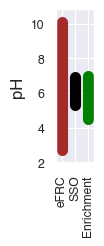

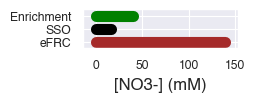

In [3]:
#Let's make a brief summary figure describing the field conditions; parts for Figure S1
#These data are hardcoded, don't change.

sns.set_style('darkgrid')
mpl.rcParams['font.family'] = 'Helvetica'

plt.figure(figsize=(.5,2)) #initialize the plots and make them small
plt.plot(['eFRC','eFRC'],[2.7,10.1],color='Brown',linewidth=8) #upper and lower pH values at the eFRC as a whole
plt.plot(['SSO','SSO'],[5.3,6.9],color='Black',linewidth=8) #upper and lower pH values at the SSO; check with co-authors for reference/methods; currently unpublished data
plt.plot(['Enrichment','Enrichment'],[4.5,7],color='Green',linewidth=8) #upper and lower pH values of the enrichment media
plt.ylabel('pH',fontsize=12)
plt.xticks(rotation=90)
plt.margins(x=0.25, y=0.1) #reduce excess spacing in plots
#plt.savefig('F1A_Field_comparison_pH.pdf',dpi=300,bbox_inches='tight') #save them as pdf parts to be assembled with adobe illustrator
plt.show() 

plt.figure(figsize=(2,.5))
plt.plot([.006,139],['eFRC','eFRC'],color='Brown',linewidth=8) #upper and lower [NO3-] values at the eFRC as a whole
plt.plot([0.03,16],['SSO','SSO'],color='Black',linewidth=8) #2024 pilot time series data for max; check with co-authors for reference/methods; currently unpublished data
plt.plot([0,40],['Enrichment','Enrichment'],color='Green',linewidth=8) #upper and lower [NO3-] values of the enrichment media
plt.xlabel('[NO3-] (mM)',fontsize=12)
plt.margins(x=0.1, y=0.25)
#plt.savefig('F1B_Field_comparison_no3.pdf',dpi=300,bbox_inches='tight')
plt.show()

In [4]:
#Import the metagenomic coverage data into dataframes

#Use the Q2Q3 coverage data generated by anvi-summary from the contigs.db for the metagenome with the manual_bins collection
bin_abunds_df = pd.read_csv('./data/mean_coverage_Q2Q3.txt',sep='\t',index_col='bins') #read the coverage tsv into a pandas dataframe
bin_order = ['Bin_1','Bin_2','Bin_3','Bin_4','Bin_5','Bin_6','Bin_7','Bin_8','Bin_9','Bin_10','Bin_11','Bin_12','Bin_13',
             'Bin_14','Bin_15','Bin_16','Bin_17','Bin_18','Bin_19','Bin_20','Bin_21','Bin_22','Bin_23','Bin_24','Bin_25',
             'Bin_26','Bin_27','Bin_28','Bin_29','Bin_30','Bin_31','Bin_32','Bin_33','Bin_34','Bin_35','Bin_36','Bin_37',
             'Bin_38','Bin_39','Bin_40','Bin_41'] #these get out of order b/c numbers and strings are weird, so put them in order manually
bin_abunds_df = bin_abunds_df.reindex(bin_order) #reorder the rows so it works with the desired order
#Take a peek at the data; looks like it's all there
bin_abunds_df

,NLDM_T1_A1,NLDM_T1_A2,NLDM_T1_A3,NLDM_T1_A4,NLDM_T1_A5,NLDM_T1_A6,NLDM_T1_A7,NLDM_T1_A8,NLDM_T1_B1,NLDM_T1_B2,...,SGW_T3_H11,SGW_T3_H12,SGW_T3_H2,SGW_T3_H3,SGW_T3_H4,SGW_T3_H5,SGW_T3_H6,SGW_T3_H7,SGW_T3_H8,SGW_T3_H9
bins,,,,,,,,,,,,,,,,,,,,,
Bin_1,4.693395,0.246516,0.145388,0.197378,0.149286,0.086062,15.450627,29.786401,0.074371,3.793438,...,0.020653,21.131790,0.772005,12.788279,21.462934,3.267888,1.657753,0.775878,3.977884,10.352153
Bin_2,0.667084,0.027239,0.012211,0.024515,0.011832,0.001720,0.002933,0.017197,0.023794,0.002395,...,0.000327,2.958731,0.354479,0.674492,0.004424,0.440524,0.236831,0.155833,1.001072,0.769872
Bin_3,0.000605,0.004498,0.002719,0.007344,0.001643,0.003894,0.007318,0.004715,0.004639,0.002186,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_4,0.847893,0.015245,0.001829,0.043876,0.013965,0.001656,0.610377,9.880620,0.018988,0.490234,...,0.000806,0.951943,0.000000,0.060731,0.466039,0.014181,0.003753,0.012108,0.002614,0.063521
Bin_5,0.000000,0.000000,0.000510,0.000829,0.000000,0.002131,0.000000,0.000000,0.000000,0.000000,...,0.064654,0.041445,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_6,0.118681,1.283489,1.705947,1.804376,0.102548,2.670122,3.720148,0.901776,2.353882,1.094271,...,0.000000,0.000000,0.000000,0.002051,0.345425,0.000000,0.001910,0.000000,0.000000,0.000000
Bin_7,0.004973,0.003622,0.004160,0.004910,0.000681,0.011158,0.000000,0.000021,0.007310,0.000758,...,0.005381,0.012423,0.000000,0.000683,0.001451,0.184078,0.024782,0.000000,0.000000,0.000000
Bin_8,0.000967,0.000359,0.007097,0.004212,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_9,0.000000,0.000000,0.005704,0.000747,0.000000,0.001207,0.000506,0.013829,0.000000,0.000000,...,0.005253,1.742740,0.002762,0.000721,0.000000,0.000000,0.000138,0.000000,0.002448,0.003891


In [5]:
#This would be even more interesting with metadata and taxonomy
sample_info_df = pd.read_csv('./data/EnCom_all_sample_info_misc_data_layer.txt' ,sep='\t') #includes sample timepoint, media, C source, pH, and [NO3-]; also used for adding metadata to anvio profile.db

#Sort the samples by C source to get the best grouping of variables and to keep things tidy. Use a cheeky replace, sort, replace method. It's stupid but it works, so...
sample_info_df = sample_info_df.replace({'NLDM':'1 NLDM','glucose':'2 glucose','acetate':'3 acetate','citrate':'4 citrate','lactate':'5 lactate','pyruvate':'6 pyruvate','no C':'7 no C'}).sort_values(['Media','Timepoint','C source','pH','[NO3]']).replace({'1 NLDM':'NLDM','2 glucose':'glucose','3 acetate':'acetate','4 citrate':'citrate','5 lactate':'lactate','6 pyruvate':'pyruvate','7 no C':'no C'}) #Replace C with numbers to sort, then change the names back
sample_order = sample_info_df['samples'].to_list()

#Now change the column order for the bin_abunds_df to match the sample info grouping
bin_abunds_df = bin_abunds_df[sample_order]

#Import metadata for each bin from Anvi'o
bin_info_df = pd.read_csv('./data/bins_summary.txt',sep='\t',index_col='bins') #includes taxonomy and completeness information. Use the genus level taxonomy since species is too sparse.
bin_info_df = bin_info_df.reindex(bin_order) #make sure this is in the same order as the bin_abund_df
bin_info_df #Display the bin stats. Some of these look excellent! Few contigs, high N50, and high completion for a bunch!

,total_length,num_contigs,N50,GC_content,percent_completion,percent_redundancy,t_domain,t_phylum,t_class,t_order,t_family,t_genus,t_species
bins,,,,,,,,,,,,,
Bin_1,6246117,7,3464359,60.649328,98.591549,7.042254,Bacteria,Pseudomonadota,Alphaproteobacteria,Rhizobiales,Rhizobiaceae,Neorhizobium,Neorhizobium petrolearium
Bin_2,5104585,4,3166414,63.190120,98.591549,4.225352,Bacteria,Pseudomonadota,Alphaproteobacteria,Rhizobiales,Rhizobiaceae,Allorhizobium,Allorhizobium ferrooxidans
Bin_3,5067647,2,4473157,36.922008,100.000000,4.225352,Bacteria,Bacillota,Bacilli,Bacillales,Planococcaceae,Lysinibacillus,NaN
Bin_4,1118256,45,99992,59.265870,0.000000,0.000000,Bacteria,Pseudomonadota,Alphaproteobacteria,Rhizobiales,Rhizobiaceae,Neorhizobium,NaN
Bin_5,6571898,42,299186,38.226496,97.183099,4.225352,Bacteria,Bacillota,Bacilli,Bacillales,DSM-18226,Robertmurraya,NaN
Bin_6,7987958,91,261660,66.432415,57.746479,30.985915,Bacteria,Actinomycetota,Actinomycetia,Actinomycetales,Micrococcaceae,Arthrobacter,NaN
Bin_7,5399471,12,803784,63.542055,97.183099,32.394366,Bacteria,Actinomycetota,Actinomycetia,Actinomycetales,Micrococcaceae,Paenarthrobacter,NaN
Bin_8,5256600,5,4849139,42.361658,100.000000,2.816901,Bacteria,Bacillota,Bacilli,Bacillales,DSM-18226,Mesobacillus,NaN
Bin_9,7031583,68,775358,71.512907,95.774648,43.661972,Bacteria,Actinomycetota,Actinomycetia,Propionibacteriales,Nocardioidaceae,Nocardioides,Nocardioides sp024509035


In [6]:
#Use CheckM data (from KBase) to get list of bins above a completeness threshold that we can trust enough to call MAGs
checkM_df = pd.read_csv('./data/CheckM_summary_table.tsv',sep='\t')
checkM_df['bin_id'] = checkM_df['Bin Name'].str.split('-',expand=True)[0] #slice the bin_id back out from the CheckM data to match with other dfs

percent_completion_threshold = 50 #Checking which bins are high-quality MAGs; using 50 for community correlations and 90 for metabolism

good_bin_list = checkM_df[checkM_df['Completeness']>=percent_completion_threshold]['bin_id'].to_list()
print(good_bin_list)

['Bin_1', 'Bin_10', 'Bin_11', 'Bin_12', 'Bin_13', 'Bin_14', 'Bin_15', 'Bin_16', 'Bin_18', 'Bin_2', 'Bin_20', 'Bin_21', 'Bin_22', 'Bin_3', 'Bin_37', 'Bin_39', 'Bin_40', 'Bin_41', 'Bin_5', 'Bin_6', 'Bin_7', 'Bin_8', 'Bin_9']


In [7]:
#Let's make a relative abundance version of the data
bin_abunds_df_rel = bin_abunds_df.div(bin_abunds_df.sum()).mul(100) #divide each column by its sum and multiply each value by 100 to get % rel abundance
bin_abunds_df_rel

,NLDM_T1_A1,NLDM_T1_A8,NLDM_T1_B1,NLDM_T1_B8,NLDM_T1_A2,NLDM_T1_B2,NLDM_T1_A3,NLDM_T1_B3,NLDM_T1_A4,NLDM_T1_B4,...,SGW_T3_C1,SGW_T3_B1,SGW_T3_A7,SGW_T3_H7,SGW_T3_G7,SGW_T3_F7,SGW_T3_E7,SGW_T3_D7,SGW_T3_C7,SGW_T3_B7
bins,,,,,,,,,,,,,,,,,,,,,
Bin_1,72.121125,45.163018,1.510660,56.845212,10.077789,62.227292,3.621737,52.298565,5.758894,59.037005,...,50.606570,61.523872,89.939022,80.571581,58.888666,57.694206,36.055487,26.684902,25.379653,56.499155
Bin_2,10.250763,0.026074,0.483326,5.215345,1.113569,0.039284,0.304185,0.001095,0.715273,0.039701,...,33.319867,36.205373,7.576200,16.182554,40.247738,39.636171,60.199269,70.711041,71.726583,37.751659
Bin_3,0.009296,0.007149,0.094237,0.023037,0.183880,0.035852,0.067734,0.532492,0.214261,0.328314,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_4,13.029160,14.981287,0.385704,30.035744,0.623230,8.041769,0.045572,1.600022,1.280184,12.837330,...,0.000000,0.000000,0.422320,1.257333,0.646956,1.073007,0.563670,0.460396,0.586928,0.295213
Bin_5,0.000000,0.000000,0.000000,0.002699,0.000000,0.000000,0.012706,0.000000,0.024196,0.000157,...,0.033457,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.003561,0.000000,0.000000
Bin_6,1.823717,1.367300,47.813492,0.907056,52.470092,17.950339,42.496644,27.640140,52.646266,15.935625,...,0.170183,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_7,0.076416,0.000033,0.148488,0.090724,0.148056,0.012438,0.103621,1.480964,0.143259,2.369547,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_8,0.014865,0.000000,0.000000,0.005601,0.014695,0.000000,0.176802,0.000000,0.122885,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Bin_9,0.000000,0.020967,0.000000,0.000000,0.000000,0.000000,0.142097,0.000769,0.021797,0.011881,...,0.049843,2.174376,1.806217,0.000000,0.036533,0.000000,0.315523,0.125913,0.081897,0.640113


In [8]:
#Relabel and restructure the bin_abunds_df for relative abundance calculations at the genus level
#Let's add the genus info column to the bin_abunds_df_rel and then set it as the index so you can see genera in the relative abundance figure legend
bin_abunds_df_rel_genera = bin_abunds_df_rel.copy() #make a copy so we can use the rel abund df later with the bin names

bin_abunds_df_rel_genera['Genus'] = bin_info_df['t_genus'].fillna('Unclassified').to_list() #the index is the same, so the order should match when adding this column

bin_abunds_df_rel_genera = bin_abunds_df_rel_genera.set_index('Genus') #Set the genus as the index now; we will remake the raw bin_abunds df later since this obscures the bin_ids
#Since the genus is the index now, the order matters a little less. Let's sort it so that repeat genera are next to each other for better colormapping
bin_abunds_df_rel_genera = bin_abunds_df_rel_genera.sort_index()

bin_abunds_df_rel_genera

,NLDM_T1_A1,NLDM_T1_A8,NLDM_T1_B1,NLDM_T1_B8,NLDM_T1_A2,NLDM_T1_B2,NLDM_T1_A3,NLDM_T1_B3,NLDM_T1_A4,NLDM_T1_B4,...,SGW_T3_C1,SGW_T3_B1,SGW_T3_A7,SGW_T3_H7,SGW_T3_G7,SGW_T3_F7,SGW_T3_E7,SGW_T3_D7,SGW_T3_C7,SGW_T3_B7
Genus,,,,,,,,,,,,,,,,,,,,,
Aeromicrobium,0.000000,0.000000,0.000000,0.000406,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000461,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Allorhizobium,10.250763,0.026074,0.483326,5.215345,1.113569,0.039284,0.304185,0.001095,0.715273,0.039701,...,33.319867,36.205373,7.576200,16.182554,40.247738,39.636171,60.199269,70.711041,71.726583,37.751659
Arthrobacter,0.000000,0.002165,0.160609,0.000000,0.174495,0.085152,0.346802,0.021323,0.028928,0.014997,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Arthrobacter,0.000000,0.015375,0.603990,0.015150,0.548790,0.452549,0.411361,0.453197,0.575528,0.458992,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Arthrobacter,1.823717,1.367300,47.813492,0.907056,52.470092,17.950339,42.496644,27.640140,52.646266,15.935625,...,0.170183,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Arthrobacter,0.000000,0.049592,0.237967,0.000000,0.035077,0.073095,0.293898,0.004372,0.011819,0.012297,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Arthrobacter,1.478947,0.742407,28.048019,0.557893,21.817626,6.826583,39.701575,10.958701,19.875713,6.083112,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Arthrobacter,0.011828,0.016292,0.149037,0.001490,0.198255,0.133395,0.073517,0.068008,0.031088,0.047832,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Arthrobacter,0.019922,33.695250,0.052007,0.095210,0.102196,0.019897,0.062714,0.005958,0.002485,0.765408,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [9]:
#Before the plots are made, let's make some palettes so the colors are consistent; genera in the keys of this dict are for both bins (GTDB) and ASV data (Silva)
#xkcd palette: https://xkcd.com/color/rgb/
genus_pal = {'Aeromicrobium':'xkcd:sky blue',
             'Janibacter':'xkcd:goldenrod',
             'Ciceribacter':'xkcd:grey blue',
             'Paenarthrobacter':'xkcd:mustard', 
             'Paenisporosarcina':'xkcd:beige', 
             'Allorhizobium':'xkcd:grey blue', 
             'Arthrobacter':'xkcd:rust', 
             'Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium':'xkcd:light olive', #closest field relative for Neorhizobium AND Allorhizobium
             'Paraburkholderia':'xkcd:reddish brown',
             'Burkholderia-Caballeronia-Paraburkholderia':'xkcd:reddish brown',
             'Streptomyces':'xkcd:yellowish green',
             'Microbacterium':'xkcd:cream',
             'Neobacillus':'xkcd:lavender',
             'Lysinibacillus':'xkcd:dark lavender', 
             'Edaphobaculum':'xkcd:ochre', 
             'Bacillaceae':'xkcd:grape', 
             'Bacillus':'xkcd:light violet', #In general, the Bacilliceae are shades of purple
             'Flavipsychrobacter':'xkcd:pale blue', 
             'Robertmurraya':'xkcd:light purple', 
             'Mesobacillus':'xkcd:orchid', 
             'Nocardioides':'xkcd:charcoal', 
             'Cellulomonas':'xkcd:puce', 
             'Unclassified':'xkcd:grey', 
             #'Micrococcaceae':'xkcd:terra cotta', #These two class assignments were the best Anvi'o originally did for a couple bins, but I dug deeper and found genus assignments for each
             #'Opitutaceae':'xkcd:light mauve',
             'Neorhizobium':'xkcd:light olive', 
             'Fictibacillus_C':'xkcd:periwinkle blue',
             'Fictibacillus':'xkcd:periwinkle blue', 
             'Bacillus_A':'xkcd:light violet', 
             'Paenibacillus':'xkcd:faded purple',
             'Intrasporangiaceae':'xkcd:green blue',
             'Lacunisphaera':'xkcd:light mauve'}

#Make a palette for when the data is labelled by bin so it matches the appropriate genus
bin_pal = {
 'Bin_1':genus_pal['Neorhizobium'],
 'Bin_2':genus_pal['Allorhizobium'],
 'Bin_3':genus_pal['Lysinibacillus'],
 'Bin_4':genus_pal['Neorhizobium'],
 'Bin_5':genus_pal['Robertmurraya'],
 'Bin_6':genus_pal['Arthrobacter'],
 'Bin_7':genus_pal['Paenarthrobacter'],
 'Bin_8':genus_pal['Mesobacillus'],
 'Bin_9':genus_pal['Nocardioides'],
 'Bin_10':genus_pal['Lacunisphaera'],
 'Bin_11':genus_pal['Arthrobacter'],
 'Bin_12':genus_pal['Arthrobacter'],
 'Bin_13':genus_pal['Paraburkholderia'],
 'Bin_14':genus_pal['Bacillus'],
 'Bin_15':genus_pal['Arthrobacter'],
 'Bin_16':genus_pal['Janibacter'],
 'Bin_17':genus_pal['Unclassified'],
 'Bin_18':genus_pal['Arthrobacter'],
 'Bin_19':genus_pal['Arthrobacter'],
 'Bin_20':genus_pal['Flavipsychrobacter'],
 'Bin_21':genus_pal['Fictibacillus'],
 'Bin_22':genus_pal['Cellulomonas'],
 'Bin_23':genus_pal['Unclassified'],
 'Bin_24':genus_pal['Unclassified'],
 'Bin_25':genus_pal['Arthrobacter'],
 'Bin_26':genus_pal['Aeromicrobium'],
 'Bin_27':genus_pal['Bacillus'],
 'Bin_28':genus_pal['Arthrobacter'],
 'Bin_29':genus_pal['Nocardioides'],
 'Bin_30':genus_pal['Nocardioides'],
 'Bin_31':genus_pal['Streptomyces'],
 'Bin_32':genus_pal['Streptomyces'],
 'Bin_33':genus_pal['Unclassified'],
 'Bin_34':genus_pal['Neobacillus'],
 'Bin_35':genus_pal['Paenibacillus'],
 'Bin_36':genus_pal['Robertmurraya'],
 'Bin_37':genus_pal['Microbacterium'],
 'Bin_38':genus_pal['Unclassified'],
 'Bin_39':genus_pal['Nocardioides'],
 'Bin_40':genus_pal['Nocardioides'],
 'Bin_41':genus_pal['Arthrobacter']
}

#this is a palette dict of just the genera represented by only the bins
bin_genus_pal = {
 'Aeromicrobium': 'xkcd:sky blue',
 'Janibacter': 'xkcd:goldenrod',
 'Paenarthrobacter': 'xkcd:mustard',
 'Allorhizobium': 'xkcd:grey blue',
 'Arthrobacter': 'xkcd:rust',
 'Paraburkholderia': 'xkcd:reddish brown',
 'Streptomyces': 'xkcd:yellowish green',
 'Microbacterium': 'xkcd:cream',
 'Neobacillus': 'xkcd:lavender',
 'Lysinibacillus': 'xkcd:dark lavender',
 'Bacillus': 'xkcd:light violet',
 'Flavipsychrobacter': 'xkcd:pale blue',
 'Robertmurraya': 'xkcd:light purple',
 'Mesobacillus': 'xkcd:orchid',
 'Nocardioides': 'xkcd:charcoal',
 'Cellulomonas': 'xkcd:puce',
 'Unclassified': 'xkcd:grey',
 'Lacunisphaera': 'xkcd:light mauve',
 'Neorhizobium': 'xkcd:light olive',
 'Fictibacillus_C': 'xkcd:periwinkle blue',
 'Bacillus_A': 'xkcd:blurple',
 'Paenibacillus': 'xkcd:faded purple'
}

#Dict matching basic bin_id to genus
bin_genus_dict = {
 'Bin_1':'Neorhizobium',
 'Bin_2':'Allorhizobium',
 'Bin_3':'Lysinibacillus',
 'Bin_4':'Neorhizobium',
 'Bin_5':'Robertmurraya',
 'Bin_6':'Arthrobacter',
 'Bin_7':'Paenarthrobacter',
 'Bin_8':'Mesobacillus',
 'Bin_9':'Nocardioides',
 'Bin_10':'Lacunisphaera',
 'Bin_11':'Arthrobacter',
 'Bin_12':'Arthrobacter',
 'Bin_13':'Paraburkholderia',
 'Bin_14':'Bacillus',
 'Bin_15':'Arthrobacter',
 'Bin_16':'Janibacter',
 'Bin_17':'Unclassified',
 'Bin_18':'Arthrobacter',
 'Bin_19':'Arthrobacter',
 'Bin_20':'Flavipsychrobacter',
 'Bin_21':'Fictibacillus',
 'Bin_22':'Cellulomonas',
 'Bin_23':'Unclassified',
 'Bin_24':'Unclassified',
 'Bin_25':'Arthrobacter',
 'Bin_26':'Aeromicrobium',
 'Bin_27':'Bacillus',
 'Bin_28':'Arthrobacter',
 'Bin_29':'Nocardioides',
 'Bin_30':'Nocardioides',
 'Bin_31':'Streptomyces',
 'Bin_32':'Streptomyces',
 'Bin_33':'Unclassified',
 'Bin_34':'Neobacillus',
 'Bin_35':'Paenibacillus',
 'Bin_36':'Robertmurraya',
 'Bin_37':'Microbacterium',
 'Bin_38':'Unclassified',
 'Bin_39':'Nocardioides',
 'Bin_40':'Nocardioides',
 'Bin_41':'Arthrobacter'
}

#These are the slightly less cryptic bin names that include the first four letters of the generic names
#Use this dict to relabel dfs and such
bin_label_rename_dict = {
 'Bin_1':'Neor 1',
 'Bin_2':'Allo 2',
 'Bin_3':'Lysi 3',
 'Bin_4':'Neor 4',
 'Bin_5':'Robe 5',
 'Bin_6':'Arth 6',
 'Bin_7':'Paen 7',
 'Bin_8':'Meso 8',
 'Bin_9':'Noca 9',
 'Bin_10':'Lacu 10',
 'Bin_11':'Arth 11',
 'Bin_12':'Arth 12',
 'Bin_13':'Para 13',
 'Bin_14':'Baci 14',
 'Bin_15':'Arth 15',
 'Bin_16':'Jani 16',
 'Bin_17':'17', #no taxonomy assignment
 'Bin_18':'Arth 18',
 'Bin_19':'Arth 19',
 'Bin_20':'Flav 20',
 'Bin_21':'Fict 21',
 'Bin_22':'Cell 22',
 'Bin_23':'23', #no taxonomy assignment
 'Bin_24':'24', #no taxonomy assignment
 'Bin_25':'Arth 25',
 'Bin_26':'Aero 26',
 'Bin_27':'Baci 27',
 'Bin_28':'Arth 28',
 'Bin_29':'Noca 29',
 'Bin_30':'Noca 30',
 'Bin_31':'Stre 31',
 'Bin_32':'Stre 32',
 'Bin_33':'33', #no taxonomy assignment
 'Bin_34':'Neob 34',
 'Bin_35':'Paen 35',
 'Bin_36':'Robe 36',
 'Bin_37':'Micr 37',
 'Bin_38':'38', #no taxonomy assignment
 'Bin_39':'Noca 39',
 'Bin_40':'Noca 40',
 'Bin_41':'Arth 41'
}

#Color paletters to keep variable colors consistent
pH_palette = {4.5:'xkcd:tangerine',6:'xkcd:moss',7:'xkcd:cerulean'}

no3_palette = 'Blues'

c_palette = {
    'acetate':'xkcd:turquoise',
    'glucose':'xkcd:olive',
    'citrate':'xkcd:peach',
    'pyruvate':'xkcd:crimson',
    'lactate':'xkcd:beige',
    'no C':'xkcd:grey',
    'NLDM':'xkcd:light brown'
}

#add a column to sample_info_df to give the C sources a numerical ID so it can be plotted as a heatmap for the bar plot figure
c_id_dict = {'no C': 0, #no C is the base SGW medium with no added C substrate
 'pyruvate': 1,
 'lactate': 2,
 'citrate': 3,
 'acetate': 4,
 'glucose': 5,
 'NLDM': 6}

#Also need a cmap list to match the colors to the C sources based on numerical order
c_colors = ['xkcd:grey','xkcd:crimson','xkcd:beige','xkcd:peach','xkcd:turquoise','xkcd:olive','xkcd:light brown']

media_pal = {'NLDM':'xkcd:tan','SGW':'xkcd:pale blue'}

sample_info_df['C_ID'] = sample_info_df['C source'].map(c_id_dict)

#df of all of the colors named with hex codes for the xkcd palette; might be useful
#xkcd_color_df = pd.read_csv('../xkcd_colors.txt',sep='\t',names=['color','hex']) #from here: https://xkcd.com/color/rgb/

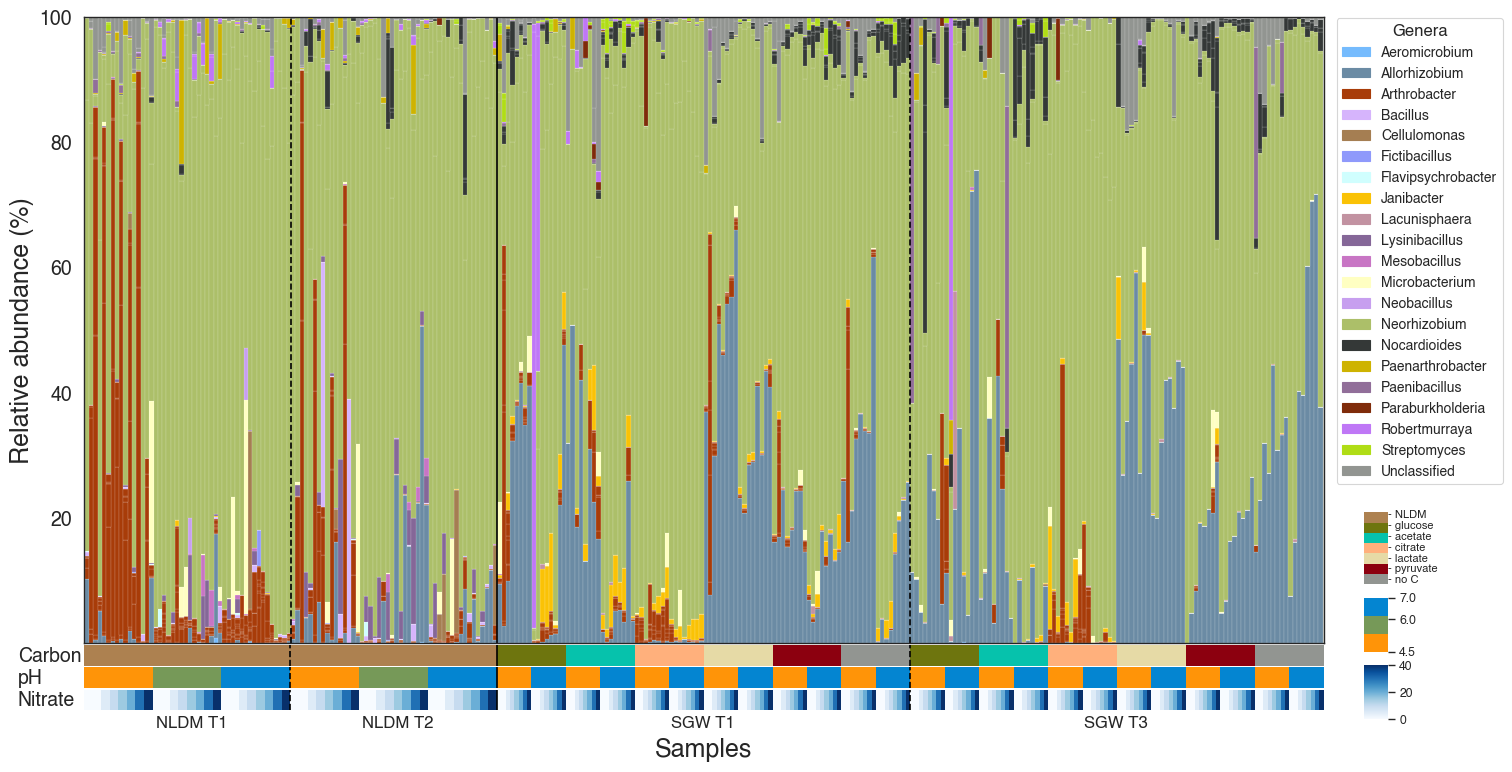

In [10]:
#This is an early version of the relative abundance bar plot. A more easily interpretable version is below.

#Generate the relative abundance bar plot along with relevant metadata to be Figure 1D
#Note: Figure 1 cirle phylogram was generated using anvi-interactive with the contigs.db and profile.db and 
#setting the color for each "manual bin" in cirlce phylogram to the hex code for the genus palette then exported as an svg and converted to pdf to be combined in Adobe Illustrator.

sns.set_style('white') #background style from seaborn
mpl.rcParams['font.family'] = 'Helvetica' #reset the font because sns.set_style() changes it
fig,ax = plt.subplots(ncols=1,nrows=4,figsize=(16,9),height_ratios=[4.55,.15,.15,.15]) #create the subplot grid and scale the axes

bin_abunds_df_rel_genera.T.plot(kind='bar',stacked=True,width=1,color=genus_pal,linewidth=0.1,ax=ax[0]) #This is the bar plot, df.plot() does a great job for stacked bar charts

handles,labels = ax[0].get_legend_handles_labels() #Get the genera names to create a custom legend

genus_legend_handles = [] #This list becomes the custom legend
for genus in sorted(set(labels)): #get each genus
    handle = mpatches.Patch(color=genus_pal[genus], label=f'{genus}') #create a label and colored bar for it using the palette set above
    genus_legend_handles.append(handle) #put it in the list

ax[0].legend(handles=genus_legend_handles,loc=1,bbox_to_anchor=(1.15,1.01),title='Genera',fontsize=10,title_fontsize=12) #Create the legend
#ax[0].set_title('Relative abundance of EnCom bins',fontsize=20,pad=15)
ax[0].set_title('')

#Create vertical lines to separate timepoints and media
ax[0].axvline(47.5,color='black',ls='--')
ax[0].axvline(95.5,color='black',ls='-')
ax[0].axvline(191.5,color='black',ls='--')
ax[0].set_xticks([])
ax[0].set_yticks([20,40,60,80,100],labels=[20,40,60,80,100],fontsize=14) #set yticks explicitly
ax[0].set_ylabel('Relative abundance (%)',fontsize=18)
ax[0].set_facecolor('xkcd:light grey')

#labels for media timepoints
ax[0].text(16,-13.5,'NLDM T1',fontsize=12)
ax[0].text(64,-13.5,'NLDM T2',fontsize=12)
ax[0].text(136,-13.5,'SGW T1',fontsize=12)
ax[0].text(232,-13.5,'SGW T3',fontsize=12)

#Create axes for the legends for the metadata for go under the legend for the rel abund plot
cbar_ax1 = fig.add_subplot([.925,.25,.015,.08])
cbar_ax2 = fig.add_subplot([.925,.175,.015,.06])
cbar_ax3 = fig.add_subplot([.925,.1,.015,.06])

#carbon source plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df['C_ID']).T,cmap=c_colors,ax=ax[1],yticklabels=False,cbar=True,cbar_ax=cbar_ax1)
#carbon source legend
cbar_ax1.set_yticks([])
cbar_ax1.text(1,0.1,'- no C',fontsize=8) #very manually setting tick labels; adjust in illustrator
cbar_ax1.text(1,1,'- pyruvate',fontsize=8)
cbar_ax1.text(1,1.9,'- lactate',fontsize=8)
cbar_ax1.text(1,2.8,'- citrate',fontsize=8)
cbar_ax1.text(1,3.7,'- acetate',fontsize=8)
cbar_ax1.text(1,4.6,'- glucose',fontsize=8)
cbar_ax1.text(1,5.5,'- NLDM',fontsize=8)
ax[1].axvline(48,color='black',ls='--')
ax[1].axvline(96,color='black',ls='-')
ax[1].axvline(192,color='black',ls='--')
ax[1].set_xticks([])
ax[1].set_ylabel('Carbon',fontsize=14,labelpad=47.5,rotation=0,loc='bottom')
ax[1].set_facecolor('xkcd:light grey')

#pH plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df['pH']).T,cmap=['xkcd:tangerine','xkcd:moss','xkcd:cerulean'],ax=ax[2],yticklabels=False,cbar=True,cbar_ax=cbar_ax2)
#pH legend
cbar_ax2.set_yticks([4.5,6,7])
ax[2].axvline(48,color='black',ls='--')
ax[2].axvline(96,color='black',ls='-')
ax[2].axvline(192,color='black',ls='--')
ax[2].set_xticks([])
ax[2].set_ylabel('pH',fontsize=14,labelpad=47.5,rotation=0,loc='bottom')
ax[2].set_facecolor('xkcd:light grey')

#[NO3-] plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df['[NO3]']).T,cmap='Blues',ax=ax[3],yticklabels=False,cbar=True,cbar_ax=cbar_ax3)
#[NO3-] legend
cbar_ax3.set_yticks([0,20,40])
ax[3].axvline(48,color='black',ls='--')
ax[3].axvline(96,color='black',ls='-')
ax[3].axvline(192,color='black',ls='--')
ax[3].set_xticks([])
ax[3].set_ylabel('Nitrate',fontsize=14,labelpad=47.5,rotation=0,loc='bottom')
ax[3].set_facecolor('xkcd:light grey')

#Create an x axis label for everything
ax[3].set_xlabel('Samples',fontsize=18,labelpad=20)

#Put all the subplots close together
plt.subplots_adjust(hspace=0.01)

#Save the image as a pdf to be added to the full image in Adobe Illustrator
#plt.savefig('../figs/Fig1D_EnCom_all_relabund.pdf',dpi=300,bbox_inches='tight')
plt.show()

In [11]:
#how many bins are >1% on average in NLDM?
(bin_abunds_df_rel_genera[[col for col in bin_abunds_df_rel_genera.columns if 'NLDM' in col]]>1).sum().median()

np.float64(5.0)

In [12]:
#how many bins are >1% on average in SGW (not NLDM)?
(bin_abunds_df_rel_genera[[col for col in bin_abunds_df_rel_genera.columns if 'NLDM' not in col]]>1).sum().median()

np.float64(4.0)

In [13]:
#Is that a statistical difference? Run a t-test
ttest_ind((bin_abunds_df_rel_genera[[col for col in bin_abunds_df_rel_genera.columns if 'NLDM' in col]]>1).sum(),
          (bin_abunds_df_rel_genera[[col for col in bin_abunds_df_rel_genera.columns if 'NLDM' not in col]]>1).sum(),
          equal_var=False) #different length of lists between media

TtestResult(statistic=np.float64(2.5232402650989827), pvalue=np.float64(0.012369583806603104), df=np.float64(209.71190808011684))

In [14]:
#On average how abundant are Robertmurraya and Nocardioides? Testing this comparison specifically for link-comm / metabolic pathway comparisons
bin_abunds_df_rel_genera.loc[['Robertmurraya','Nocardioides']].groupby(by='Genus').aggregate('sum').sort_values(by='Robertmurraya',ascending=False,axis=1).T[0:15].mean()

Genus
Nocardioides      0.448670
Robertmurraya    17.017625
dtype: float64

In [15]:
#What are the top 15 conditions where Robertmurraya is most abundant?
sample_info_df[sample_info_df['samples'].isin(bin_abunds_df_rel_genera.loc['Robertmurraya'].sum().sort_values(ascending=False).index[0:15])]

,samples,Timepoint,Media,pH,C source,[NO3],C_ID
24,NLDM_T1_D1,T1,NLDM,6.0,NLDM,0,6
25,NLDM_T1_D2,T1,NLDM,6.0,NLDM,5,6
27,NLDM_T1_D4,T1,NLDM,6.0,NLDM,15,6
20,NLDM_T1_C5,T1,NLDM,6.0,NLDM,20,6
28,NLDM_T1_D5,T1,NLDM,6.0,NLDM,20,6
29,NLDM_T1_D6,T1,NLDM,6.0,NLDM,30,6
44,NLDM_T1_F5,T1,NLDM,7.0,NLDM,20,6
69,NLDM_T2_C6,T2,NLDM,6.0,NLDM,30,6
103,SGW_T1_A8,T1,SGW,7.0,glucose,0,5
187,SGW_T1_H8,T1,SGW,7.0,glucose,0,5


In [16]:
#What are the top 15 conditions where Nocardioides is most abundant? Notice these are mostly later, differnet pH, and different C than Robertmurraya
sample_info_df[sample_info_df['samples'].isin(bin_abunds_df_rel_genera.loc['Nocardioides'].sum().sort_values(ascending=False).index[0:15])]

,samples,Timepoint,Media,pH,C source,[NO3],C_ID
66,NLDM_T2_C3,T2,NLDM,6.0,NLDM,10,6
74,NLDM_T2_D3,T2,NLDM,6.0,NLDM,10,6
83,NLDM_T2_E4,T2,NLDM,7.0,NLDM,15,6
121,SGW_T1_C2,T1,SGW,4.5,glucose,10,5
256,SGW_T3_F5,T3,SGW,4.5,glucose,10,5
202,SGW_T3_A11,T3,SGW,7.0,glucose,0,5
203,SGW_T3_A12,T3,SGW,7.0,acetate,0,4
287,SGW_T3_H12,T3,SGW,7.0,acetate,0,4
263,SGW_T3_F12,T3,SGW,7.0,acetate,10,4
251,SGW_T3_E12,T3,SGW,7.0,acetate,15,4


In [17]:
#What's this weirdo with very low similarity and overlap with the rest of the MAGs doing in here? I still don't really know, mostly just sample NLDM_C8. Life's just random sometimes.
display(bin_abunds_df_rel_genera.loc[['Flavipsychrobacter']][bin_abunds_df_rel_genera.loc[['Flavipsychrobacter']].groupby(by='Genus').aggregate('sum') > 0.1].dropna(axis=1))
print(f'{bin_abunds_df_rel_genera.loc[['Flavipsychrobacter']].groupby(by='Genus').aggregate('sum').T.mean()}')
display(sample_info_df[sample_info_df['samples'].isin(bin_abunds_df_rel_genera.loc[['Flavipsychrobacter']][bin_abunds_df_rel_genera.loc[['Flavipsychrobacter']].groupby(by='Genus').aggregate('sum') > 0.1].dropna(axis=1).columns)])

,NLDM_T1_B7,NLDM_T1_C8,NLDM_T1_F8,NLDM_T2_A7,NLDM_T2_C8
Genus,,,,,
Flavipsychrobacter,0.102856,2.776948,0.240347,0.270115,2.256433


Genus
Flavipsychrobacter    0.019876
dtype: float64


,samples,Timepoint,Media,pH,C source,[NO3],C_ID
14,NLDM_T1_B7,T1,NLDM,4.5,NLDM,40,6
23,NLDM_T1_C8,T1,NLDM,6.0,NLDM,0,6
47,NLDM_T1_F8,T1,NLDM,7.0,NLDM,0,6
54,NLDM_T2_A7,T2,NLDM,4.5,NLDM,40,6
71,NLDM_T2_C8,T2,NLDM,6.0,NLDM,0,6


In [18]:
#Just curious because Paenarthrobacter also skews low similarity and overlap with the rest of 'em
display(bin_abunds_df_rel_genera.loc[['Paenarthrobacter']][bin_abunds_df_rel_genera.loc[['Paenarthrobacter']].groupby(by='Genus').aggregate('sum') > 1].dropna(axis=1))
print(f'{bin_abunds_df_rel_genera.loc[['Paenarthrobacter']].groupby(by='Genus').aggregate('sum').T.mean()}')
display(sample_info_df[sample_info_df['samples'].isin(bin_abunds_df_rel_genera.loc[['Paenarthrobacter']][bin_abunds_df_rel_genera.loc[['Paenarthrobacter']].groupby(by='Genus').aggregate('sum') > 1].dropna(axis=1).columns)])

,NLDM_T1_B3,NLDM_T1_B4,NLDM_T1_B5,NLDM_T1_C3,NLDM_T1_C6,NLDM_T1_D7,NLDM_T1_F7,NLDM_T2_B3,NLDM_T2_B4,NLDM_T2_B5,...,NLDM_T2_C6,NLDM_T2_F7,SGW_T1_A2,SGW_T1_E8,SGW_T1_H1,SGW_T1_A5,SGW_T3_H5,SGW_T3_G5,SGW_T3_H11,SGW_T3_H6
Genus,,,,,,,,,,,,,,,,,,,,,
Paenarthrobacter,1.480964,2.369547,1.422108,22.992393,8.920384,8.888857,1.604411,4.496814,4.485421,1.768223,...,11.052206,1.042184,4.251835,2.185807,5.149165,1.289012,4.27304,2.781597,5.35923,1.168462


Genus
Paenarthrobacter    0.38755
dtype: float64


,samples,Timepoint,Media,pH,C source,[NO3],C_ID
10,NLDM_T1_B3,T1,NLDM,4.5,NLDM,10,6
11,NLDM_T1_B4,T1,NLDM,4.5,NLDM,15,6
12,NLDM_T1_B5,T1,NLDM,4.5,NLDM,20,6
18,NLDM_T1_C3,T1,NLDM,6.0,NLDM,10,6
21,NLDM_T1_C6,T1,NLDM,6.0,NLDM,30,6
30,NLDM_T1_D7,T1,NLDM,6.0,NLDM,40,6
46,NLDM_T1_F7,T1,NLDM,7.0,NLDM,40,6
58,NLDM_T2_B3,T2,NLDM,4.5,NLDM,10,6
59,NLDM_T2_B4,T2,NLDM,4.5,NLDM,15,6
60,NLDM_T2_B5,T2,NLDM,4.5,NLDM,20,6


In [19]:
#List the genera in order of highest relative abundance on average, use for legend order
g_order_avg_abund = list(bin_abunds_df_rel_genera.groupby(by='Genus').aggregate('sum').mean(axis=1).sort_values(ascending=False).index)
g_order_avg_abund

['Neorhizobium',
 'Allorhizobium',
 'Arthrobacter',
 'Unclassified',
 'Nocardioides',
 'Robertmurraya',
 'Microbacterium',
 'Janibacter',
 'Paenibacillus',
 'Lysinibacillus',
 'Paenarthrobacter',
 'Bacillus',
 'Cellulomonas',
 'Streptomyces',
 'Paraburkholderia',
 'Lacunisphaera',
 'Mesobacillus',
 'Neobacillus',
 'Fictibacillus',
 'Flavipsychrobacter',
 'Aeromicrobium']

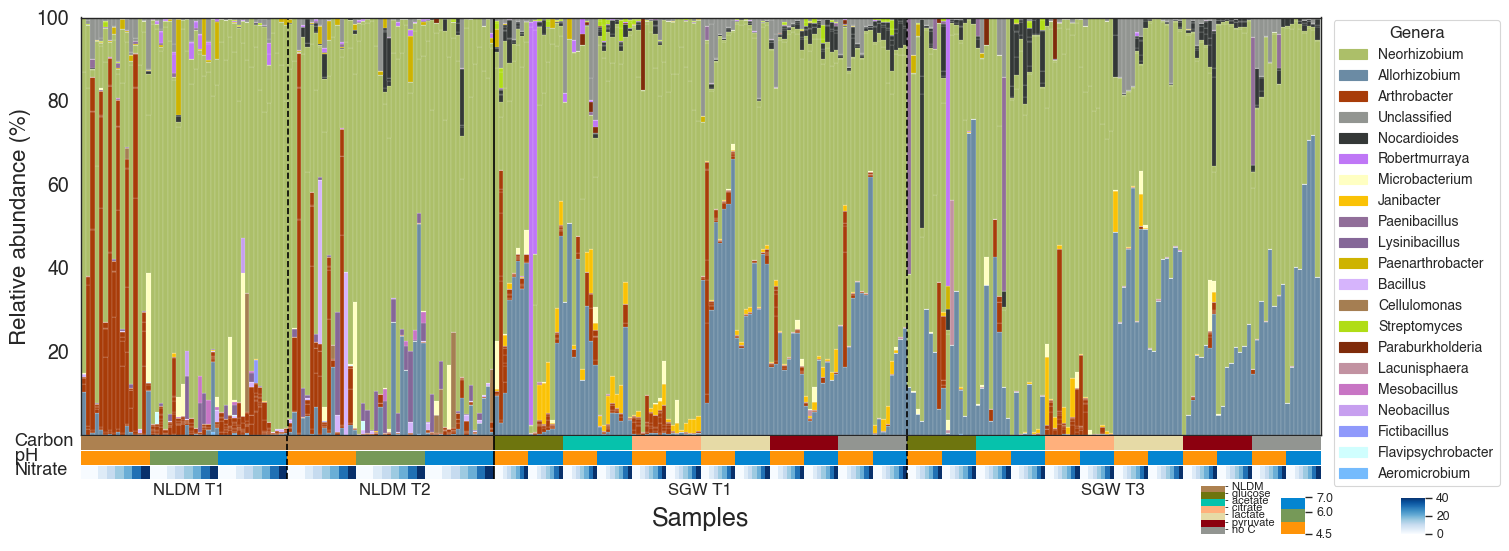

In [20]:
#This is just an attempt to shrink the figure above to see if that helps. 
#Unneccessary here, but I'm leaving it

sns.set_style('white') #background style from seaborn
mpl.rcParams['font.family'] = 'Helvetica' #reset the font because sns.set_style() changes it
fig,ax = plt.subplots(ncols=1,nrows=4,figsize=(16,6),height_ratios=[4.55,.15,.15,.15]) #create the subplot grid and scale the axes

bin_abunds_df_rel_genera.T.plot(kind='bar',stacked=True,width=1,color=genus_pal,linewidth=0.1,ax=ax[0]) #This is the bar plot, df.plot() does a great job for stacked bar charts

handles,labels = ax[0].get_legend_handles_labels() #Get the genera names to create a custom legend

genus_legend_handles = [] #This list becomes the custom legend
for genus in g_order_avg_abund: #get each genus from most to least abundant on average
    handle = mpatches.Patch(color=genus_pal[genus], label=f'{genus}') #create a label and colored bar for it using the palette set above
    genus_legend_handles.append(handle) #put it in the list

ax[0].legend(handles=genus_legend_handles,loc=1,bbox_to_anchor=(1.15,1.01),title='Genera',fontsize=10,title_fontsize=12) #Create the legend
#ax[0].set_title('Relative abundance of EnCom bins',fontsize=20,pad=15)
ax[0].set_title('')

#Create vertical lines to separate timepoints and media
ax[0].axvline(47.5,color='black',ls='--')
ax[0].axvline(95.5,color='black',ls='-')
ax[0].axvline(191.5,color='black',ls='--')
ax[0].set_xticks([])
ax[0].set_yticks([20,40,60,80,100],labels=[20,40,60,80,100],fontsize=14) #set yticks explicitly
ax[0].set_ylabel('Relative abundance (%)',fontsize=16)
ax[0].set_facecolor('xkcd:light grey')

#labels for media timepoints
ax[0].text(16,-14.5,'NLDM T1',fontsize=12)
ax[0].text(64,-14.5,'NLDM T2',fontsize=12)
ax[0].text(136,-14.5,'SGW T1',fontsize=12)
ax[0].text(232,-14.5,'SGW T3',fontsize=12)

#Create axes for the legends for the metadata for go under the legend for the rel abund plot
cbar_ax1 = fig.add_subplot([.825,.02,.015,.08])
cbar_ax2 = fig.add_subplot([.875,.02,.015,.06])
cbar_ax3 = fig.add_subplot([.95,.02,.015,.06])

#carbon source plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df['C_ID']).T,cmap=c_colors,ax=ax[1],yticklabels=False,cbar=True,cbar_ax=cbar_ax1)
#carbon source legend
cbar_ax1.set_yticks([])
cbar_ax1.text(1,0.1,'- no C',fontsize=8) #very manually setting tick labels; adjust in illustrator
cbar_ax1.text(1,1,'- pyruvate',fontsize=8)
cbar_ax1.text(1,1.9,'- lactate',fontsize=8)
cbar_ax1.text(1,2.8,'- citrate',fontsize=8)
cbar_ax1.text(1,3.7,'- acetate',fontsize=8)
cbar_ax1.text(1,4.6,'- glucose',fontsize=8)
cbar_ax1.text(1,5.5,'- NLDM',fontsize=8)
ax[1].axvline(48,color='black',ls='--')
ax[1].axvline(96,color='black',ls='-')
ax[1].axvline(192,color='black',ls='--')
ax[1].set_xticks([])
ax[1].set_ylabel('Carbon',fontsize=13,labelpad=47.5,rotation=0,loc='bottom')
ax[1].set_facecolor('xkcd:light grey')

#pH plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df['pH']).T,cmap=['xkcd:tangerine','xkcd:moss','xkcd:cerulean'],ax=ax[2],yticklabels=False,cbar=True,cbar_ax=cbar_ax2)
#pH legend
cbar_ax2.set_yticks([4.5,6,7])
ax[2].axvline(48,color='black',ls='--')
ax[2].axvline(96,color='black',ls='-')
ax[2].axvline(192,color='black',ls='--')
ax[2].set_xticks([])
ax[2].set_ylabel('pH',fontsize=13,labelpad=47.5,rotation=0,loc='bottom')
ax[2].set_facecolor('xkcd:light grey')

#[NO3-] plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df['[NO3]']).T,cmap='Blues',ax=ax[3],yticklabels=False,cbar=True,cbar_ax=cbar_ax3)
#[NO3-] legend
cbar_ax3.set_yticks([0,20,40])
ax[3].axvline(48,color='black',ls='--')
ax[3].axvline(96,color='black',ls='-')
ax[3].axvline(192,color='black',ls='--')
ax[3].set_xticks([])
ax[3].set_ylabel('Nitrate',fontsize=13,labelpad=47.5,rotation=0,loc='bottom')
ax[3].set_facecolor('xkcd:light grey')

#Create an x axis label for everything
ax[3].set_xlabel('Samples',fontsize=18,labelpad=20)

#Put all the subplots close together
plt.subplots_adjust(hspace=0.01)

#Save the image as a pdf to be added to the full image in Adobe Illustrator
#plt.savefig('../figs/Fig1D_EnCom_all_relabund.pdf',dpi=300,bbox_inches='tight')
plt.show()

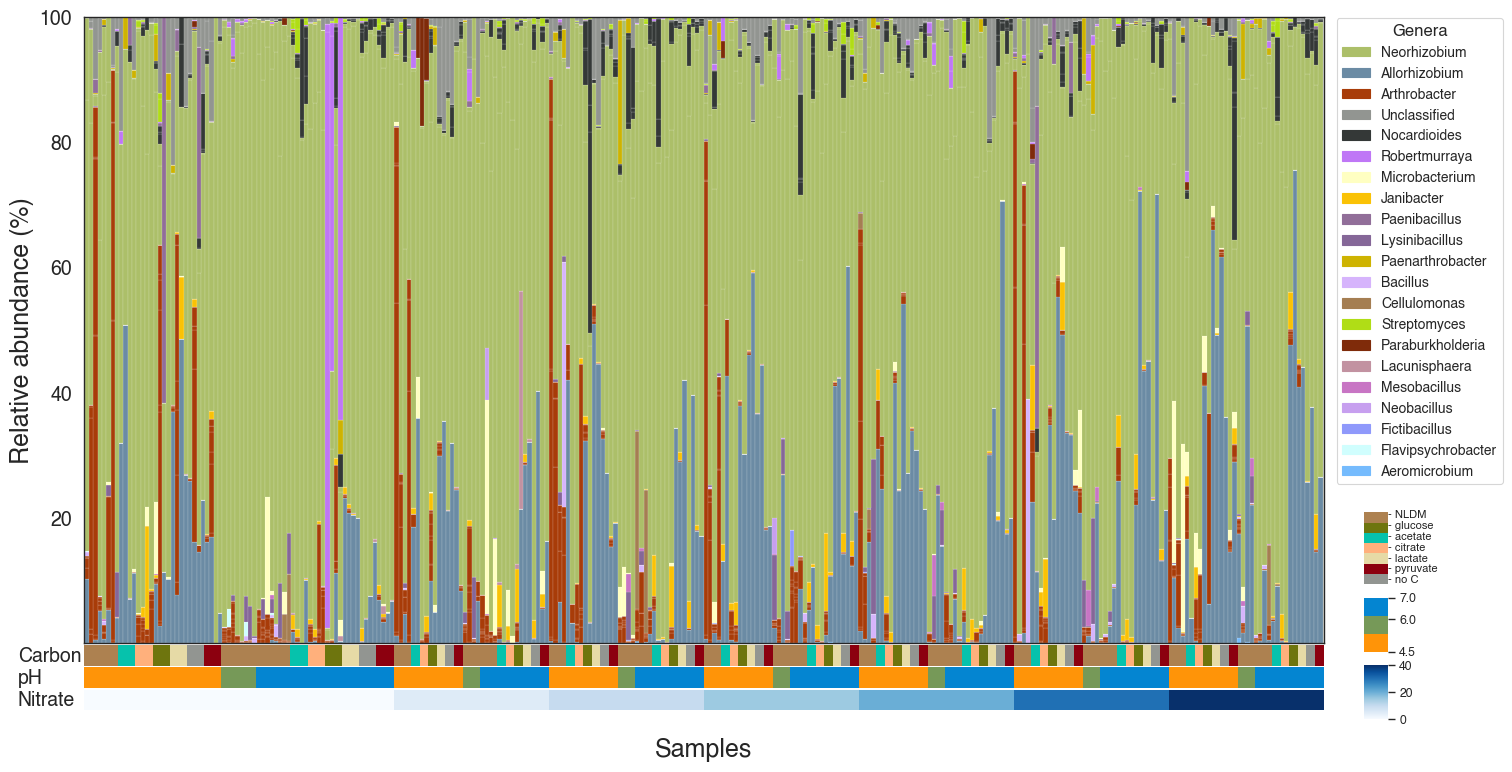

In [21]:
#Do it again but this time sorted by NO3-
#I could have made this a function, but I didn't and it's not really worth it now

#Reorder by conditions

sort_var = ['[NO3]','pH','C source','Timepoint']

condition_sample_order = sample_info_df.sort_values(by=sort_var).samples

sns.set_style('white') #background style from seaborn
mpl.rcParams['font.family'] = 'Helvetica' #reset the font because sns.set_style() changes it
fig,ax = plt.subplots(ncols=1,nrows=4,figsize=(16,9),height_ratios=[4.55,.15,.15,.15]) #create the subplot grid and scale the axes

bin_abunds_df_rel_genera[condition_sample_order].T.plot(kind='bar',stacked=True,width=1,color=genus_pal,linewidth=0.1,ax=ax[0]) #This is the bar plot, df.plot() does a great job for stacked bar charts

handles,labels = ax[0].get_legend_handles_labels() #Get the genera names to create a custom legend

genus_legend_handles = [] #This list becomes the custom legend
for genus in g_order_avg_abund: #get each genus
    handle = mpatches.Patch(color=genus_pal[genus], label=f'{genus}') #create a label and colored bar for it using the palette set above
    genus_legend_handles.append(handle) #put it in the list

ax[0].legend(handles=genus_legend_handles,loc=1,bbox_to_anchor=(1.15,1.01),title='Genera',fontsize=10,title_fontsize=12) #Create the legend

ax[0].set_title('')

ax[0].set_xticks([])
ax[0].set_yticks([20,40,60,80,100],labels=[20,40,60,80,100],fontsize=14) #set yticks explicitly
ax[0].set_ylabel('Relative abundance (%)',fontsize=18)
ax[0].set_facecolor('xkcd:light grey')

#Create axes for the legends for the metadata for go under the legend for the rel abund plot
cbar_ax1 = fig.add_subplot([.925,.25,.015,.08])
cbar_ax2 = fig.add_subplot([.925,.175,.015,.06])
cbar_ax3 = fig.add_subplot([.925,.1,.015,.06])

#carbon source plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df.sort_values(by=sort_var)['C_ID']).T,cmap=c_colors,ax=ax[1],yticklabels=False,cbar=True,cbar_ax=cbar_ax1)
#carbon source legend
cbar_ax1.set_yticks([])
cbar_ax1.text(1,0.1,'- no C',fontsize=8) #very manually setting tick labels; adjust in illustrator
cbar_ax1.text(1,1,'- pyruvate',fontsize=8)
cbar_ax1.text(1,1.9,'- lactate',fontsize=8)
cbar_ax1.text(1,2.8,'- citrate',fontsize=8)
cbar_ax1.text(1,3.7,'- acetate',fontsize=8)
cbar_ax1.text(1,4.6,'- glucose',fontsize=8)
cbar_ax1.text(1,5.5,'- NLDM',fontsize=8)
ax[1].set_xticks([])
ax[1].set_ylabel('Carbon',fontsize=14,labelpad=47.5,rotation=0,loc='bottom')
ax[1].set_facecolor('xkcd:light grey')

#pH plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df.sort_values(by=sort_var)['pH']).T,cmap=['xkcd:tangerine','xkcd:moss','xkcd:cerulean'],ax=ax[2],yticklabels=False,cbar=True,cbar_ax=cbar_ax2)
#pH legend
cbar_ax2.set_yticks([4.5,6,7])
ax[2].set_xticks([])
ax[2].set_ylabel('pH',fontsize=14,labelpad=47.5,rotation=0,loc='bottom')
ax[2].set_facecolor('xkcd:light grey')

#[NO3-] plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df.sort_values(by=sort_var)['[NO3]']).T,cmap='Blues',ax=ax[3],yticklabels=False,cbar=True,cbar_ax=cbar_ax3)
#[NO3-] legend
cbar_ax3.set_yticks([0,20,40])
ax[3].set_xticks([])
ax[3].set_ylabel('Nitrate',fontsize=14,labelpad=47.5,rotation=0,loc='bottom')
ax[3].set_facecolor('xkcd:light grey')

#Create an x axis label for everything
ax[3].set_xlabel('Samples',fontsize=18,labelpad=20)

#Put all the subplots close together
plt.subplots_adjust(hspace=0.01)

#Save the image as a pdf to be added to the full image in Adobe Illustrator
#plt.savefig('../figs/Fig1D_EnCom_all_relabund.pdf',dpi=300,bbox_inches='tight')
plt.show()

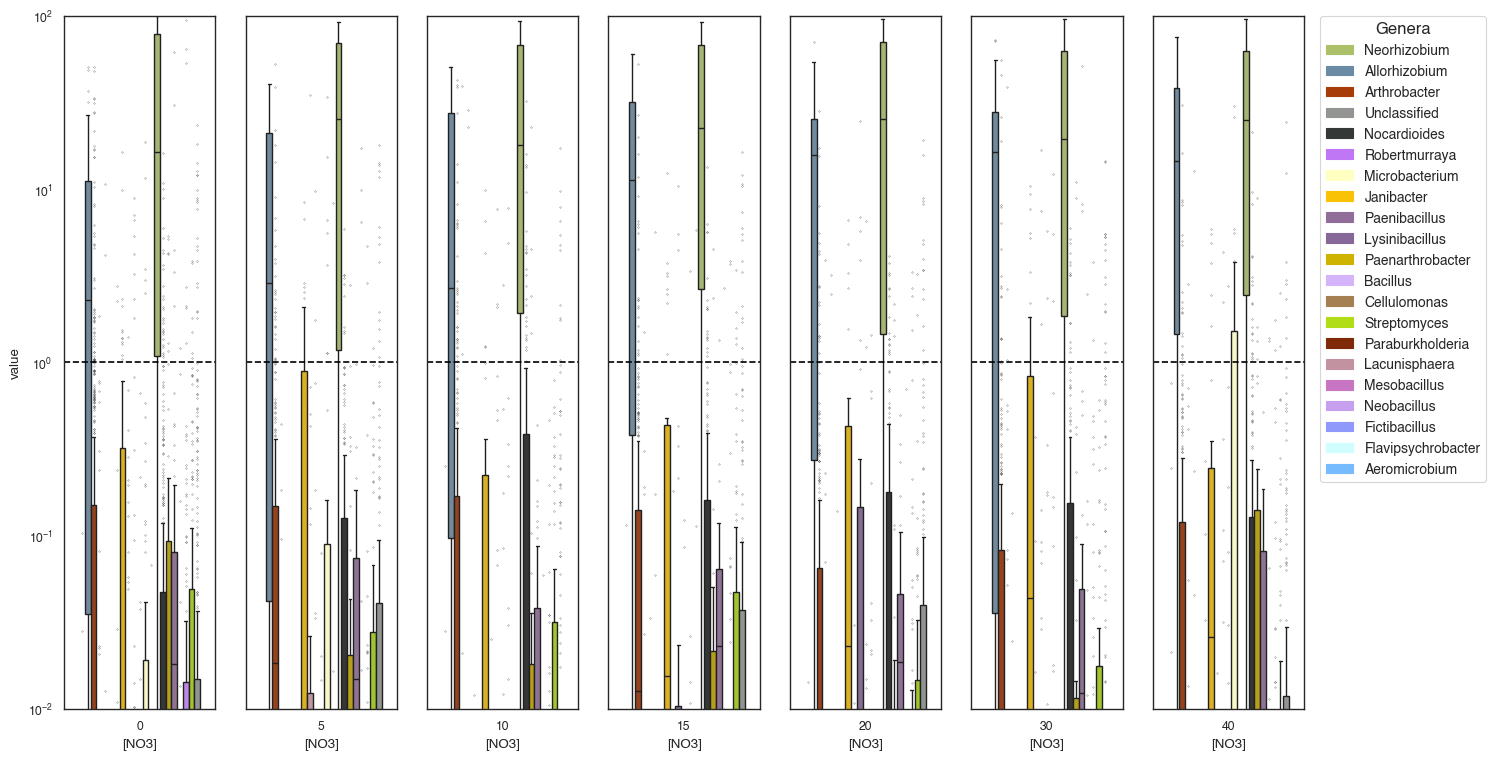

In [22]:
#Is the abundance visualization better with boxplots? Not really but it was worth a shot

#Melt the data to use with seaborn
bin_abunds_df_rel_genera_melt = bin_abunds_df_rel_genera.reset_index().melt(id_vars='Genus').rename({'variable':'samples'},axis=1).merge(sample_info_df,how='left',on='samples')

def plot_rel_abund_boxes(condition=None,log=False):

    vars = bin_abunds_df_rel_genera_melt[condition].unique()
    n_vars = len(vars)

    fig,ax=plt.subplots(figsize=(16,9),ncols=n_vars,sharey=True)

    for i in range(n_vars):
        axis = ax[i]
        sns.boxplot(bin_abunds_df_rel_genera_melt[bin_abunds_df_rel_genera_melt[condition]==vars[i]],
                    x=condition,y='value',hue='Genus',palette=genus_pal,
                    fliersize=0.2,ax=axis)
        axis.set_ylim(1e-2,100)
        axis.axhline(1,color='black',linestyle='--')
        if i < n_vars-1:
            axis.get_legend().remove()

    handles,labels = ax[n_vars-1].get_legend_handles_labels() #Get the genera names to create a custom legend

    genus_legend_handles = [] #This list becomes the custom legend
    for genus in g_order_avg_abund: #get each genus
        handle = mpatches.Patch(color=genus_pal[genus], label=f'{genus}') #create a label and colored bar for it using the palette set above
        genus_legend_handles.append(handle) #put it in the list

    ax[n_vars-1].legend(handles=genus_legend_handles,loc=1,bbox_to_anchor=(2.25,1.01),title='Genera',fontsize=10,title_fontsize=12) #Create the legend
    if log==True:
        plt.yscale('log')
    plt.show()

plot_rel_abund_boxes(condition='[NO3]',log=True)

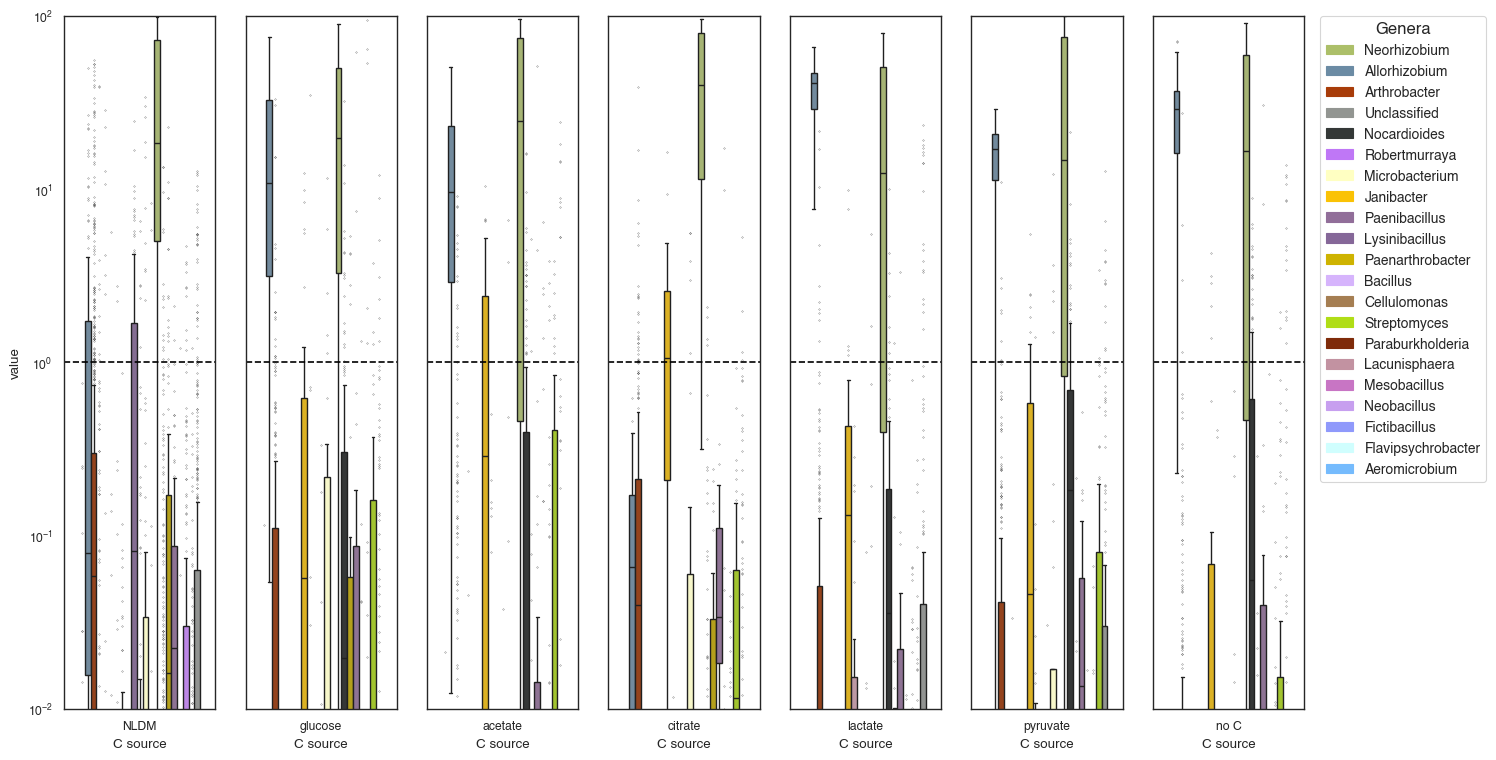

In [23]:
plot_rel_abund_boxes(condition='C source',log=True)

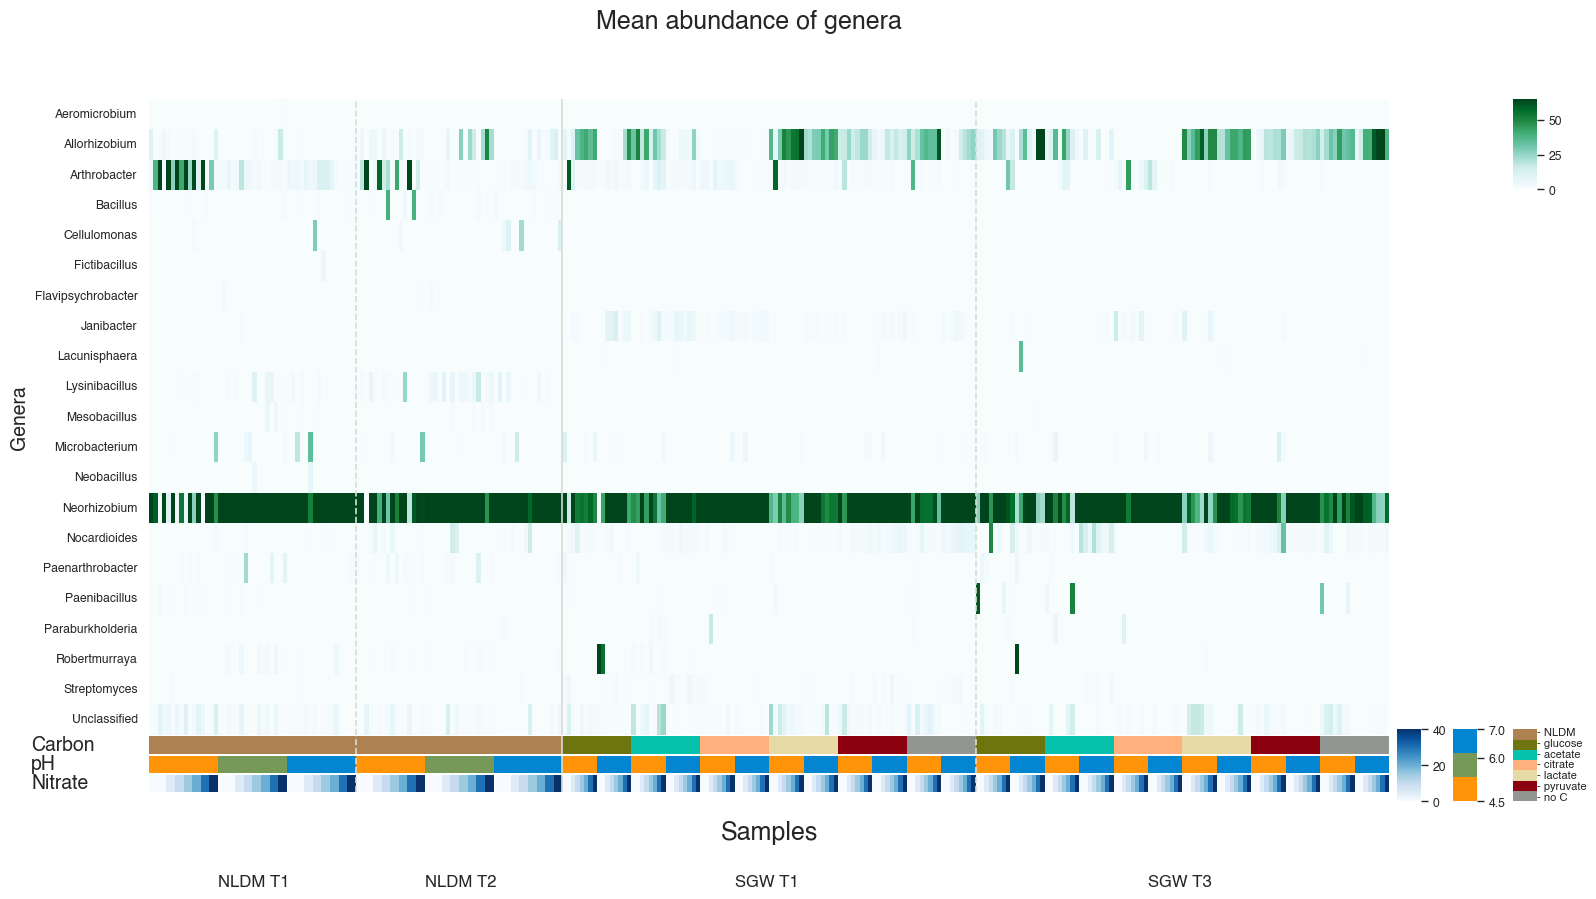

In [24]:
#Make a figure plotting the relative abundance but using a heatmap this time
#Spoiler: It isn't better. It's just not easy to display relative abundance with so many samples when their are just two dominant populations skewing everything

#Set up the plot
fig,ax = plt.subplots(ncols=1,nrows=4,figsize=(16,9),height_ratios=[4.55,.125,.125,.125])

cbar_ax0 = fig.add_subplot([.9775,.78,.015,.1]) #additional axis for the colorbar where we want it

sns.heatmap(bin_abunds_df_rel_genera.groupby(bin_abunds_df_rel_genera.index).sum(),cmap='BuGn',vmax=65,xticklabels=True,yticklabels=True,ax=ax[0],cbar=True,cbar_ax=cbar_ax0) #plot the data

#label the axes correctly
ax[0].set_ylabel('Genera',fontsize=14)
ax[0].set_xticks([])
ax[0].axvline(48,color='xkcd:light grey',ls='--') #add these lines to separate the media and time points
ax[0].axvline(96,color='xkcd:light grey',ls='-')
ax[0].axvline(192,color='xkcd:light grey',ls='--')
ax[0].text(16,26,'NLDM T1',fontsize=12)
ax[0].text(64,26,'NLDM T2',fontsize=12)
ax[0].text(136,26,'SGW T1',fontsize=12)
ax[0].text(232,26,'SGW T3',fontsize=12)
ax[0].set_facecolor('xkcd:light grey') #set the background to grey so that the genes with no data are grey

#colorbars for C, pH, and NO3-
cbar_ax1 = fig.add_subplot([.9775,.1,.015,.08])
cbar_ax2 = fig.add_subplot([.94,.1,.015,.08])
cbar_ax3 = fig.add_subplot([.905,.1,.015,.08])


#plot the C
sns.heatmap(pd.DataFrame(sample_info_df['C_ID']).T,cmap=c_colors,ax=ax[1],yticklabels=False,cbar=True,cbar_ax=cbar_ax1)
cbar_ax1.set_yticks([])
cbar_ax1.text(1,0.1,'- no C',fontsize=8)
cbar_ax1.text(1,1,'- pyruvate',fontsize=8)
cbar_ax1.text(1,1.9,'- lactate',fontsize=8)
cbar_ax1.text(1,2.8,'- citrate',fontsize=8)
cbar_ax1.text(1,3.7,'- acetate',fontsize=8)
cbar_ax1.text(1,4.6,'- glucose',fontsize=8)
cbar_ax1.text(1,5.5,'- NLDM',fontsize=8)
ax[1].axvline(48,color='xkcd:light grey',ls='--')
ax[1].axvline(96,color='xkcd:light grey',ls='-')
ax[1].axvline(192,color='xkcd:light grey',ls='--')
ax[1].set_xticks([])
ax[1].set_ylabel('Carbon',fontsize=14,labelpad=85,rotation=0,loc='bottom')
ax[1].set_facecolor('xkcd:light grey')

#plot the pH
sns.heatmap(pd.DataFrame(sample_info_df['pH']).T,cmap=['xkcd:tangerine','xkcd:moss','xkcd:cerulean'],ax=ax[2],yticklabels=False,cbar=True,cbar_ax=cbar_ax2)
cbar_ax2.set_yticks([4.5,6,7])
ax[2].axvline(48,color='xkcd:light grey',ls='--')
ax[2].axvline(96,color='xkcd:light grey',ls='-')
ax[2].axvline(192,color='xkcd:light grey',ls='--')
ax[2].set_xticks([])
ax[2].set_ylabel('pH',fontsize=14,labelpad=85,rotation=0,loc='bottom')
ax[2].set_facecolor('xkcd:light grey')

#plot the NO3
sns.heatmap(pd.DataFrame(sample_info_df['[NO3]']).T,cmap='Blues',ax=ax[3],yticklabels=False,cbar=True,cbar_ax=cbar_ax3)
cbar_ax3.set_yticks([0,20,40])
ax[3].axvline(48,color='xkcd:light grey',ls='--')
ax[3].axvline(96,color='xkcd:light grey',ls='-')
ax[3].axvline(192,color='xkcd:light grey',ls='--')
ax[3].set_xticks([])
ax[3].set_ylabel('Nitrate',fontsize=14,labelpad=85,rotation=0,loc='bottom')
ax[3].set_facecolor('xkcd:light grey')

ax[3].set_xlabel('Samples',fontsize=18,labelpad=20)

plt.suptitle('Mean abundance of genera',fontsize=18)

plt.subplots_adjust(hspace=0.01)

plt.show()

In [25]:
#Compare to abundances of taxa in field data from the eFRC CPT campaign and the SSO (M6 sediment only)
#There is a lot of data in here that I am NOT going to cover because the CPT data has already been published, and other more depth analyses on the rest of the SSO data are in progress elsewhere

#How well are we covering genera from the field?
#Check the 16S rel abund data from the field

#ASV table
df_eFRC_abund = pd.read_csv('./data/eFRC_field_ASV_abund.csv')

#Convert to relative abundance
df_field_ASV_abunds_rel = df_eFRC_abund.set_index('ASVID').div(df_eFRC_abund.set_index('ASVID').sum()).mul(100)

#Taxonomy assignments for each ASV ID
field_ASV_class_df = pd.read_csv('./data/eFRC_ASV_classification.csv')
#Create a dictionary mapping each ASVID to its corresponding genus assignment
ASV_g_dict = dict(zip(field_ASV_class_df.ASVID,field_ASV_class_df.Genus))

#Create a Genus column to use as the index
df_field_ASV_abunds_rel['Genus'] = df_field_ASV_abunds_rel.reset_index()['ASVID'].map(ASV_g_dict).to_list()
df_field_ASV_abunds_rel.set_index('Genus',inplace=True)

#Combine the abundance of ASVs of the same genus, like we did with the bins
df_field_ASV_abunds_rel_grouped = df_field_ASV_abunds_rel.groupby(df_field_ASV_abunds_rel.index).aggregate('sum')
df_field_ASV_abunds_rel_grouped

,CPT26S.A,CPT26S.B,CPT26S.C,CPT10S.A,CPT10S.B,CPT10S.C,CPT19S.A,CPT19S.B,CPT21S.B,CPT21S.C,...,CPT52S.A,CPT52S.B,CPT69S.A,CPT69S.B,CPT65S.A,CPT65S.B,SSO.M6.C3,SSO.M6.C5,SSO.M6.C7,SSO.M6.C10
Genus,,,,,,,,,,,,,,,,,,,,,
01D2Z36,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
0319-6G20,0.256812,0.390804,0.371297,0.059948,1.333911,0.290254,0.007657,0.078530,0.045920,0.282734,...,0.141022,0.192138,0.615638,0.138151,0.168360,0.311955,0.009603,0.000000,0.00000,0.000000
0319-7L14,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.020675,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.069666,0.000000,0.009603,0.000000,0.00000,0.000000
053A03-B-DI-P58,0.000000,0.000000,0.000000,0.000000,0.000000,0.064925,0.000000,0.039265,0.000000,0.000000,...,0.000000,0.000000,0.010304,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
1013-28-CG33,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.005122,0.000000,0.00000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s3t2d-1089,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
type_III,0.000000,0.000000,0.027359,0.000000,0.000000,0.000000,0.000000,0.000000,0.282078,0.024705,...,0.312264,0.000000,0.014167,0.111583,0.000000,0.055051,0.000000,0.000000,0.00000,0.000000
uncultured,7.358318,4.011900,6.468381,13.132097,2.906927,7.947602,11.652820,1.602010,8.324587,4.671974,...,6.295643,3.858001,3.217289,5.919235,2.583454,5.034101,6.196662,4.554106,4.17126,1.448764


In [26]:
#Abundance of genus Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium (closest relative to Neo and Allorhizobium; checked by 16S seq BLAST) in SSO M6 sediment
df_field_ASV_abunds_rel_grouped[[i for i in df_field_ASV_abunds_rel_grouped.columns if 'M6' in i]].loc[df_field_ASV_abunds_rel_grouped.index=='Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium']

,SSO.M6.C3,SSO.M6.C5,SSO.M6.C7,SSO.M6.C10
Genus,,,,
Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium,1.443049,0.0,0.0,0.07372


In [27]:
#Abundance of enrichment genera in the sample closest to the inoculum source; the 0s are probably just below the detection limit or are in C2 but not C3. 
#This list is based off of 16S seqs from MAGs matching with genera in the field data (RDP taxonomy)
df_field_ASV_abunds_rel_grouped[[i for i in df_field_ASV_abunds_rel_grouped.columns if 'M6.C3' in i]].loc[df_field_ASV_abunds_rel_grouped.index.isin(genus_pal.keys())].mean(axis=1).sort_values(ascending=False)

Genus
Unclassified                                          47.700660
Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium     1.443049
Cellulomonas                                           0.146610
Paenibacillus                                          0.121641
Nocardioides                                           0.117800
Bacillus                                               0.099874
Streptomyces                                           0.096033
Microbacterium                                         0.009603
Edaphobaculum                                          0.007683
Paenisporosarcina                                      0.000000
Paenarthrobacter                                       0.000000
Aeromicrobium                                          0.000000
Lysinibacillus                                         0.000000
Ciceribacter                                           0.000000
Burkholderia-Caballeronia-Paraburkholderia             0.000000
Arthrobacter                      

In [28]:
#Print out some summaries of Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium across samples
Neo_Allo_Para_Rhizobia_CPT_abund = df_field_ASV_abunds_rel_grouped[[i for i in df_field_ASV_abunds_rel_grouped.columns if 'CPT' in i]].loc[df_field_ASV_abunds_rel_grouped.index=='Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium']#.mean(axis=1)
print(f'Mean abundance in CPT + M6.C3: \t {df_field_ASV_abunds_rel_grouped.loc[df_field_ASV_abunds_rel_grouped.index=='Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium'].mean(axis=1).iloc[0]:.6f}%')
print(f'Min abundance in CPT + M6.C3: \t {df_field_ASV_abunds_rel_grouped.loc[df_field_ASV_abunds_rel_grouped.index=='Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium'].min(axis=1).iloc[0]:.6f}%')
print(f'Max abundance in CPT + M6.C3: \t {df_field_ASV_abunds_rel_grouped.loc[df_field_ASV_abunds_rel_grouped.index=='Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium'].max(axis=1).iloc[0]:.6f}%')

Mean abundance in CPT + M6.C3: 	 0.598031%
Min abundance in CPT + M6.C3: 	 0.000000%
Max abundance in CPT + M6.C3: 	 1.958736%


In [29]:
#Check the mean abundance of enrichment genera in the field ASV data
df_field_ASV_abunds_rel_grouped[df_field_ASV_abunds_rel_grouped.index.isin(genus_pal.keys())].mean(axis=1)

Genus
Aeromicrobium                                          0.015585
Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium     0.598031
Arthrobacter                                           0.008728
Bacillus                                               7.202893
Burkholderia-Caballeronia-Paraburkholderia             0.509601
Cellulomonas                                           0.095819
Ciceribacter                                           0.149025
Edaphobaculum                                          0.112040
Lacunisphaera                                          0.034866
Lysinibacillus                                         0.374129
Microbacterium                                         0.000267
Nocardioides                                           0.202696
Paenarthrobacter                                       0.050085
Paenibacillus                                          0.418866
Paenisporosarcina                                      0.003161
Streptomyces                      

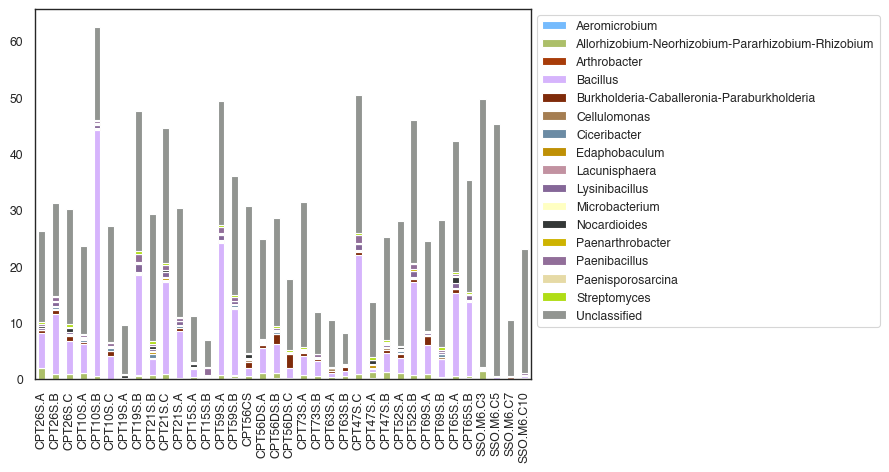

In [30]:
#Visualize the enrichment-relevant ASV genera in the field; lots of Bacillus in the CPT samples, but not so much in the SSO
df_field_ASV_abunds_rel_grouped[df_field_ASV_abunds_rel_grouped.index.isin(genus_pal.keys())].T.plot(kind='bar',stacked=True,color=genus_pal,legend=True)
plt.legend(bbox_to_anchor=(1,1))
plt.show()

In [31]:
#This function let's us identify the top bins and their average relative abundances for a specific carbon source at the later timepoint
def find_top_bins_by_c(c_source=None,cutoff=1):
    
    if c_source == None:
        raise ValueError(f'Please specify c_source from {list(c_palette.keys())}')

    print(c_source) #label for the output
    if c_source == 'NLDM': #NLDM has a different later timepoint than SGW (due to an issue in the lab, so we went with what we had), so we need to differentiate them
        c_df = sample_info_df[sample_info_df['Timepoint']=='T2'].loc[sample_info_df['C source']==c_source]
    elif c_source != 'NLDM':
        c_df = sample_info_df[sample_info_df['Timepoint']=='T3'].loc[sample_info_df['C source']==c_source]
    c_samples = c_df['samples'] #get the list of samples for the specified carbon source

    c_abund_df = bin_abunds_df_rel[c_samples].rename(bin_label_rename_dict) #slice the rel abund df
    c_mean_abunds = c_abund_df.mean(axis=1).sort_values(ascending=False) #calculate the mean for each bin and sort it

    print(c_mean_abunds[c_mean_abunds > cutoff]) #The cutoff is a percentage cutoff, so we only look at taxa above that abundance

#Check that the function works
find_top_bins_by_c(c_source='acetate',cutoff=0.5)

acetate
bins
Neor 1     73.018089
Allo 2     10.769308
Paen 35     3.499517
Noca 30     2.845184
Noca 9      2.011953
38          1.998252
Neor 4      1.785024
Noca 39     0.886238
Arth 41     0.568385
dtype: float64


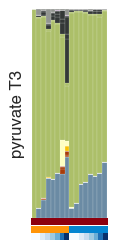

In [32]:
#For the correlation networks, the nodes are scaled by their relative abundance under the cross section of conditions selected.
#This function makes small plots for Figure 1. which help illustrate which genera are abundant for each C source.
def plot_late_C_subset(c_source=None,T='T1',save=False,label=True):
    
    if c_source == None: #Make sure function is called correctly with the available options
        raise ValueError(f'Please specify c_source from {list(c_palette.keys())}')

    #Get the samples just for this C and T
    c_df = sample_info_df[sample_info_df['Timepoint']==T].loc[sample_info_df['C source']==c_source]
    c_samples = c_df['samples']

    #There are 3X as many NLDM samples, so scale appropriately
    if c_source != 'NLDM':
        fs = (1,3)
    elif c_source == 'NLDM':
        fs = (3,3)
    
    #This is like a miniature unlabelled version of the big relative abundance plot
    fig,ax = plt.subplots(ncols=1,nrows=4,figsize=fs,height_ratios=[4.55,.15,.15,.15])
    bin_abunds_df_rel_genera[c_samples].T.plot(kind='bar',stacked=True,width=1,color=genus_pal,linewidth=0.1,ax=ax[0],legend=False)
    ax[0].set_xticks([])
    ax[0].set_xticks([])
    ax[0].set_yticks([])
    ax[0].spines['top'].set_visible(False)
    ax[0].spines['left'].set_visible(False)
    ax[0].spines['bottom'].set_visible(False)
    ax[0].spines['right'].set_visible(False)
    if label == True:
        ax[0].set_ylabel(f'{c_source} {T}',fontsize=12)
    elif label == False:
        ax[0].set_ylabel('')

    #Here, just make the facecolor the desired color for the carbon source since this is a single value for thes plots
    #sns.heatmap(pd.DataFrame(c_df['C_ID']).T,cmap=c_colors[::-1],ax=ax[1],yticklabels=False,cbar=False)
    ax[1].set_xticks([])
    ax[1].set_yticks([])
    ax[1].spines['top'].set_visible(False)
    ax[1].spines['left'].set_visible(False)
    ax[1].spines['bottom'].set_visible(False)
    ax[1].spines['right'].set_visible(False)
    ax[1].set_facecolor(c_palette[c_source])

    #Plot the pH and manually set the palette to match
    sns.heatmap(pd.DataFrame(c_df['pH']).T,cmap=['xkcd:tangerine','xkcd:moss','xkcd:cerulean'],ax=ax[2],yticklabels=False,cbar=False)
    ax[2].set_xticks([])

    #Plot the pH and manually set the palette to match ('Blues' is really close to the manual palette. I just needed a consistent categorical for some plots, but this works at this scale.)
    sns.heatmap(pd.DataFrame(c_df['[NO3]']).T,cmap='Blues',ax=ax[3],yticklabels=False,cbar=False)
    ax[3].set_xticks([])

    plt.subplots_adjust(hspace=0.01)
    if save == True:
        plt.savefig(f'../figs/abunds/rel_abund_{c_source}_{T}_tiny.pdf',dpi=300,bbox_inches='tight')
    plt.show()

#Example
plot_late_C_subset(c_source='pyruvate',T='T3')

In [33]:
#Make a set of functions here that improve on my previous relative abundance plots because we're going to make a facet grid for each C at each T
#It could have been this simple the whole time.
def plot_c_relabunds(c_source=None,T=None,ax=None):
    """Function to plot just the relative abundance chart for each carbon source at each timepoint"""
    
    if c_source == None: #Make sure function is called correctly with the available options
        raise ValueError(f'Please specify c_source from {list(c_palette.keys())}')

    #Get the samples just for this C and T
    c_df = sample_info_df[sample_info_df['Timepoint']==T].loc[sample_info_df['C source']==c_source]
    c_samples = c_df['samples']

    #There are 3X as many NLDM samples, so scale appropriately
    if c_source != 'NLDM':
        fs = (1,3)
    elif c_source == 'NLDM':
        fs = (3,3)

    bin_abunds_df_rel_genera[c_samples].T.plot(kind='bar',stacked=True,width=1,color=genus_pal,linewidth=0.1,ax=ax,legend=False)
    ax.set_xticks([])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_title('')

def plot_sample_c(c_source,ax=None):
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_facecolor(c_palette[c_source])

def plot_sample_pH(c_source=None,T=None,ax=ax):
    #Plot the pH and manually set the palette to match
    #Get the samples just for this C and T
    c_df = sample_info_df[sample_info_df['Timepoint']==T].loc[sample_info_df['C source']==c_source]
    sns.heatmap(pd.DataFrame(c_df['pH']).T,cmap=['xkcd:tangerine','xkcd:moss','xkcd:cerulean'],ax=ax,yticklabels=False,cbar=False)
    ax.set_xticks([])

def plot_sample_no3(c_source=None,T=None,ax=ax):
    #Plot the pH and manually set the palette to match
    #Get the samples just for this C and T
    c_df = sample_info_df[sample_info_df['Timepoint']==T].loc[sample_info_df['C source']==c_source]
    sns.heatmap(pd.DataFrame(c_df['[NO3]']).T,cmap='Blues',ax=ax,yticklabels=False,cbar=False)
    ax.set_xticks([])

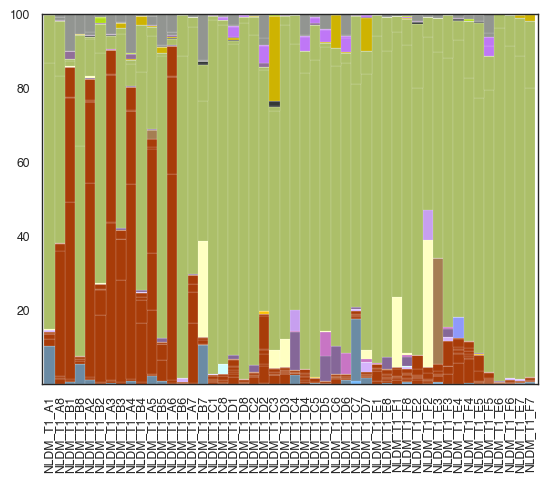

In [34]:
#An example of one of the subsetted plot for NLDM at T1
c_df = sample_info_df[sample_info_df['Timepoint']=='T1'].loc[sample_info_df['C source']=='NLDM']
c_samples = c_df['samples']
bin_abunds_df_rel_genera[c_samples].T.plot(kind='bar',stacked=True,width=1,color=genus_pal,linewidth=0.1,legend=False)
plt.show()

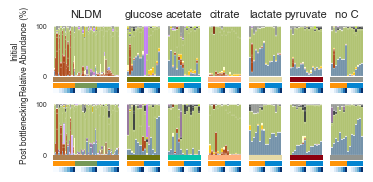

In [35]:
#Now use those functions to make the plots using loops to build the subplot grid
#Make sure fonts are set right before making the figure
mpl.rcParams['font.family'] = 'Helvetica'
mpl.rcParams['pdf.fonttype'] = 42

#Each part is in its own ax making this easier
fig,ax = plt.subplots(ncols=7,nrows=8,figsize=(4,2),width_ratios=(2,1,1,1,1,1,1),height_ratios=(1,.1,.1,.1,1,.1,.1,.1))

#Loop over each C source for T1
x = 0 #ax x index
for c in ['NLDM','glucose','acetate','citrate','lactate','pyruvate','no C']:
    plot_c_relabunds(c_source=c,T='T1',ax=ax[0,x])
    plot_sample_c(c_source=c,ax=ax[1,x])
    plot_sample_pH(c_source=c,T='T1',ax=ax[2,x])
    plot_sample_no3(c_source=c,T='T1',ax=ax[3,x])

    #Adjusting individual axes to squish the sample info bars together but not all subplots
    pos_c = ax[1,x].get_position()
    ax[1,x].set_position([pos_c.x0,pos_c.y0+0.0125,pos_c.width,pos_c.height])
    pos_pH = ax[2,x].get_position()
    ax[2,x].set_position([pos_pH.x0,pos_pH.y0+0.025,pos_pH.width,pos_pH.height])
    pos_no3 = ax[3,x].get_position()
    ax[3,x].set_position([pos_no3.x0,pos_no3.y0+0.0375,pos_no3.width,pos_no3.height])  

    ax[0,x].set_title(f'{c}',fontsize=8)

    x +=1

#Only NLDM is at T2 so plot it separately
plot_c_relabunds(c_source='NLDM',T='T2',ax=ax[4,0])
plot_sample_c(c_source='NLDM',ax=ax[5,0])
plot_sample_pH(c_source='NLDM',T='T2',ax=ax[6,0])
plot_sample_no3(c_source='NLDM',T='T2',ax=ax[7,0])

#adjust the spacing to squish the labels agains the bar plot but leave space between timepoint rows
pos_c = ax[5,0].get_position()
ax[5,0].set_position([pos_c.x0,pos_c.y0+0.0125,pos_c.width,pos_c.height])
pos_pH = ax[6,0].get_position()
ax[6,0].set_position([pos_pH.x0,pos_pH.y0+0.025,pos_pH.width,pos_pH.height])
pos_no3 = ax[7,0].get_position()
ax[7,0].set_position([pos_no3.x0,pos_no3.y0+0.0375,pos_no3.width,pos_no3.height])

#Repeat for T3 for the single carbons but start after NLDM ax
x = 1
for c in ['glucose','acetate','citrate','lactate','pyruvate','no C']:
    plot_c_relabunds(c_source=c,T='T3',ax=ax[4,x])
    plot_sample_c(c_source=c,ax=ax[5,x])
    plot_sample_pH(c_source=c,T='T3',ax=ax[6,x])
    plot_sample_no3(c_source=c,T='T3',ax=ax[7,x])

    pos_c = ax[5,x].get_position()
    ax[5,x].set_position([pos_c.x0,pos_c.y0+0.0125,pos_c.width,pos_c.height])
    pos_pH = ax[6,x].get_position()
    ax[6,x].set_position([pos_pH.x0,pos_pH.y0+0.025,pos_pH.width,pos_pH.height])
    pos_no3 = ax[7,x].get_position()
    ax[7,x].set_position([pos_no3.x0,pos_no3.y0+0.0375,pos_no3.width,pos_no3.height])

    x +=1

#Just cleaning up ticks
ax[0,0].tick_params(axis='y',pad=0,labelsize=5)
ax[0,0].set_yticks([0,100])
ax[0,0].set_ylabel('Initial\nRelative Abundance (%)',fontsize=6)

ax[4,0].tick_params(axis='y',pad=0,labelsize=5)
ax[4,0].set_yticks([0,100])
ax[4,0].set_ylabel('Post bottlenecking',fontsize=6)

#plt.savefig(f'../figs/abunds/rel_abund_grid_20260930.pdf',dpi=300,bbox_inches='tight')

plt.show()

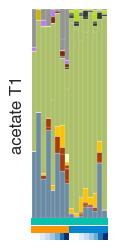

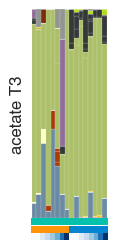

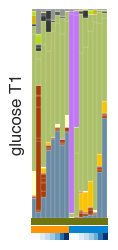

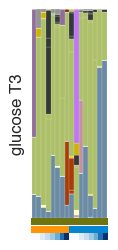

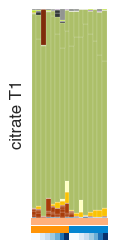

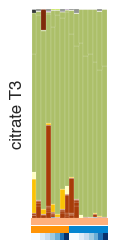

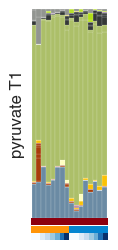

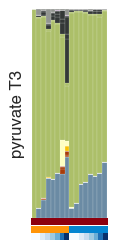

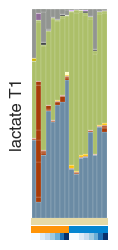

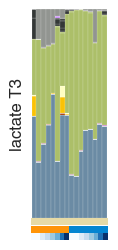

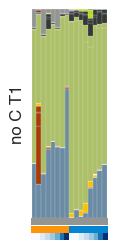

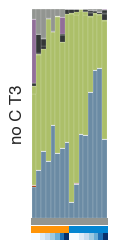

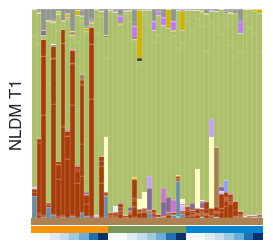

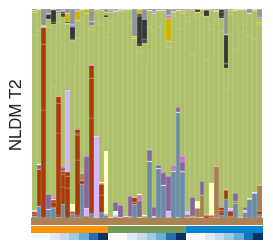

In [36]:
for c in c_palette.keys():
    plot_late_C_subset(c_source=c,T='T1',save=False,label=True)
    if c != 'NLDM':
        plot_late_C_subset(c_source=c,T='T3',save=False,label=True)
    elif c == 'NLDM':
        plot_late_C_subset(c_source=c,T='T2',save=False,label=True)

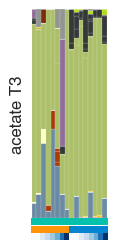

acetate
bins
Neor 1     73.018089
Allo 2     10.769308
Paen 35     3.499517
Noca 30     2.845184
Noca 9      2.011953
38          1.998252
Neor 4      1.785024
dtype: float64


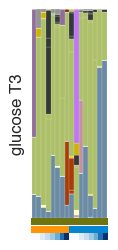

glucose
bins
Neor 1     52.762250
Allo 2     21.286403
Neor 4      4.718003
Paen 35     4.357273
Robe 5      4.024548
Noca 39     2.370822
Lacu 10     2.224257
Arth 18     1.907844
Noca 30     1.638640
dtype: float64


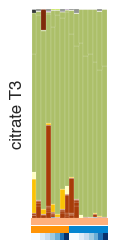

citrate
bins
Neor 1     76.357365
Neor 4     12.901355
Arth 15     3.664149
Jani 16     2.324608
dtype: float64


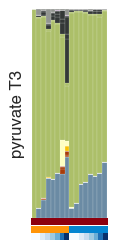

pyruvate
bins
Neor 1     76.192293
Allo 2     16.007502
Noca 39     2.521595
Noca 30     1.178977
38          1.011850
dtype: float64


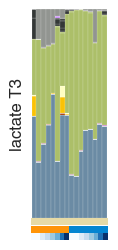

lactate
bins
Neor 1     51.134062
Allo 2     39.000910
38          5.766005
Jani 16     1.157603
Noca 29     1.103004
dtype: float64


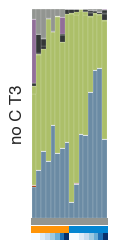

no C
bins
Neor 1     54.317576
Allo 2     36.580238
38          3.477585
Paen 35     2.443016
dtype: float64


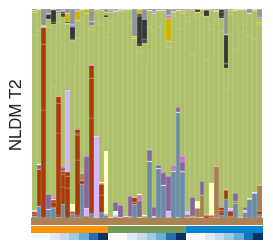

NLDM
bins
Neor 1     68.555673
Neor 4      7.241705
Allo 2      5.309970
Arth 6      4.179073
Lysi 3      2.668069
Arth 19     2.006470
Baci 14     1.928793
Micr 37     1.126316
Cell 22     1.121072
dtype: float64


In [37]:
#Look at the top abundant taxa for each C source
for c in c_palette.keys():
    if c == 'NLDM':
        plot_late_C_subset(c_source=c,T='T2')
        find_top_bins_by_c(c_source=c,cutoff=1)
    else:
        plot_late_C_subset(c_source=c,T='T3')
        find_top_bins_by_c(c_source=c,cutoff=1)

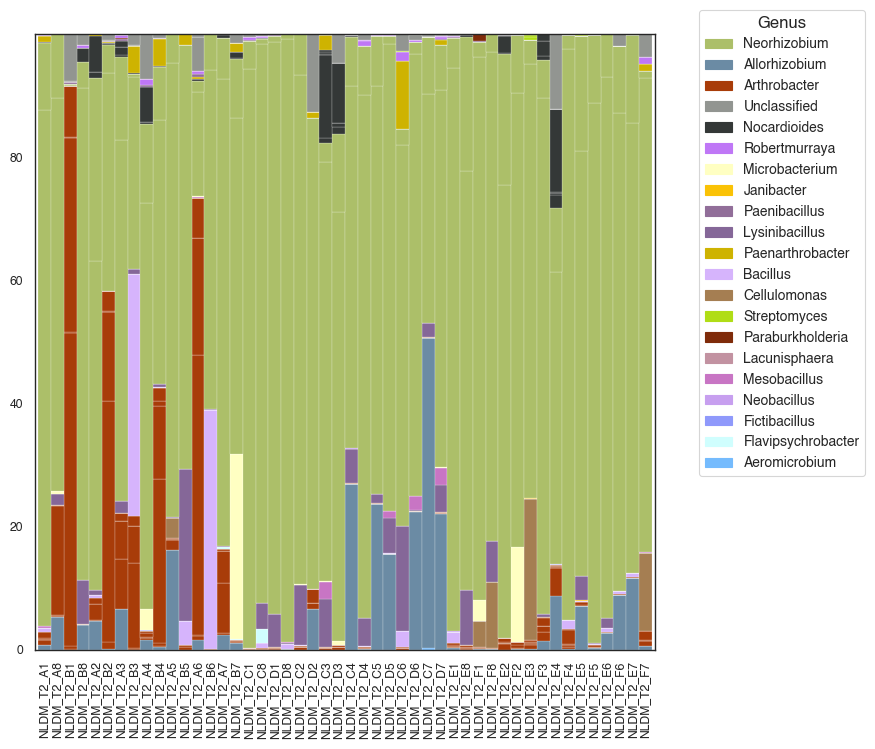

In [38]:
#Make a slightly larger version. Easy enough to change the timepoint and C source if desired
bin_abunds_df_rel_genera[sample_info_df[sample_info_df['Timepoint']=='T2'].loc[sample_info_df['C source']=='NLDM']['samples']].T.plot(kind='bar',stacked=True,width=1,color=genus_pal,linewidth=0.15,figsize=(8,8))
plt.legend(handles=genus_legend_handles,loc=1,bbox_to_anchor=(1.35,1.05),title='Genus',fontsize=10,title_fontsize=12)
plt.show()

In [39]:
#Function to check whether a bin is statistically more abundant in NLDM or SGW 
def check_bin_media_abunds_and_p_val(bin_num):

    #Check for differences in abundance of Bin (E.g. Bin_1) between NLDM and SGW
    NLDM_abunds = bin_abunds_df_rel[bin_abunds_df_rel.index == bin_num][[col for col in bin_abunds_df_rel.columns if 'NLDM' in col]].iloc[0]
    SGW_abunds = bin_abunds_df_rel[bin_abunds_df_rel.index == bin_num][[col for col in bin_abunds_df_rel.columns if 'SGW' in col]].iloc[0]

    #This is running the actual t-test, here with default parameters
    stat,p = ttest_ind(NLDM_abunds,SGW_abunds)

    #Print out which bin is more abundant. There are better ways to do this, but this is how I did it.
    if NLDM_abunds.mean() > SGW_abunds.mean():
        print(f'{bin_label_rename_dict[bin_num]} is more abundant in NLDM ({NLDM_abunds.mean():.2f}%) than in SGW ({SGW_abunds.mean():.2f}%).')
    elif NLDM_abunds.mean() < SGW_abunds.mean():
        print(f'{bin_label_rename_dict[bin_num]} is more abundant in SGW ({SGW_abunds.mean():.2f}%) than in NLDM ({NLDM_abunds.mean():.2f}%).')

    #Only return the p-value if it's significant, otherwise say it isn't so we don't have to interpret insignificant numbers
    if p < 0.05:
        print(f't-test p-value = {p:.2e}')
    elif p >= 0.05:
        print(f'No significant difference for {bin_label_rename_dict[bin_num]} between NLDM and SGW.')
    print('')

check_bin_media_abunds_and_p_val('Bin_1')

Neor 1 is more abundant in NLDM (67.17%) than in SGW (63.93%).
No significant difference for Neor 1 between NLDM and SGW.



In [40]:
#Check statistical difference between abundance in each medium for each bin
for bin_n in bin_order:
    check_bin_media_abunds_and_p_val(bin_n)

Neor 1 is more abundant in NLDM (67.17%) than in SGW (63.93%).
No significant difference for Neor 1 between NLDM and SGW.

Allo 2 is more abundant in SGW (19.47%) than in NLDM (3.23%).
t-test p-value = 5.01e-15

Lysi 3 is more abundant in NLDM (1.74%) than in SGW (0.00%).
t-test p-value = 6.80e-10

Neor 4 is more abundant in NLDM (7.17%) than in SGW (3.88%).
t-test p-value = 1.15e-04

Robe 5 is more abundant in SGW (1.18%) than in NLDM (0.33%).
No significant difference for Robe 5 between NLDM and SGW.

Arth 6 is more abundant in NLDM (6.02%) than in SGW (0.86%).
t-test p-value = 2.12e-06

Paen 7 is more abundant in NLDM (0.86%) than in SGW (0.15%).
t-test p-value = 1.77e-03

Meso 8 is more abundant in NLDM (0.26%) than in SGW (0.00%).
t-test p-value = 4.66e-04

Noca 9 is more abundant in SGW (0.51%) than in NLDM (0.29%).
No significant difference for Noca 9 between NLDM and SGW.

Lacu 10 is more abundant in SGW (0.22%) than in NLDM (0.00%).
No significant difference for Lacu 10 betwee

In [41]:
#Add a simple initial and transferred column to compare
sample_info_df['Transfer'] = sample_info_df['Timepoint'].map({'T1':'Initial','T2':'Transferred','T3':'Transferred'})
sample_info_df

,samples,Timepoint,Media,pH,C source,[NO3],C_ID,Transfer
0,NLDM_T1_A1,T1,NLDM,4.5,NLDM,0,6,Initial
7,NLDM_T1_A8,T1,NLDM,4.5,NLDM,0,6,Initial
8,NLDM_T1_B1,T1,NLDM,4.5,NLDM,0,6,Initial
15,NLDM_T1_B8,T1,NLDM,4.5,NLDM,0,6,Initial
1,NLDM_T1_A2,T1,NLDM,4.5,NLDM,5,6,Initial
...,...,...,...,...,...,...,...,...
258,SGW_T3_F7,T3,SGW,7.0,no C,10,0,Transferred
246,SGW_T3_E7,T3,SGW,7.0,no C,15,0,Transferred
234,SGW_T3_D7,T3,SGW,7.0,no C,20,0,Transferred
222,SGW_T3_C7,T3,SGW,7.0,no C,30,0,Transferred


In [42]:
#Create a function to use a pairwise t-test to evaluate the enrichment of certain genera for a given condition

#This is a more flexible t-test function
def calc_tax_abund_sig_pairwise_by_cond(cond=None):
    if cond == None:
        raise ValueError('Must specify cond=[pH, C source, pH,or Media]')

    df = bin_abunds_df_rel.copy(deep=True) #get a copy of the relative abundance data to work with
    
    #Genera are grouped across multiple bins for this comparison
    df.index = df.index.map(bin_genus_dict) #make the genus the index
    df = df.groupby(df.index).apply(np.sum,axis=0) #get the total relative abundance for each genus

    conds = sample_info_df[cond].unique() #list of conditions to separate data by, e.g. C sources: NLDM, acetate, glucose, etc.

    cond_sample_dict = {} #Store which samples correspond with which conditions here
    for x in conds: #iterate over each condition to get the relevant samples
        x_samples = sample_info_df[sample_info_df[cond]==x].samples #Use the metadata df for this slicing and get a Series with list of samples
        cond_sample_dict[x] = x_samples #Add the samples to the dict matched with the condition x
    
    #lists to populate evenly to build the dataframe
    genus_list = []
    comparison_list = []
    c1_mean_list = []
    c2_mean_list = []
    pval_list = []
    stat_list = []

    #loop over each subcondition to get the data pairwise
    for c1 in conds:
        for c2 in conds:
            if c1 != c2: #no need to self-compare
                if set(list((c1,c2))) not in comparison_list: #don't repeat conditions
                    for g in df.index: #loop over each genus for this pair of conditions
                        c1_b_abunds = df[cond_sample_dict[c1]].loc[g] #all of the abundances for the t-test
                        c1_b_mean = c1_b_abunds.mean() #mean abundance, for interpretation
                        c2_b_abunds = df[cond_sample_dict[c2]].loc[g] #all of the abundances for the t-test
                        c2_b_mean = c2_b_abunds.mean() #mean abundance, for interpretation
                        stat,p = ttest_ind(c1_b_abunds,c2_b_abunds) #run the t-test and get the stat and p-values
                        #if p <= 0.05: #only keep the significant results
                        genus_list.append(g) #now add all this data to those lists above
                        comparison_list.append(set(list((c1,c2))))
                        c1_mean_list.append(c1_b_mean)
                        c2_mean_list.append(c2_b_mean)
                        pval_list.append(p)
                        stat_list.append(stat)
                    
    #Perform the multiple testing correction using the Benjamini-Hochberg FDR control procedure
    rej,p_adj_list,aS,aB = multipletests(pval_list)

    #Build the dataframe using a dictionaries of lists. I find the this method easy and intuitive
    df_pairwise_ttests = pd.DataFrame({
        'Genus':genus_list,
        'Conditions':comparison_list,
        'Condition_1_mean':c1_mean_list,
        'Condition_2_mean':c2_mean_list,
        'p-value':pval_list,
        'T statistic':stat_list,
        'p_adjusted':p_adj_list
    })

    #filter out non-significant results
    df_pairwise_ttests = df_pairwise_ttests[df_pairwise_ttests['p-value']<=0.05]
    
    return df_pairwise_ttests #function returns the df
    
calc_tax_abund_sig_pairwise_by_cond(cond='C source')

,Genus,Conditions,Condition_1_mean,Condition_2_mean,p-value,T statistic,p_adjusted
1,Allorhizobium,"{glucose, NLDM}",3.225367,19.494885,9.837893e-10,-6.609076,4.240131e-07
7,Janibacter,"{glucose, NLDM}",0.016442,1.538312,8.324971e-06,-4.648014,3.473805e-03
9,Lysinibacillus,"{glucose, NLDM}",1.739546,0.000000,1.054106e-02,2.596369,9.823578e-01
13,Neorhizobium,"{glucose, NLDM}",74.335716,57.486112,9.172493e-04,3.395321,3.072375e-01
14,Nocardioides,"{glucose, NLDM}",0.797019,3.558779,8.348458e-03,-2.679909,9.610086e-01
...,...,...,...,...,...,...,...
400,Allorhizobium,"{lactate, no C}",38.377209,29.257446,2.692500e-02,2.266430,9.999460e-01
412,Neorhizobium,"{lactate, no C}",50.771473,61.070846,1.874427e-02,-2.414010,9.990360e-01
413,Nocardioides,"{lactate, no C}",1.282406,3.158774,8.863619e-03,-2.702636,9.672484e-01
421,Allorhizobium,"{no C, pyruvate}",15.668660,29.257446,3.003973e-04,-3.830872,1.148336e-01


In [43]:
df_c_pairwise_t_bin_abunds = calc_tax_abund_sig_pairwise_by_cond(cond='C source')
df_c_pairwise_t_bin_abunds

,Genus,Conditions,Condition_1_mean,Condition_2_mean,p-value,T statistic,p_adjusted
1,Allorhizobium,"{glucose, NLDM}",3.225367,19.494885,9.837893e-10,-6.609076,4.240131e-07
7,Janibacter,"{glucose, NLDM}",0.016442,1.538312,8.324971e-06,-4.648014,3.473805e-03
9,Lysinibacillus,"{glucose, NLDM}",1.739546,0.000000,1.054106e-02,2.596369,9.823578e-01
13,Neorhizobium,"{glucose, NLDM}",74.335716,57.486112,9.172493e-04,3.395321,3.072375e-01
14,Nocardioides,"{glucose, NLDM}",0.797019,3.558779,8.348458e-03,-2.679909,9.610086e-01
...,...,...,...,...,...,...,...
400,Allorhizobium,"{lactate, no C}",38.377209,29.257446,2.692500e-02,2.266430,9.999460e-01
412,Neorhizobium,"{lactate, no C}",50.771473,61.070846,1.874427e-02,-2.414010,9.990360e-01
413,Nocardioides,"{lactate, no C}",1.282406,3.158774,8.863619e-03,-2.702636,9.672484e-01
421,Allorhizobium,"{no C, pyruvate}",15.668660,29.257446,3.003973e-04,-3.830872,1.148336e-01


In [44]:
#Which genera differ significantly by carbon sources
list(df_c_pairwise_t_bin_abunds['Genus'].unique())

['Allorhizobium',
 'Janibacter',
 'Lysinibacillus',
 'Neorhizobium',
 'Nocardioides',
 'Robertmurraya',
 'Streptomyces',
 'Arthrobacter',
 'Lacunisphaera',
 'Paraburkholderia',
 'Unclassified',
 'Paenibacillus',
 'Paenarthrobacter',
 'Microbacterium']

In [45]:
#Which differ by timepoint?
df_T_pairwise_t_bin_abunds = calc_tax_abund_sig_pairwise_by_cond(cond='Timepoint')
df_T_pairwise_t_bin_abunds

,Genus,Conditions,Condition_1_mean,Condition_2_mean,p-value,T statistic,p_adjusted
1,Allorhizobium,"{T2, T1}",12.600020,5.309970,3.992904e-03,2.914300,0.197521
3,Bacillus,"{T2, T1}",0.058962,1.947606,4.245527e-03,-2.894229,0.205265
7,Janibacter,"{T2, T1}",1.186498,0.005916,3.036626e-04,3.680043,0.018057
9,Lysinibacillus,"{T2, T1}",0.270341,2.668069,1.162380e-07,-5.508992,0.000007
19,Streptomyces,"{T2, T1}",0.366898,0.022991,1.136966e-02,2.556023,0.435457
22,Allorhizobium,"{T3, T1}",12.600020,20.612208,7.162978e-04,-3.428025,0.040708
23,Arthrobacter,"{T3, T1}",8.067789,1.936976,1.750993e-03,3.165361,0.095067
24,Bacillus,"{T3, T1}",0.058962,0.000000,4.259712e-02,2.038583,0.846159
30,Lysinibacillus,"{T3, T1}",0.270341,0.000000,3.698628e-02,2.097705,0.809529
35,Nocardioides,"{T3, T1}",1.252221,3.391773,6.942003e-04,-3.436947,0.040144


In [46]:
#This differs because it combines T2 and T3 into just the initial state and then after bottlenecking transfer(s)
calc_tax_abund_sig_pairwise_by_cond(cond='Transfer')

,Genus,Conditions,Condition_1_mean,Condition_2_mean,p-value,T statistic,p_adjusted
2,Arthrobacter,"{Initial, Transferred}",8.067789,3.890307,0.023809,2.272336,0.349418
7,Janibacter,"{Initial, Transferred}",1.186498,0.438412,0.002381,3.065466,0.046557
9,Lysinibacillus,"{Initial, Transferred}",0.270341,0.889356,0.023600,-2.275764,0.349418
14,Nocardioides,"{Initial, Transferred}",1.252221,2.758758,0.005882,-2.775124,0.106029
19,Streptomyces,"{Initial, Transferred}",0.366898,0.069057,0.000324,3.639727,0.006778


In [47]:
list(df_T_pairwise_t_bin_abunds['Genus'].unique())

['Allorhizobium',
 'Bacillus',
 'Janibacter',
 'Lysinibacillus',
 'Streptomyces',
 'Arthrobacter',
 'Nocardioides',
 'Paenibacillus',
 'Cellulomonas',
 'Mesobacillus',
 'Neobacillus',
 'Neorhizobium',
 'Paenarthrobacter']

In [48]:
df_pH_pairwise_t_bin_abunds = calc_tax_abund_sig_pairwise_by_cond(cond='pH')
df_pH_pairwise_t_bin_abunds

,Genus,Conditions,Condition_1_mean,Condition_2_mean,p-value,T statistic,p_adjusted
0,Aeromicrobium,"{4.5, 6.0}",0.000003,0.031493,1.101030e-02,-2.572733,3.990735e-01
1,Allorhizobium,"{4.5, 6.0}",17.438248,5.939175,5.777384e-04,3.513119,3.016467e-02
2,Arthrobacter,"{4.5, 6.0}",11.330748,2.076631,2.025613e-02,2.345270,5.851989e-01
6,Flavipsychrobacter,"{4.5, 6.0}",0.003252,0.158285,5.163046e-03,-2.836229,2.240325e-01
9,Lysinibacillus,"{4.5, 6.0}",0.320972,2.997994,1.919353e-06,-4.946084,1.113164e-04
10,Mesobacillus,"{4.5, 6.0}",0.007670,0.698327,3.445645e-06,-4.813232,1.929379e-04
12,Neobacillus,"{4.5, 6.0}",0.000000,0.184947,4.073254e-02,-2.063172,8.024629e-01
13,Neorhizobium,"{4.5, 6.0}",59.792832,81.643805,1.486075e-06,-5.003433,8.916056e-05
15,Paenarthrobacter,"{4.5, 6.0}",0.321419,1.798605,1.368825e-03,-3.259050,6.875015e-02
18,Robertmurraya,"{4.5, 6.0}",0.117453,0.871975,2.270208e-06,-4.908212,1.293937e-04


In [49]:
df_c_pairwise_t_bin_abunds.sort_values(by='Condition_1_mean',ascending=False)

,Genus,Conditions,Condition_1_mean,Condition_2_mean,p-value,T statistic,p_adjusted
328,Neorhizobium,"{citrate, lactate}",90.504387,50.771473,6.656801e-18,12.056969,2.915679e-15
370,Neorhizobium,"{citrate, no C}",90.504387,61.070846,1.662991e-11,8.217187,7.200751e-09
349,Neorhizobium,"{citrate, pyruvate}",90.504387,75.895618,6.121905e-06,4.944676,2.561799e-03
433,Neorhizobium,"{no C, pyruvate}",75.895618,61.070846,4.629281e-04,3.697894,1.702271e-01
13,Neorhizobium,"{glucose, NLDM}",74.335716,57.486112,9.172493e-04,3.395321,3.072375e-01
...,...,...,...,...,...,...,...
92,Lacunisphaera,"{NLDM, pyruvate}",0.000005,0.051947,4.098083e-02,-2.064928,9.999995e-01
29,Lacunisphaera,"{acetate, NLDM}",0.000005,0.038239,2.949498e-04,-3.723569,1.131348e-01
50,Lacunisphaera,"{citrate, NLDM}",0.000005,0.000798,3.782912e-03,-2.950582,7.745154e-01
113,Lacunisphaera,"{no C, NLDM}",0.000005,0.024946,1.152548e-02,-2.563872,9.870564e-01


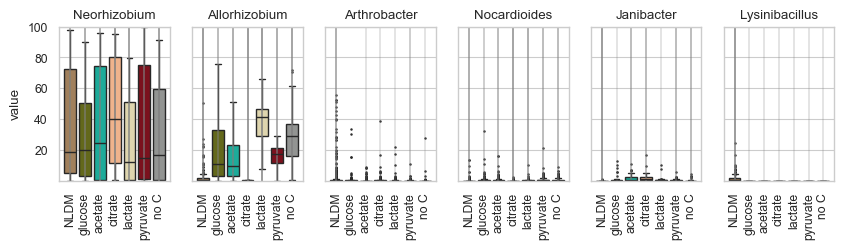

In [50]:
#Trying boxplots again but this time to see how each genus varies significantly by carbon source
sns.set_style('whitegrid')
fig,ax = plt.subplots(nrows=1,ncols=6,figsize=(10,2),sharey=True)

x = 0

for g in df_c_pairwise_t_bin_abunds[df_c_pairwise_t_bin_abunds['Genus']!='Unclassified'].sort_values(by='Condition_1_mean',ascending=False)['Genus'].unique():
    #sns.stripplot(bin_abunds_df_rel_genera_melt[bin_abunds_df_rel_genera_melt['Genus']==g],x='C source',hue='C source',
    #                y='value',palette=c_palette,ax=ax[x])
    df_g = bin_abunds_df_rel_genera_melt[bin_abunds_df_rel_genera_melt['Genus']==g]
    df_g_stats = df_c_pairwise_t_bin_abunds[df_c_pairwise_t_bin_abunds['Genus']==g]
    #print(g,df_g_stats['Conditions'].to_list())

    if x!=6:
        sns.boxplot(df_g,x='C source',hue='C source',
                        y='value',palette=c_palette,fliersize=0.75,ax=ax[x])
        #sns.stripplot(df_g,x='C source',hue='C source',
        #                y='value',palette=c_palette,alpha=0.5,ax=ax[x])

        y_i = 150
        for i in range(len(df_g_stats)):
            ax[x].hlines(y=y_i,xmin=list(df_g_stats['Conditions'].iloc[i])[0],xmax=list(df_g_stats['Conditions'].iloc[i])[1],color='black',linewidth=1.5)
            ax[x].axvline(list(df_g_stats['Conditions'].iloc[i])[0],color='gray',alpha=0.25)
            ax[x].axvline(list(df_g_stats['Conditions'].iloc[i])[1],color='gray',alpha=0.25)
            y_i +=10

        

        #ax[x].set_yscale('log')
        ax[x].set_ylim(1e-2,100)
        #ax[x].axhline(1,color='black',linestyle='--')
        ax[x].set_title(f'{g}')
        ax[x].set_xlabel('')
        ax[x].tick_params(axis='x', rotation=90) 

        x+=1

plt.show()

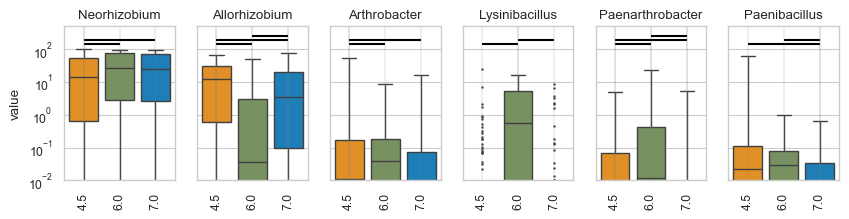

In [51]:
#or pH
sns.set_style('whitegrid')
fig,ax = plt.subplots(nrows=1,ncols=6,figsize=(10,2),sharey=True)

x = 0

for g in df_pH_pairwise_t_bin_abunds[df_pH_pairwise_t_bin_abunds['Genus']!='Unclassified'].sort_values(by='Condition_1_mean',ascending=False)['Genus'].unique():
    #sns.stripplot(bin_abunds_df_rel_genera_melt[bin_abunds_df_rel_genera_melt['Genus']==g],x='C source',hue='C source',
    #                y='value',palette=c_palette,ax=ax[x])
    df_g = bin_abunds_df_rel_genera_melt[bin_abunds_df_rel_genera_melt['Genus']==g]
    df_g_stats = df_pH_pairwise_t_bin_abunds[df_pH_pairwise_t_bin_abunds['Genus']==g]
    #print(g,df_g_stats['Conditions'].to_list())

    if x!=6:
        sns.boxplot(df_g,x='pH',hue='pH',
                        y='value',palette=pH_palette,fliersize=0.75,ax=ax[x],legend=False)

        y_i = 150
        for i in range(len(df_g_stats)):
            ax[x].hlines(y=y_i,xmin=str(list(df_g_stats['Conditions'].iloc[i])[0]),xmax=str(list(df_g_stats['Conditions'].iloc[i])[1]),color='black',linewidth=1.5)
            ax[x].axvline(str(list(df_g_stats['Conditions'].iloc[i])[0]),color='gray',alpha=0.15)
            ax[x].axvline(str(list(df_g_stats['Conditions'].iloc[i])[1]),color='gray',alpha=0.15)
            y_i +=50

        

        ax[x].set_yscale('log')
        ax[x].set_ylim(1e-2,500)
        #ax[x].axhline(1,color='black',linestyle='--')
        ax[x].set_title(f'{g}')
        ax[x].set_xlabel('')
        ax[x].tick_params(axis='x', rotation=90) 

        x+=1

plt.show()

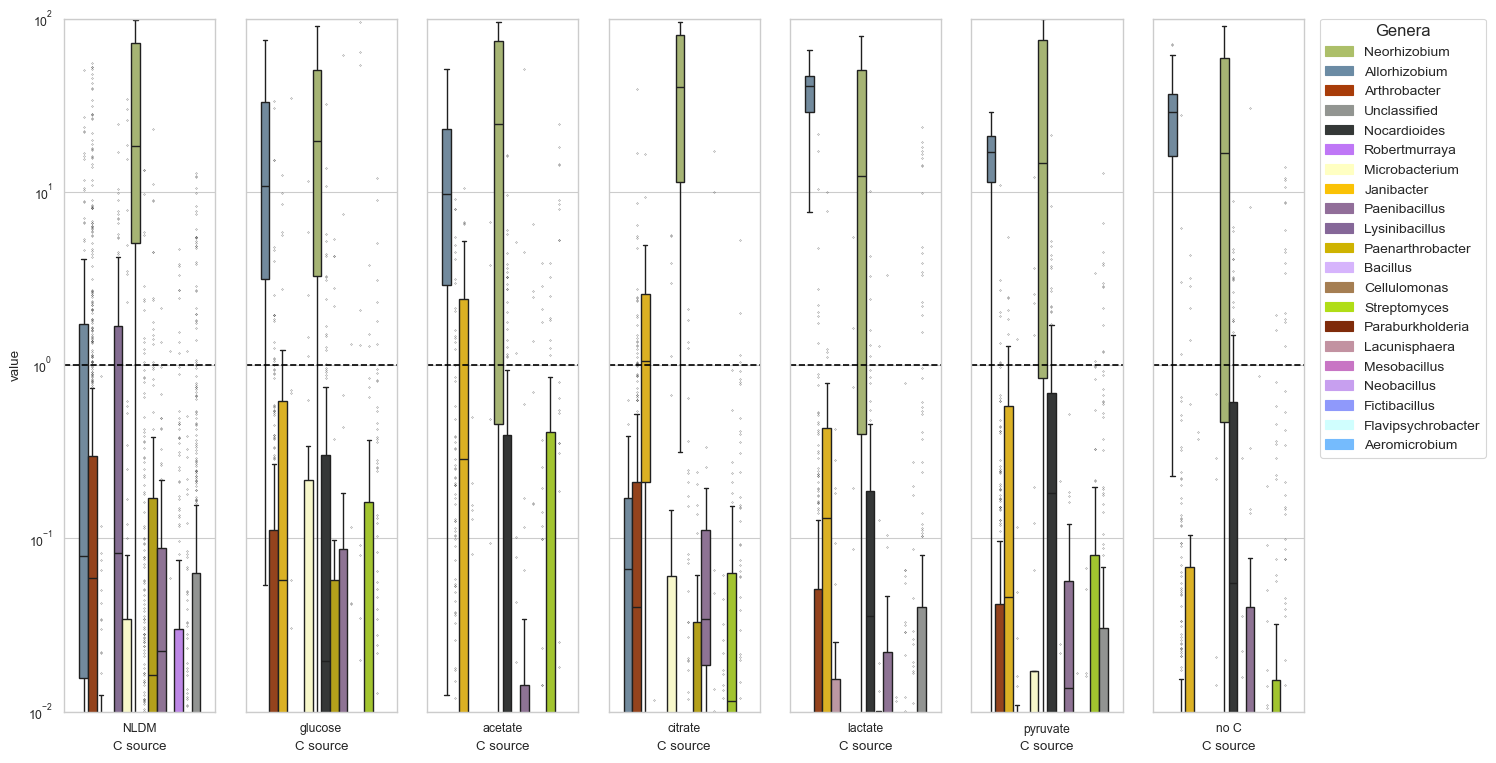

In [52]:
#We already did this above but I did it again a bit more cleanly here
def plot_sig_diffs_rel_abund_boxes(condition=None,log=False):

    df_sig = calc_tax_abund_sig_pairwise_by_cond(cond=condition)

    df = bin_abunds_df_rel_genera_melt[bin_abunds_df_rel_genera_melt['Genus'].isin(df_sig['Genus'].unique())]

    vars = df[condition].unique()
    n_vars = len(vars)

    fig,ax=plt.subplots(figsize=(16,9),ncols=n_vars,sharey=True)

    for i in range(n_vars):
        axis = ax[i]
        sns.boxplot(df[df[condition]==vars[i]],
                    x=condition,y='value',hue='Genus',palette=genus_pal,
                    fliersize=0.2,ax=axis)
        axis.set_ylim(1e-2,100)
        axis.axhline(1,color='black',linestyle='--')
        if i < n_vars-1:
            axis.get_legend().remove()

    

    handles,labels = ax[n_vars-1].get_legend_handles_labels() #Get the genera names to create a custom legend

    genus_legend_handles = [] #This list becomes the custom legend
    for genus in g_order_avg_abund: #get each genus
        handle = mpatches.Patch(color=genus_pal[genus], label=f'{genus}') #create a label and colored bar for it using the palette set above
        genus_legend_handles.append(handle) #put it in the list

    ax[n_vars-1].legend(handles=genus_legend_handles,loc=1,bbox_to_anchor=(2.25,1.01),title='Genera',fontsize=10,title_fontsize=12) #Create the legend
    if log==True:
        plt.yscale('log')
    plt.show()

plot_sig_diffs_rel_abund_boxes(condition='C source',log=True)

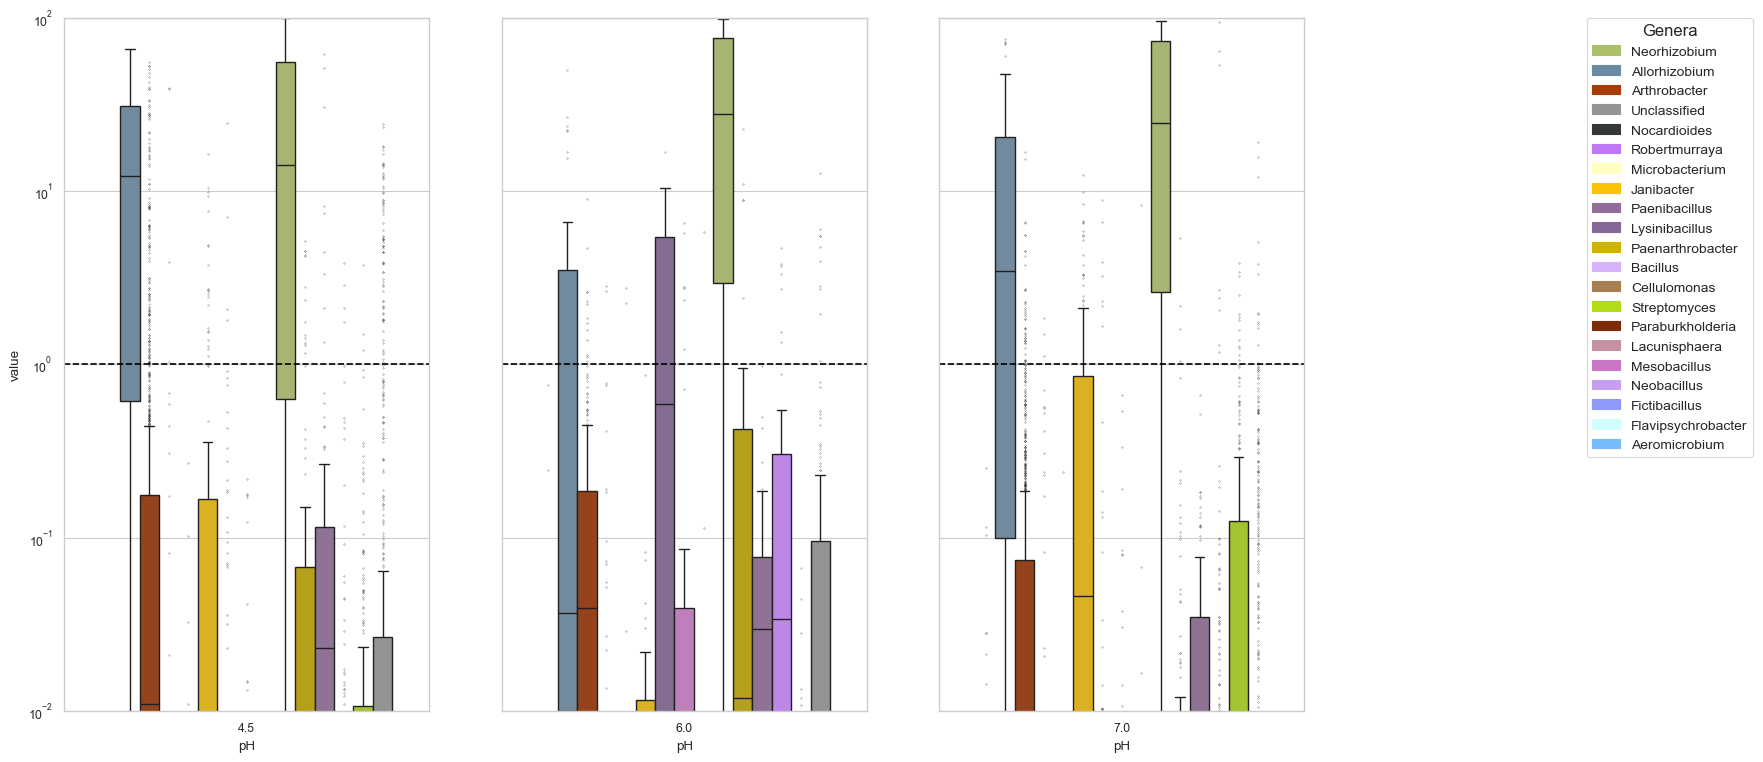

In [53]:
plot_sig_diffs_rel_abund_boxes(condition='pH',log=True)

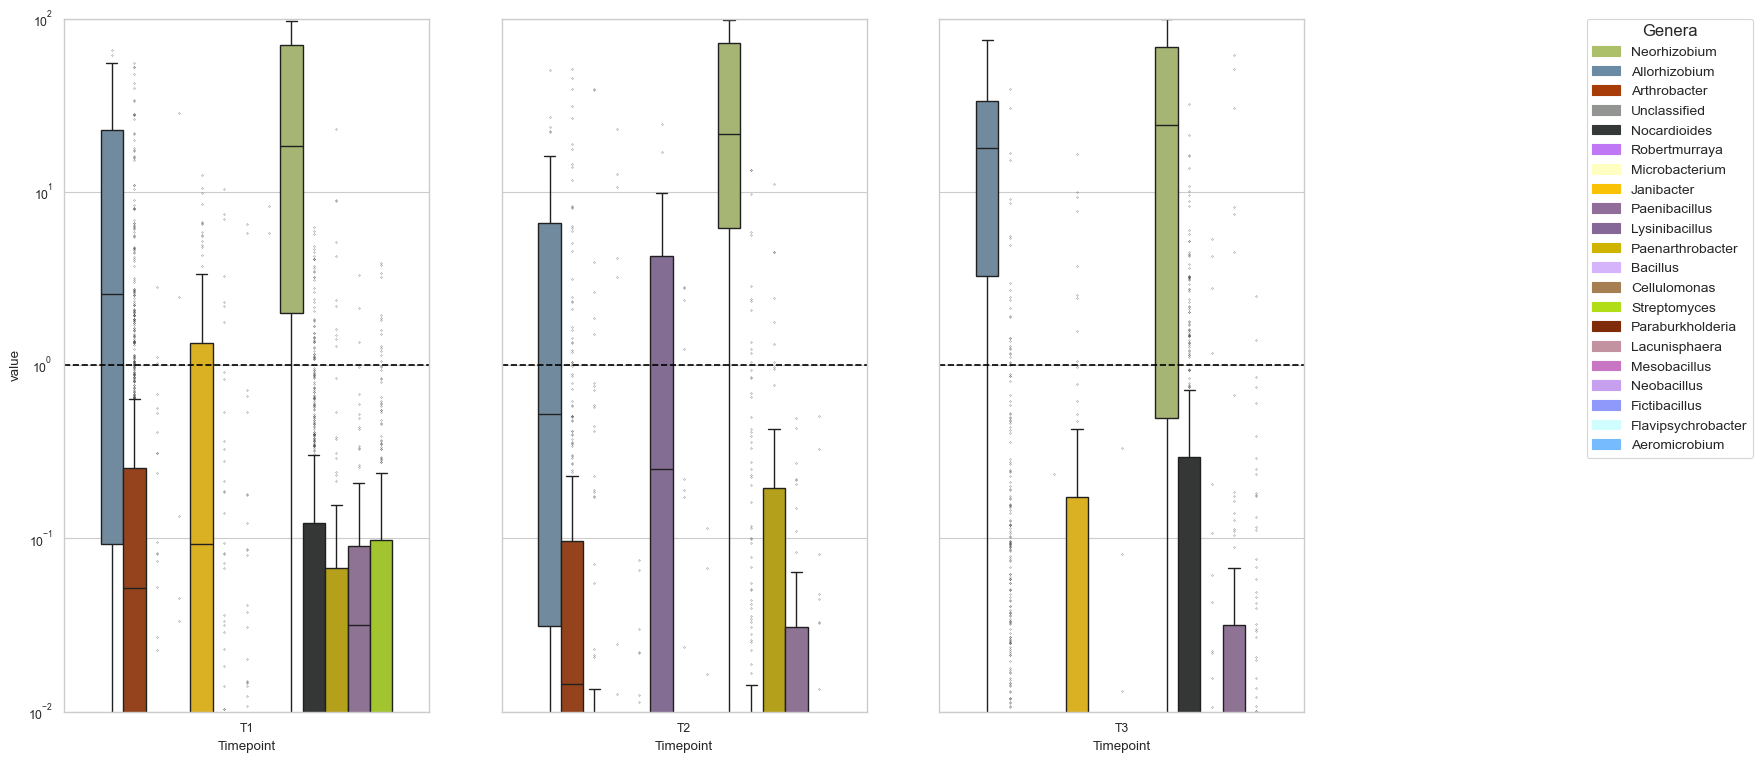

In [54]:
plot_sig_diffs_rel_abund_boxes(condition='Timepoint',log=True)

In [55]:
#Check the mean relative abundance of each bin across all samples
bin_abunds_df_rel.mean(axis=1).sort_values(ascending=False).rename(bin_label_rename_dict)

bins
Neor 1     65.007494
Allo 2     14.055741
Neor 4      4.976446
Arth 6      2.576979
38          1.681610
Arth 19     1.287143
Robe 5      0.899634
Micr 37     0.823232
Jani 16     0.812455
Noca 39     0.757297
Paen 35     0.649106
Arth 15     0.609940
Lysi 3      0.579849
Noca 30     0.495111
Noca 9      0.436588
17          0.412543
Paen 7      0.387550
Arth 18     0.384450
Arth 11     0.359065
Baci 14     0.338187
Cell 22     0.295960
Arth 41     0.272079
Arth 12     0.234072
23          0.217053
Noca 40     0.195873
Para 13     0.156565
Arth 28     0.144769
Lacu 10     0.143561
Stre 31     0.127384
Noca 29     0.120620
Arth 25     0.110550
24          0.104899
Stre 32     0.090593
Meso 8      0.088246
Neob 34     0.049619
Robe 36     0.031533
33          0.023802
Fict 21     0.021133
Flav 20     0.019876
Baci 27     0.015895
Aero 26     0.005494
dtype: float64

In [56]:
#Check the mean relative abundance of each genus across all samples
bin_abunds_df_rel_genera.groupby(bin_abunds_df_rel_genera.index).apply(np.sum,axis=0).mean(axis=1).sort_values(ascending=False)

Genus
Neorhizobium          69.983941
Allorhizobium         14.055741
Arthrobacter           5.979048
Unclassified           2.439907
Nocardioides           2.005490
Robertmurraya          0.931167
Microbacterium         0.823232
Janibacter             0.812455
Paenibacillus          0.649106
Lysinibacillus         0.579849
Paenarthrobacter       0.387550
Bacillus               0.354082
Cellulomonas           0.295960
Streptomyces           0.217978
Paraburkholderia       0.156565
Lacunisphaera          0.143561
Mesobacillus           0.088246
Neobacillus            0.049619
Fictibacillus          0.021133
Flavipsychrobacter     0.019876
Aeromicrobium          0.005494
dtype: float64

In [57]:
#Find the c conditions where Neorhizobium is statistically more abundant
df_c_pairwise_t_bin_abunds[df_c_pairwise_t_bin_abunds['Genus']=='Neorhizobium'].sort_values(by='Condition_1_mean',ascending=False)

,Genus,Conditions,Condition_1_mean,Condition_2_mean,p-value,T statistic,p_adjusted
328,Neorhizobium,"{citrate, lactate}",90.504387,50.771473,6.656801e-18,12.056969,2.915679e-15
349,Neorhizobium,"{citrate, pyruvate}",90.504387,75.895618,6.121905e-06,4.944676,2.561799e-03
370,Neorhizobium,"{citrate, no C}",90.504387,61.070846,1.662991e-11,8.217187,7.200751e-09
433,Neorhizobium,"{no C, pyruvate}",75.895618,61.070846,4.629281e-04,3.697894,1.702271e-01
13,Neorhizobium,"{glucose, NLDM}",74.335716,57.486112,9.172493e-04,3.395321,3.072375e-01
55,Neorhizobium,"{citrate, NLDM}",74.335716,90.504387,3.905453e-04,-3.644284,1.459889e-01
76,Neorhizobium,"{lactate, NLDM}",74.335716,50.771473,1.278787e-06,5.088276,5.420590e-04
118,Neorhizobium,"{no C, NLDM}",74.335716,61.070846,5.545890e-03,2.822098,8.856986e-01
244,Neorhizobium,"{citrate, acetate}",71.119882,90.504387,1.322091e-05,-4.733610,5.497986e-03
265,Neorhizobium,"{acetate, lactate}",71.119882,50.771473,5.654605e-05,4.324329,2.313882e-02


In [58]:
#Find the c conditions where Allorhizobium is statistically more abundant
df_c_pairwise_t_bin_abunds[df_c_pairwise_t_bin_abunds['Genus']=='Allorhizobium'].sort_values(by='Condition_1_mean',ascending=False)

,Genus,Conditions,Condition_1_mean,Condition_2_mean,p-value,T statistic,p_adjusted
400,Allorhizobium,"{lactate, no C}",38.377209,29.257446,2.692500e-02,2.266430,9.999460e-01
379,Allorhizobium,"{lactate, pyruvate}",38.377209,15.668660,3.679391e-12,8.596117,1.596856e-09
169,Allorhizobium,"{glucose, lactate}",19.494885,38.377209,4.220001e-05,-4.408046,1.740237e-02
148,Allorhizobium,"{citrate, glucose}",19.494885,0.129051,1.302564e-06,5.359525,5.508331e-04
421,Allorhizobium,"{no C, pyruvate}",15.668660,29.257446,3.003973e-04,-3.830872,1.148336e-01
295,Allorhizobium,"{acetate, no C}",13.898320,29.257446,5.109218e-04,-3.667210,1.852973e-01
253,Allorhizobium,"{acetate, lactate}",13.898320,38.377209,1.532701e-09,-7.084920,6.590610e-07
232,Allorhizobium,"{citrate, acetate}",13.898320,0.129051,1.393338e-06,5.341690,5.878162e-04
22,Allorhizobium,"{acetate, NLDM}",3.225367,13.898320,3.731277e-07,-5.365661,1.589398e-04
106,Allorhizobium,"{no C, NLDM}",3.225367,29.257446,9.237596e-21,-11.252506,4.055304e-18


In [59]:
#Find the c conditions where Arthrobacter is statistically more abundant
df_c_pairwise_t_bin_abunds[df_c_pairwise_t_bin_abunds['Genus']=='Arthrobacter'].sort_values(by='Condition_1_mean',ascending=False)

,Genus,Conditions,Condition_1_mean,Condition_2_mean,p-value,T statistic,p_adjusted
23,Arthrobacter,"{acetate, NLDM}",12.378565,2.231162,0.016831,2.422624,0.998159
65,Arthrobacter,"{lactate, NLDM}",12.378565,2.518024,0.023456,2.293835,0.999819
86,Arthrobacter,"{NLDM, pyruvate}",12.378565,1.183024,0.008514,2.672943,0.962819
107,Arthrobacter,"{no C, NLDM}",12.378565,1.390437,0.010465,2.598977,0.982026
338,Arthrobacter,"{citrate, pyruvate}",4.732225,1.183024,0.030299,2.217005,0.999982


In [60]:
df_c_pairwise_t_bin_abunds[df_c_pairwise_t_bin_abunds['Genus']=='Nocardioides'].sort_values(by='Condition_1_mean',ascending=False)

,Genus,Conditions,Condition_1_mean,Condition_2_mean,p-value,T statistic,p_adjusted
245,Nocardioides,"{citrate, acetate}",3.604492,0.285891,1.322744e-03,3.363726,0.408727
266,Nocardioides,"{acetate, lactate}",3.604492,1.282406,3.683812e-02,2.133618,0.999998
161,Nocardioides,"{citrate, glucose}",3.558779,0.285891,4.499912e-02,2.046047,1.000000
392,Nocardioides,"{lactate, pyruvate}",1.282406,3.768007,3.060353e-02,-2.212783,0.999984
413,Nocardioides,"{lactate, no C}",1.282406,3.158774,8.863619e-03,-2.702636,0.967248
14,Nocardioides,"{glucose, NLDM}",0.797019,3.558779,8.348458e-03,-2.679909,0.961009
35,Nocardioides,"{acetate, NLDM}",0.797019,3.604492,2.133018e-04,-3.813668,0.083356
98,Nocardioides,"{NLDM, pyruvate}",0.797019,3.768007,1.319609e-04,-3.944538,0.052670
119,Nocardioides,"{no C, NLDM}",0.797019,3.158774,4.429995e-05,-4.231621,0.018217
329,Nocardioides,"{citrate, lactate}",0.285891,1.282406,4.949846e-02,-2.003505,1.000000


Avg rel. abund captured by MAGs: 96.64%


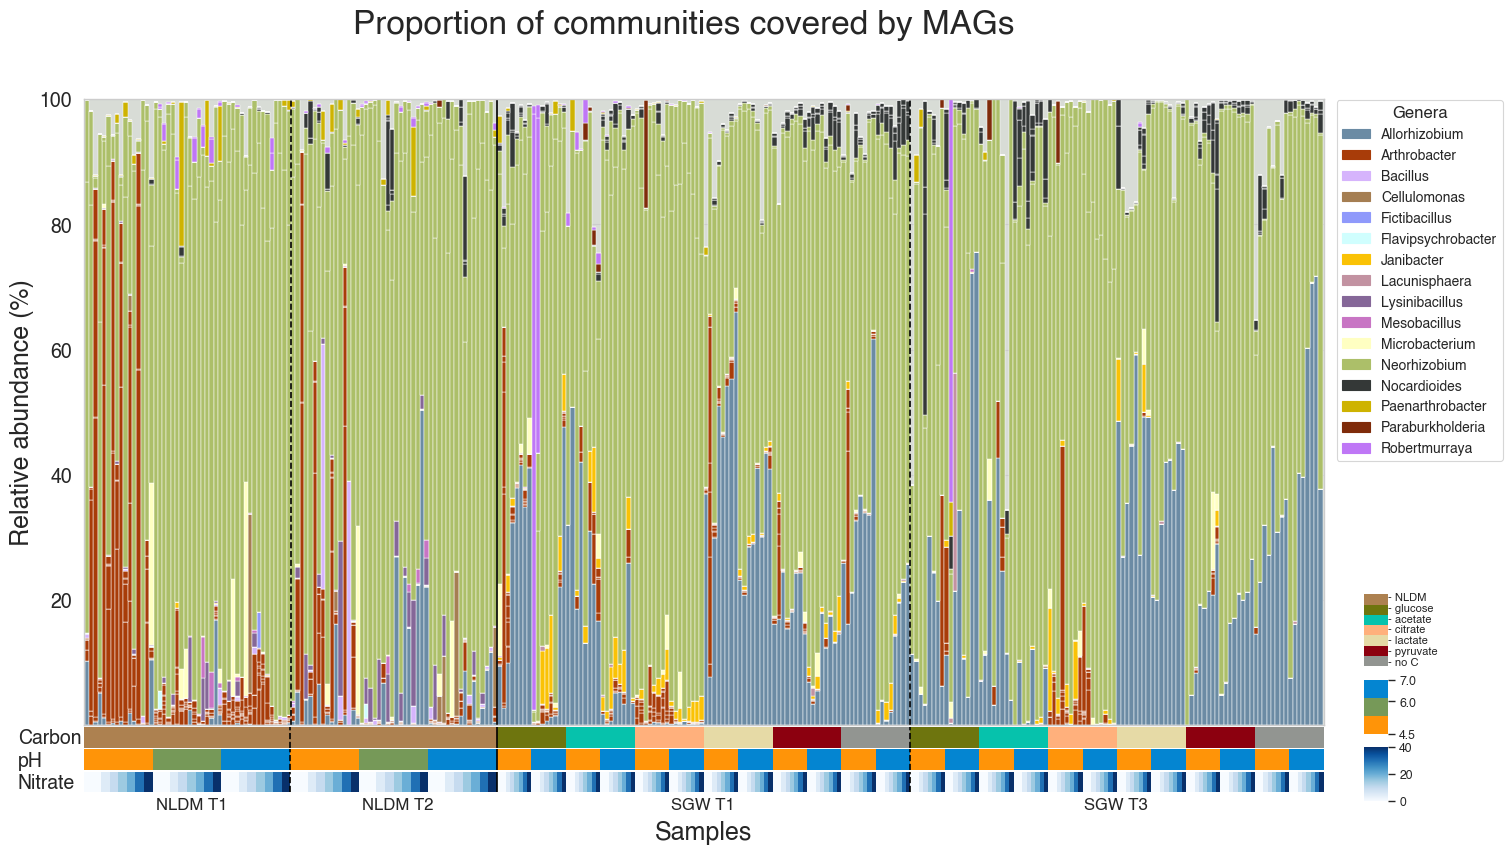

In [61]:
#Create a plot to see how much of each enrichment is covered by the MAGs (here bins with > 90% completeness)
#Modified slightly from above

#Proportion of the community covered by the MAGs on average
print(f'Avg rel. abund captured by MAGs: {bin_abunds_df_rel_genera[bin_abunds_df_rel_genera.index.isin([bin_genus_dict[i] for i in good_bin_list])].sum().mean():.2f}%')

mpl.rcParams['font.family'] = 'Helvetica' #reset the font because sns.set_style() changes it
fig,ax = plt.subplots(ncols=1,nrows=4,figsize=(16,9),height_ratios=[4.55,.15,.15,.15]) #create the subplot grid and scale the axes

#bin_abunds_df_rel_genera.T.plot(kind='bar',stacked=True,width=1,color=genus_pal,linewidth=0.1,ax=ax[0]) #This is the bar plot, df.plot() does a great job for stacked bar charts
bin_abunds_df_rel_genera[bin_abunds_df_rel_genera.index.isin([bin_genus_dict[i] for i in good_bin_list])].T.plot(kind='bar',stacked=True,width=1,color=genus_pal,linewidth=0.35,ax=ax[0]) #good bins only this time

handles,labels = ax[0].get_legend_handles_labels() #Get the genera names to create a custom legend

genus_legend_handles = [] #This list becomes the custom legend
for genus in sorted(set(labels)): #get each genus
    handle = mpatches.Patch(color=genus_pal[genus], label=f'{genus}') #create a label and colored bar for it using the palette set above
    genus_legend_handles.append(handle) #put it in the list

ax[0].legend(handles=genus_legend_handles,loc=1,bbox_to_anchor=(1.15,1.01),title='Genera',fontsize=10,title_fontsize=12) #Create the legend
#ax[0].set_title('Relative abundance of EnCom bins',fontsize=20,pad=15)
ax[0].set_title('')

#Create vertical lines to separate timepoints and media
ax[0].axvline(47.5,color='black',ls='--')
ax[0].axvline(95.5,color='black',ls='-')
ax[0].axvline(191.5,color='black',ls='--')
ax[0].set_xticks([])
ax[0].set_yticks([20,40,60,80,100],labels=[20,40,60,80,100],fontsize=14) #set yticks explicitly
ax[0].set_ylabel('Relative abundance (%)',fontsize=18)
ax[0].set_facecolor('xkcd:light grey')

#labels for media timepoints
ax[0].text(16,-13.5,'NLDM T1',fontsize=12)
ax[0].text(64,-13.5,'NLDM T2',fontsize=12)
ax[0].text(136,-13.5,'SGW T1',fontsize=12)
ax[0].text(232,-13.5,'SGW T3',fontsize=12)

#Create axes for the legends for the metadata for go under the legend for the rel abund plot
cbar_ax1 = fig.add_subplot([.925,.25,.015,.08])
cbar_ax2 = fig.add_subplot([.925,.175,.015,.06])
cbar_ax3 = fig.add_subplot([.925,.1,.015,.06])

#carbon source plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df['C_ID']).T,cmap=c_colors,ax=ax[1],yticklabels=False,cbar=True,cbar_ax=cbar_ax1)
#carbon source legend
cbar_ax1.set_yticks([])
cbar_ax1.text(1,0.1,'- no C',fontsize=8) #very manually setting tick labels
cbar_ax1.text(1,1,'- pyruvate',fontsize=8)
cbar_ax1.text(1,1.9,'- lactate',fontsize=8)
cbar_ax1.text(1,2.8,'- citrate',fontsize=8)
cbar_ax1.text(1,3.7,'- acetate',fontsize=8)
cbar_ax1.text(1,4.6,'- glucose',fontsize=8)
cbar_ax1.text(1,5.5,'- NLDM',fontsize=8)
ax[1].axvline(48,color='black',ls='--')
ax[1].axvline(96,color='black',ls='-')
ax[1].axvline(192,color='black',ls='--')
ax[1].set_xticks([])
ax[1].set_ylabel('Carbon',fontsize=14,labelpad=47.5,rotation=0,loc='bottom')
ax[1].set_facecolor('xkcd:light grey')

#pH plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df['pH']).T,cmap=['xkcd:tangerine','xkcd:moss','xkcd:cerulean'],ax=ax[2],yticklabels=False,cbar=True,cbar_ax=cbar_ax2)
#pH legend
cbar_ax2.set_yticks([4.5,6,7])
ax[2].axvline(48,color='black',ls='--')
ax[2].axvline(96,color='black',ls='-')
ax[2].axvline(192,color='black',ls='--')
ax[2].set_xticks([])
ax[2].set_ylabel('pH',fontsize=14,labelpad=47.5,rotation=0,loc='bottom')
ax[2].set_facecolor('xkcd:light grey')

#[NO3-] plot for x axis under rel abund plot
sns.heatmap(pd.DataFrame(sample_info_df['[NO3]']).T,cmap='Blues',ax=ax[3],yticklabels=False,cbar=True,cbar_ax=cbar_ax3)
#[NO3-] legend
cbar_ax3.set_yticks([0,20,40])
ax[3].axvline(48,color='black',ls='--')
ax[3].axvline(96,color='black',ls='-')
ax[3].axvline(192,color='black',ls='--')
ax[3].set_xticks([])
ax[3].set_ylabel('Nitrate',fontsize=14,labelpad=47.5,rotation=0,loc='bottom')
ax[3].set_facecolor('xkcd:light grey')

#Create an x axis label for everything
ax[3].set_xlabel('Samples',fontsize=18,labelpad=20)

#Put all the subplots close together
plt.subplots_adjust(hspace=0.01)

plt.suptitle('Proportion of communities covered by MAGs',fontsize=24)

#Save the image as a pdf to be added to the full image in Adobe Illustrator
#plt.savefig('../figs/Fig1D_EnCom_all_relabund.pdf',dpi=300,bbox_inches='tight')
plt.show()

In [62]:
#Make box plots to see how the relative abundance of each bin varies across 2 conditions at a time

bin_abunds_df_rel_info = bin_abunds_df_rel.reset_index().melt(id_vars='bins').rename({'variable':'samples'},axis=1).merge(sample_info_df,how='left',on='samples')

def plot_bin_rel_abund_by_conds(bin_id=None,x_cond='[NO3]',hue_cond='pH'):
    
    if hue_cond == 'pH':
        pal = pH_palette
    elif hue_cond == 'Media':
        pal = media_pal
    elif hue_cond == '[NO3]':
        pal == 'Blues'

    plt.figure(figsize=(8,8))
    sns.boxplot(bin_abunds_df_rel_info[bin_abunds_df_rel_info['bins'] == bin_id],x=x_cond,y='value',hue=hue_cond,legend=True,palette=pal)
    plt.title(f'Relative Abundance of {bin_label_rename_dict[bin_id]}',fontsize=18)
    plt.ylabel('Relative Abundance (%)',fontsize=16)
    plt.xlabel(x_cond,fontsize=16)

    plt.show()

#plot_bin_rel_abund_by_conds('Bin_1')

/var/folders/71/xm3vqjnn3xv2vtqkfhmrtzyh0000gp/T/ipykernel_91082/1256466222.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  bin_abunds_df_rel_info = bin_abunds_df_rel.reset_index().melt(id_vars='bins').rename({'variable':'samples'},axis=1).merge(sample_info_df,how='left',on='samples')


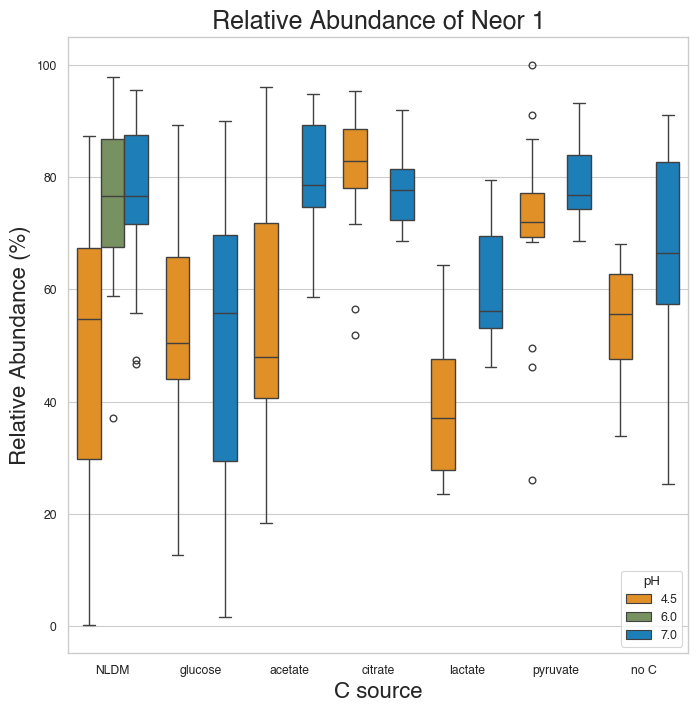

In [63]:
plot_bin_rel_abund_by_conds(bin_id='Bin_1',x_cond='C source',hue_cond='pH')

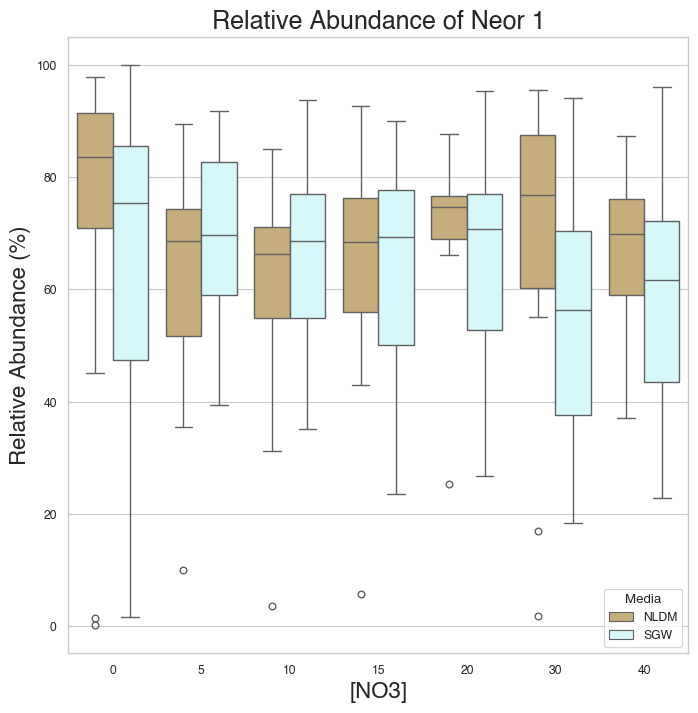

In [64]:
plot_bin_rel_abund_by_conds(bin_id='Bin_1',x_cond='[NO3]',hue_cond='Media')

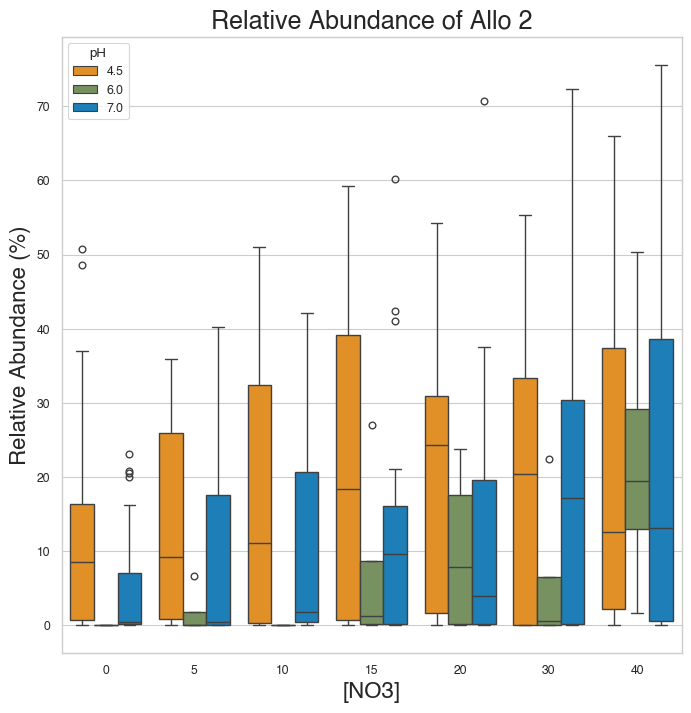

In [65]:
plot_bin_rel_abund_by_conds('Bin_2')

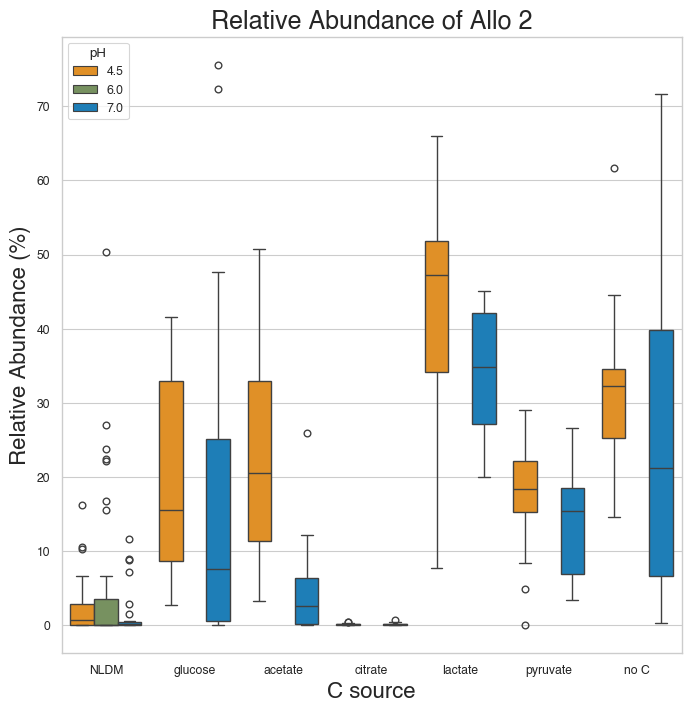

In [66]:
plot_bin_rel_abund_by_conds(bin_id='Bin_2',x_cond='C source',hue_cond='pH')

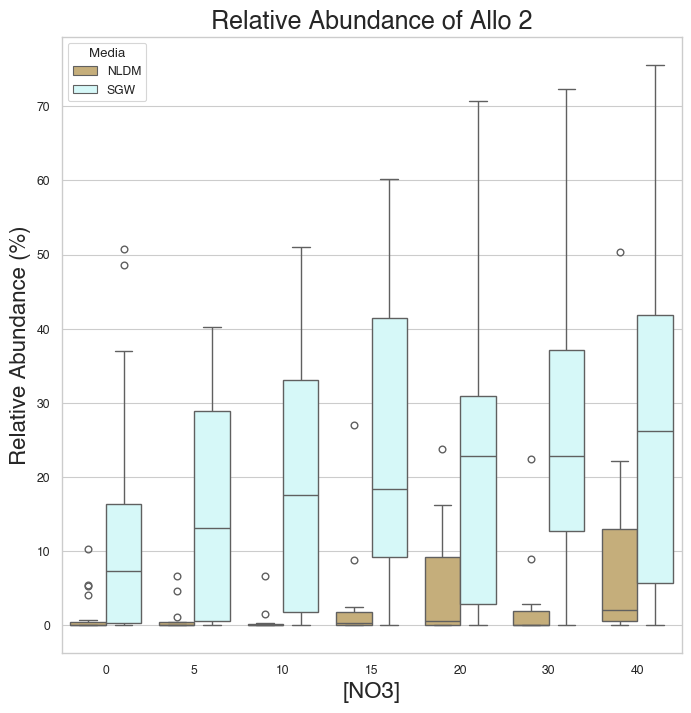

In [67]:
plot_bin_rel_abund_by_conds(bin_id='Bin_2',x_cond='[NO3]',hue_cond='Media')

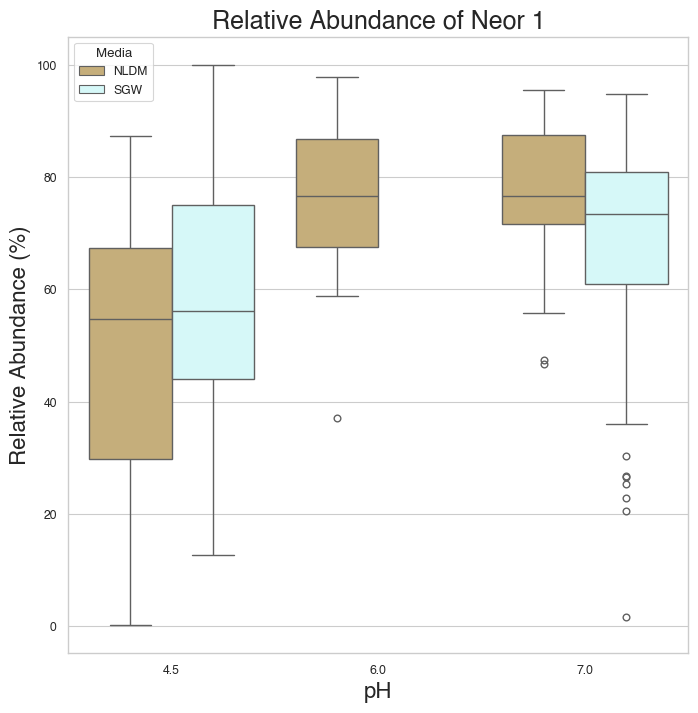

In [68]:
plot_bin_rel_abund_by_conds(bin_id='Bin_1',x_cond='pH',hue_cond='Media')

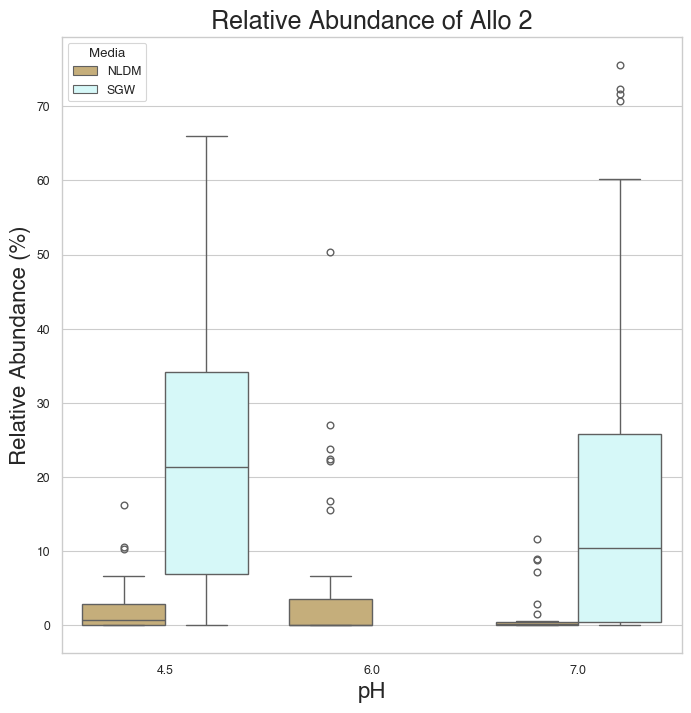

In [69]:
plot_bin_rel_abund_by_conds(bin_id='Bin_2',x_cond='pH',hue_cond='Media')

In [70]:
#Check for pairwise differences by pH, separating by media (or not)
def calc_genus_abund_pval_by_pH(genus='Arthrobacter',media='both'):
    
    #Zeroth item is a spelling error check 
    if genus not in bin_genus_dict.values():
        raise ValueError(f'Must specify genus name properly. Available genera: {sorted(set(bin_genus_dict.values()))}')
    
    #First thing to do is collect a list of bins belonging to the specified genus so we can parse the bin_abunds_df_rel_info    
    b_list = []
    for k,v in bin_genus_dict.items():
        if bin_genus_dict[k] == genus:
            b_list.append(k)
    #Now subset the df for this genus
    df_g = bin_abunds_df_rel_info[bin_abunds_df_rel_info.bins.isin(b_list)]
    
    #Option to separate the results by which media is surveyed
    if media == 'both':
        df_g = df_g
    elif media == 'NLDM':
        df_g = df_g[df_g['Media']=='NLDM']
    elif media == 'SGW':
        df_g = df_g[df_g['Media']=='SGW']

    #Now create a separate list of abundance values for each pH
    abunds_4 = df_g[df_g['pH']==4.5]['value'] #abundances of the genus at pH 4.5
    abunds_6 = df_g[df_g['pH']==6]['value'] #abundances of the genus at pH 6
    abunds_7 = df_g[df_g['pH']==7]['value'] #abundances of the genus at pH 7

    #Calculate the mean abundance for each pH
    mean_4 = abunds_4.mean() #mean abundace of genus at pH 4.5
    mean_6 = abunds_6.mean() #mean abundace of genus at pH 6
    mean_7 = abunds_7.mean() #mean abundace of genus at pH 7

    #Run a t-test for each of the combinations
    
    t_47,p_47 = ttest_ind(abunds_4,abunds_7,nan_policy='omit')
    if media != 'SGW': #SGW has no pH 6
        t_46,p_46 = ttest_ind(abunds_4,abunds_6,nan_policy='omit')
        t_67,p_67 = ttest_ind(abunds_6,abunds_7,nan_policy='omit')
    elif media == 'SGW':
        p_46,p_67 = 1,1 #setting to 1 to bypass print filters below

    #Report results if significant
    if p_46 < 0.05:
        if mean_4 > mean_6:
            print(f'{genus} more abundant in pH 4.5 ({mean_4:.2f}%) than 6 ({mean_6:.2f}%) \t p = {p_46:.2e}')
        elif mean_6 > mean_4:
            print(f'{genus} more abundant in pH 6 ({mean_6:.2f}%) than 4.5 ({mean_4:.2f}%) \t p = {p_46:.2e}')
    #elif p_46 > 0.05:
    #    print(f'No significant difference in abundance of {genus} between pH 4.5 and 6 \t p = {p_46:.2f}.')
    #elif p_46 == np.nan:
    #    print(f'No significant difference in abundance of {genus} between pH 4.5 and 6 \t p = {p_46:.2f}.')

    if p_47 < 0.05:
        if mean_4 > mean_7:
            print(f'{genus} more abundant in pH 4.5 ({mean_4:.2f}%) than 7 ({mean_7:.2f}%) \t p = {p_47:.2e}')
        elif mean_7 > mean_4:
            print(f'{genus} more abundant in pH 7 ({mean_7:.2f}%) than 4.5 ({mean_4:.2f}%) \t p = {p_47:.2e}')
    #elif p_47 > 0.05:
    #    print(f'No significant difference in abundance of {genus} between pH 4.5 and 7 \t p = {p_47:.2f}.')
    #elif p_47 == np.nan:
    #    print(f'No significant difference in abundance of {genus} between pH 4.5 and 7 \t p = {p_47:.2f}.')
    
    if p_67 < 0.05:
        if mean_6 > mean_7:
            print(f'{genus} more abundant in pH 6 ({mean_6:.2f}%) than 7 ({mean_7:.2f}%) \t p = {p_67:.2e}')
        elif mean_7 > mean_6:
            print(f'{genus} more abundant in pH 7 ({mean_7:.2f}%) than 6 ({mean_6:.2f}%) \t p = {p_67:.2e}')
    #elif p_67 > 0.05:
    #    print(f'No significant difference in abundance of {genus} between pH 6 and 7 \t p = {p_67:.2f}.')
    #elif p_67 == np.nan:
    #    print(f'No significant difference in abundance of {genus} between pH 6 and 7 \t p = {p_67:.2f}.')
    #print('')
    #return [p_46,p_47,p_67]

calc_genus_abund_pval_by_pH(genus='Arthrobacter',media='both')

Arthrobacter more abundant in pH 4.5 (1.26%) than 6 (0.23%) 	 p = 1.69e-03
Arthrobacter more abundant in pH 4.5 (1.26%) than 7 (0.18%) 	 p = 7.05e-11


In [71]:
for g in sorted(set(bin_genus_dict.values())):
    calc_genus_abund_pval_by_pH(genus=g,media='NLDM')

Allorhizobium more abundant in pH 6 (5.94%) than 7 (1.35%) 	 p = 3.62e-02
Arthrobacter more abundant in pH 4.5 (3.52%) than 6 (0.23%) 	 p = 1.68e-08
Arthrobacter more abundant in pH 4.5 (3.52%) than 7 (0.37%) 	 p = 6.71e-08
Arthrobacter more abundant in pH 7 (0.37%) than 6 (0.23%) 	 p = 3.28e-02
Cellulomonas more abundant in pH 7 (2.47%) than 6 (0.00%) 	 p = 4.44e-02
Lysinibacillus more abundant in pH 6 (3.00%) than 7 (0.94%) 	 p = 1.41e-02
Mesobacillus more abundant in pH 6 (0.70%) than 4.5 (0.02%) 	 p = 2.31e-02
Mesobacillus more abundant in pH 6 (0.70%) than 7 (0.05%) 	 p = 2.91e-02
Neorhizobium more abundant in pH 6 (40.82%) than 4.5 (27.46%) 	 p = 2.56e-02
Neorhizobium more abundant in pH 7 (43.22%) than 4.5 (27.46%) 	 p = 5.98e-03
Paenarthrobacter more abundant in pH 4.5 (0.65%) than 7 (0.12%) 	 p = 1.93e-02
Paenibacillus more abundant in pH 4.5 (0.22%) than 7 (0.03%) 	 p = 1.79e-02
Robertmurraya more abundant in pH 6 (0.44%) than 4.5 (0.04%) 	 p = 2.15e-03
Robertmurraya more abu

In [72]:
for g in sorted(set(bin_genus_dict.values())):
    calc_genus_abund_pval_by_pH(genus=g,media='SGW')

Allorhizobium more abundant in pH 4.5 (22.46%) than 7 (16.49%) 	 p = 2.48e-02
Arthrobacter more abundant in pH 4.5 (0.50%) than 7 (0.11%) 	 p = 3.88e-05
Microbacterium more abundant in pH 4.5 (0.75%) than 7 (0.16%) 	 p = 1.00e-02
Paraburkholderia more abundant in pH 4.5 (0.45%) than 7 (0.01%) 	 p = 4.32e-02
Streptomyces more abundant in pH 7 (0.24%) than 4.5 (0.06%) 	 p = 1.25e-04
Unclassified more abundant in pH 4.5 (0.92%) than 7 (0.14%) 	 p = 3.95e-07


In [73]:
calc_genus_abund_pval_by_pH(genus='Allorhizobium',media='both')

Allorhizobium more abundant in pH 4.5 (17.44%) than 6 (5.94%) 	 p = 5.78e-04
Allorhizobium more abundant in pH 4.5 (17.44%) than 7 (12.70%) 	 p = 3.31e-02
Allorhizobium more abundant in pH 7 (12.70%) than 6 (5.94%) 	 p = 4.33e-02


In [74]:
calc_genus_abund_pval_by_pH(genus='Neorhizobium',media='both')

Neorhizobium more abundant in pH 6 (40.82%) than 4.5 (29.90%) 	 p = 1.68e-02
Neorhizobium more abundant in pH 7 (38.63%) than 4.5 (29.90%) 	 p = 3.02e-03


In [75]:
calc_genus_abund_pval_by_pH(genus='Arthrobacter',media='both')

Arthrobacter more abundant in pH 4.5 (1.26%) than 6 (0.23%) 	 p = 1.69e-03
Arthrobacter more abundant in pH 4.5 (1.26%) than 7 (0.18%) 	 p = 7.05e-11


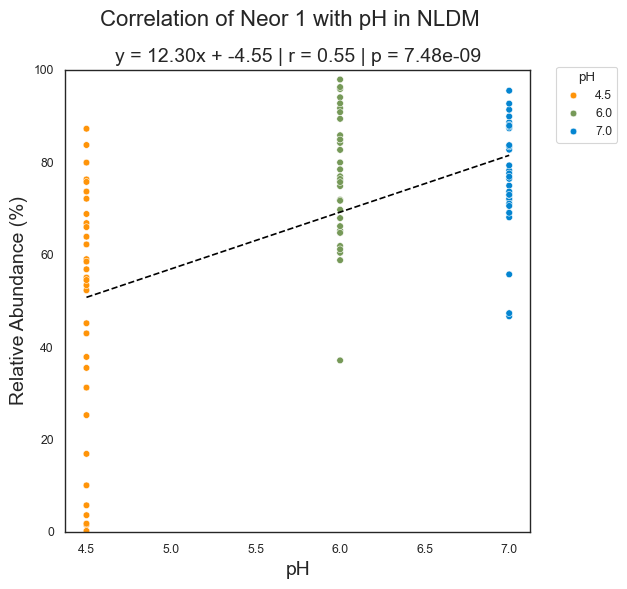

In [76]:
#Check whether there's a correlation of relative abundance with NO3- or pH
def calc_plot_linear_regression_by_bin_cond(bin_id='Bin_1',cond='[NO3]',media='NLDM',sig=True):

    #bin_abunds_df_rel_info is a melted df with each line having relative abundance for a single sample linked with metadata
    df = bin_abunds_df_rel_info[bin_abunds_df_rel_info['bins']==bin_id].copy(deep=True) #Subset the df for the bin of interest
    if media !='Both':
        df = df[df['Media']==media]
    x_series = df[cond] #get the data for the x axis, must be numerical
    y_series = df['value'] #this is the relative abundance, should not change

    if cond == 'C source':
        raise ValueError("You can't do a linear regression on categorical data. That's silly.")

    #Do the linear regression to create a results object
    results = linregress(x=x_series,y=y_series)
    pval = results.pvalue
    rval = results.rvalue
    slope = results.slope
    intercept = results.intercept

    if sig == True:
        if pval > 0.05:
            return print(f'{bin_label_rename_dict[bin_id]} not significantly correlated with {cond} in {media} media.')

    if cond == 'pH':
        cond_pal = pH_palette
    elif cond == '[NO3]':
        cond_pal = no3_palette
    elif cond == 'C source':
        cond_pal == c_palette

    sns.set_style('white')
    plt.figure(figsize=(6,6))
    plt.ylim((0,100))
    sns.scatterplot(df,x=cond,y='value',color='black',hue=cond,palette=cond_pal)
    plt.plot(x_series.unique(), slope*x_series.unique() + intercept,color='black',ls='--')
    plt.legend(loc=1,bbox_to_anchor=(1.2,1.02),title=cond)
    plt.ylabel('Relative Abundance (%)',fontsize=14)
    plt.xlabel(f'{cond}',fontsize=14)
    plt.suptitle(f'Correlation of {bin_label_rename_dict[bin_id]} with {cond} in {media}',fontsize=16)
    plt.title(f'y = {slope:.2f}x + {intercept:.2f} | r = {rval:.2f} | p = {pval:.2e}',fontsize=14)
    plt.show()

    return 

calc_plot_linear_regression_by_bin_cond(bin_id='Bin_1',cond='pH')

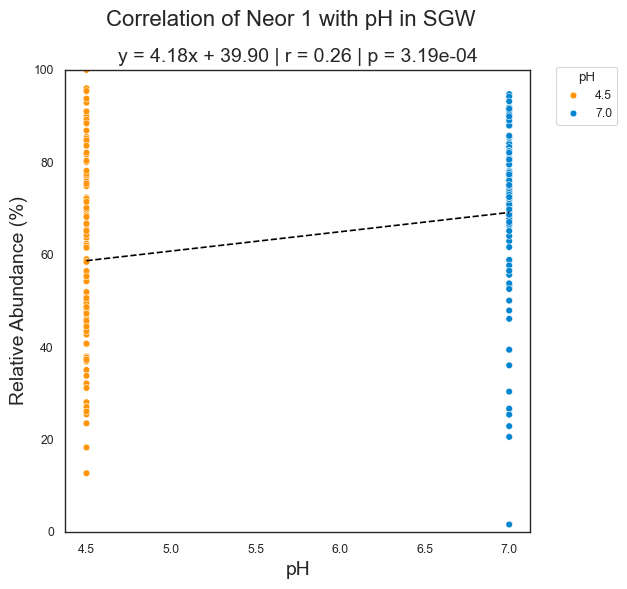

In [77]:
calc_plot_linear_regression_by_bin_cond(bin_id='Bin_1',cond='pH',media='SGW')

In [78]:
calc_plot_linear_regression_by_bin_cond(bin_id='Bin_1',cond='[NO3]')

Neor 1 not significantly correlated with [NO3] in NLDM media.


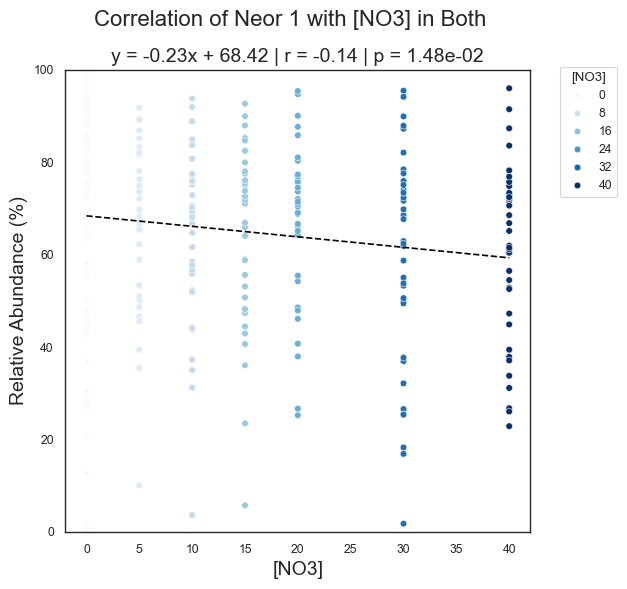

In [79]:
calc_plot_linear_regression_by_bin_cond(bin_id='Bin_1',cond='[NO3]',media='Both')

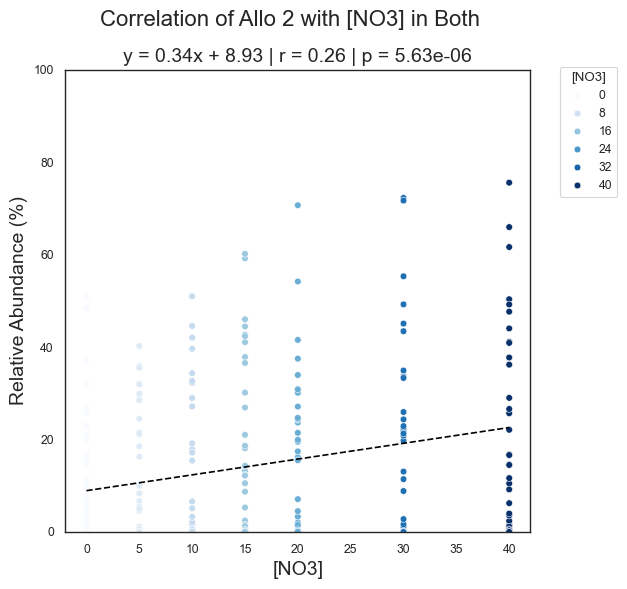

In [80]:
calc_plot_linear_regression_by_bin_cond(bin_id='Bin_2',cond='[NO3]',media='Both')

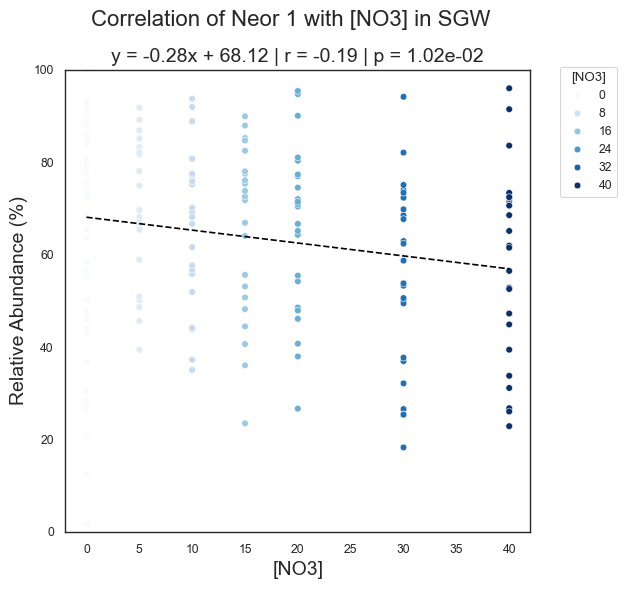

In [81]:
calc_plot_linear_regression_by_bin_cond(bin_id='Bin_1',cond='[NO3]',media='SGW')

In [82]:
calc_plot_linear_regression_by_bin_cond(bin_id='Bin_2',cond='pH')

Allo 2 not significantly correlated with pH in NLDM media.


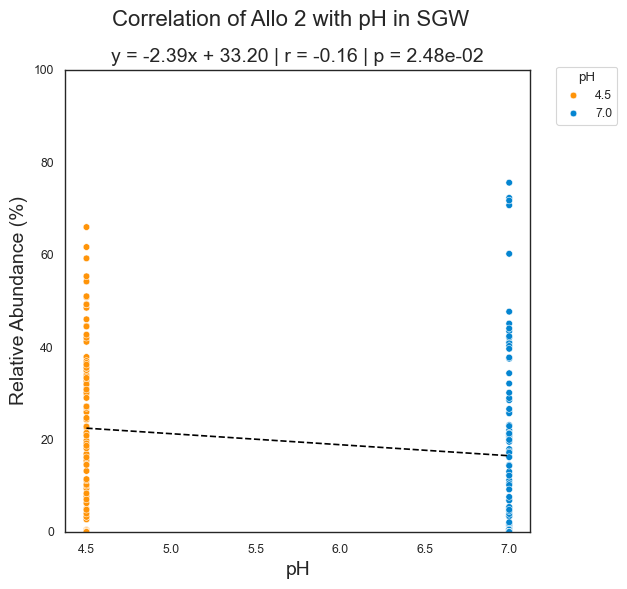

In [83]:
calc_plot_linear_regression_by_bin_cond(bin_id='Bin_2',cond='pH',media='SGW')

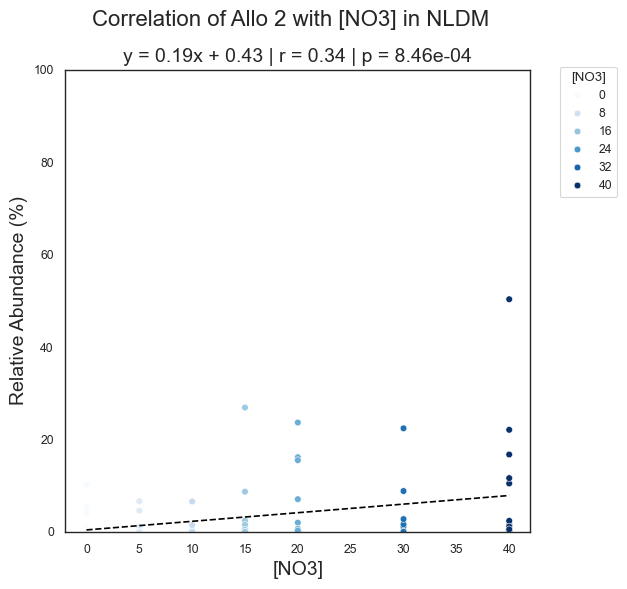

In [84]:
calc_plot_linear_regression_by_bin_cond(bin_id='Bin_2',cond='[NO3]')

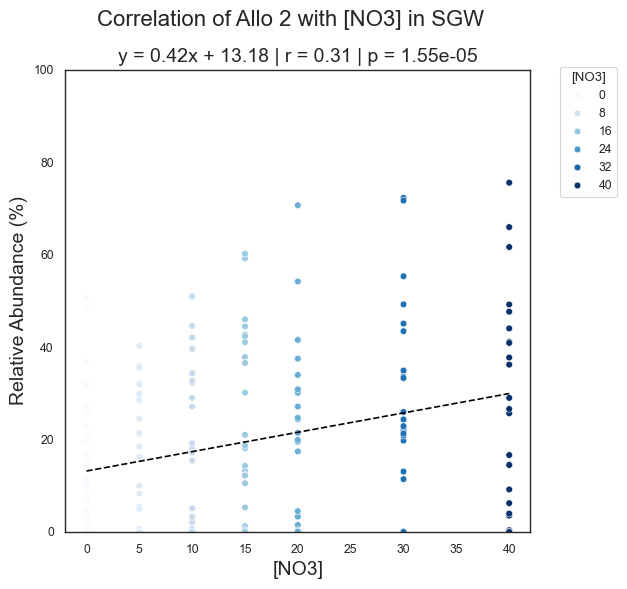

In [85]:
calc_plot_linear_regression_by_bin_cond(bin_id='Bin_2',cond='[NO3]',media='SGW')

In [86]:
#for b in bin_order:
#    calc_plot_linear_regression_by_bin_cond(bin_id=b,cond='pH')

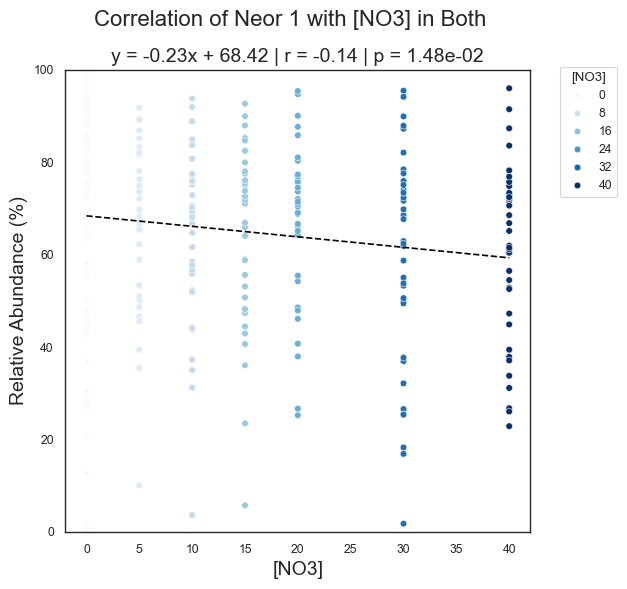

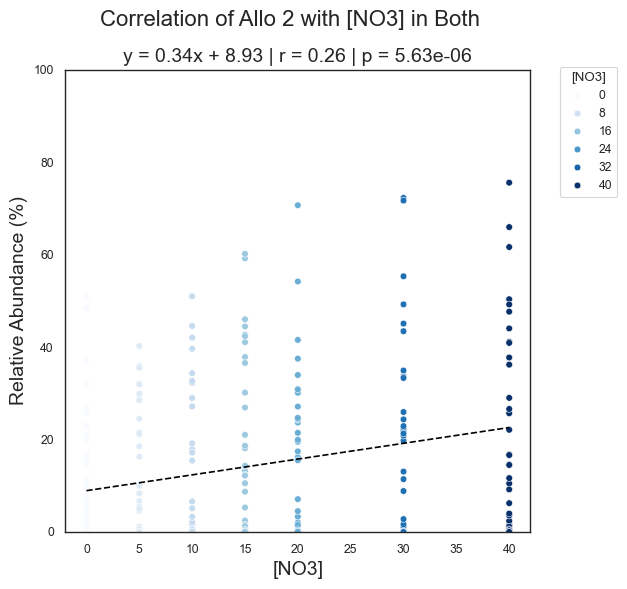

Lysi 3 not significantly correlated with [NO3] in Both media.
Neor 4 not significantly correlated with [NO3] in Both media.
Robe 5 not significantly correlated with [NO3] in Both media.
Arth 6 not significantly correlated with [NO3] in Both media.
Paen 7 not significantly correlated with [NO3] in Both media.
Meso 8 not significantly correlated with [NO3] in Both media.
Noca 9 not significantly correlated with [NO3] in Both media.
Lacu 10 not significantly correlated with [NO3] in Both media.
Arth 11 not significantly correlated with [NO3] in Both media.
Arth 12 not significantly correlated with [NO3] in Both media.
Para 13 not significantly correlated with [NO3] in Both media.
Baci 14 not significantly correlated with [NO3] in Both media.
Arth 15 not significantly correlated with [NO3] in Both media.
Jani 16 not significantly correlated with [NO3] in Both media.
17 not significantly correlated with [NO3] in Both media.
Arth 18 not significantly correlated with [NO3] in Both media.
Arth

In [87]:
for b in bin_order:
    calc_plot_linear_regression_by_bin_cond(bin_id=b,cond='[NO3]',media='Both')

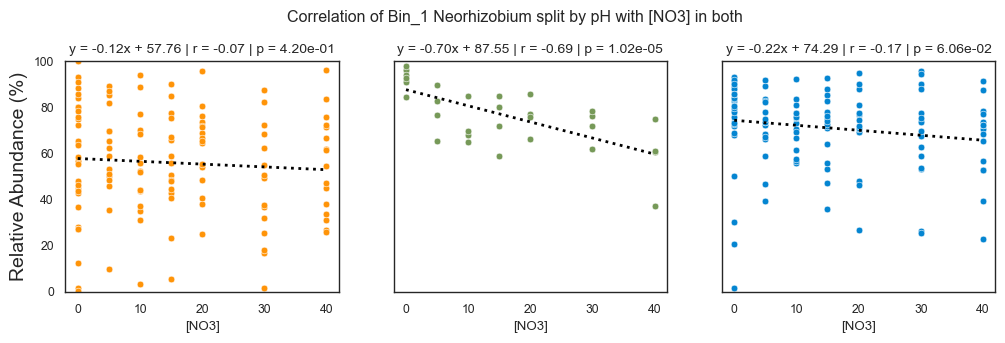

In [88]:
#pH and [NO3] play compounding roles here, so let's split them up further to check
def calc_plot_linear_regression_by_bin_multi(bin_id='Bin_1',media='NLDM'):

    #bin_abunds_df_rel_info is a melted df with each line having relative abundance for a single sample linked with metadata
    df = bin_abunds_df_rel_info[bin_abunds_df_rel_info['bins']==bin_id].copy(deep=True) #Subset the df for the bin of interest
    if media != 'both':
        df = df[df['Media']==media] #SGW does not have pH 6, so let's check that we aren't biasing this
    #I checked this for just NLDM and the pattern is the same. Only pH 6 shows a significant correlation with [NO3]
    df_4 = df[df['pH']==4.5]
    df_6 = df[df['pH']==6]
    df_7 = df[df['pH']==7]

    x_series_4 = df_4['[NO3]'] #[NO3] range list
    y_series_4 = df_4['value'] #relative abundance data

    x_series_6 = df_6['[NO3]'] #[NO3] range list
    y_series_6 = df_6['value'] #relative abundance data

    x_series_7 = df_7['[NO3]'] #[NO3] range list
    y_series_7 = df_7['value'] #relative abundance data

    #Do the linear regression to create results objects for each pH
    results_4 = linregress(x=x_series_4,y=y_series_4)
    pval_4 = results_4.pvalue
    rval_4 = results_4.rvalue
    slope_4 = results_4.slope
    intercept_4 = results_4.intercept

    if media == 'NLDM' or media == 'both':
        results_6 = linregress(x=x_series_6,y=y_series_6)
        pval_6 = results_6.pvalue
        rval_6 = results_6.rvalue
        slope_6 = results_6.slope
        intercept_6 = results_6.intercept

    elif media == 'SGW':
        results_6 = np.nan
        pval_6 = np.nan
        rval_6 = np.nan
        slope_6 = np.nan
        intercept_6 = np.nan

    results_7 = linregress(x=x_series_7,y=y_series_7)
    pval_7 = results_7.pvalue
    rval_7 = results_7.rvalue
    slope_7 = results_7.slope
    intercept_7 = results_7.intercept

    fig,ax = plt.subplots(ncols=3,nrows=1,figsize=(12,3),sharex=True,sharey=True)
    sns.scatterplot(df_4,x='[NO3]',y='value',color='xkcd:tangerine',ax=ax[0])
    ax[0].set_ylim((0,100))
    ax[0].plot(x_series_4.unique(), slope_4*x_series_4.unique() + intercept_4,color='black',ls=':',lw=2)
    ax[0].set_ylabel('Relative Abundance (%)',fontsize=14)
    ax[0].set_title(f'y = {slope_4:.2f}x + {intercept_4:.2f} | r = {rval_4:.2f} | p = {pval_4:.2e}',fontsize=10)

    sns.scatterplot(df_6,x='[NO3]',y='value',color='xkcd:moss',ax=ax[1])
    ax[1].plot(x_series_6.unique(), slope_6*x_series_6.unique() + intercept_6,color='black',ls=':',lw=2)
    ax[1].set_ylabel('Relative Abundance (%)',fontsize=14)
    ax[1].set_title(f'y = {slope_6:.2f}x + {intercept_6:.2f} | r = {rval_6:.2f} | p = {pval_6:.2e}',fontsize=10)

    if media == 'SGW':
        ax[1].axis('off')
        ax[1].set_title('')

    sns.scatterplot(df_7,x='[NO3]',y='value',color='xkcd:cerulean',ax=ax[2])
    ax[2].plot(x_series_7.unique(), slope_7*x_series_7.unique() + intercept_7,color='black',ls=':',lw=2)
    ax[2].set_ylabel('Relative Abundance (%)',fontsize=14)
    ax[2].set_title(f'y = {slope_7:.2f}x + {intercept_7:.2f} | r = {rval_7:.2f} | p = {pval_7:.2e}',fontsize=10)

    plt.suptitle(f'Correlation of {bin_id} {bin_genus_dict[bin_id]} split by pH with [NO3] in {media}',y=1.05)
    #plt.show()

    #return

calc_plot_linear_regression_by_bin_multi(bin_id='Bin_1',media='both')

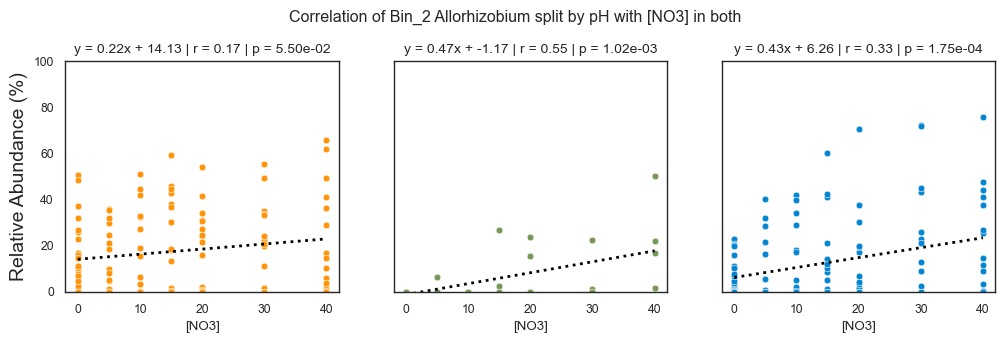

In [89]:
calc_plot_linear_regression_by_bin_multi(bin_id='Bin_2',media='both')

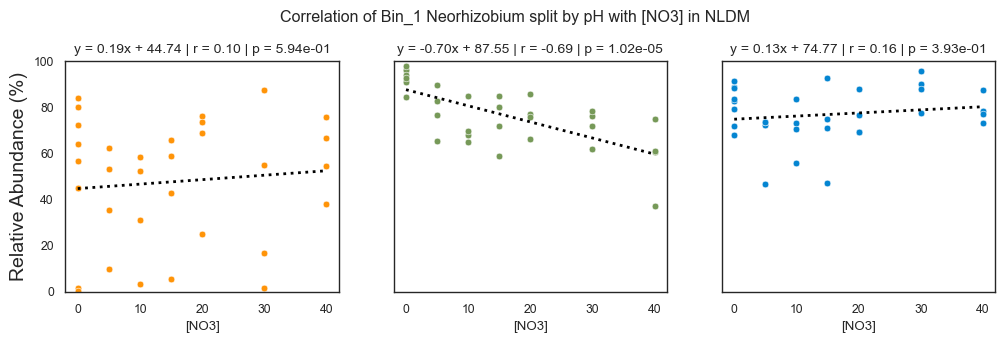

In [90]:
calc_plot_linear_regression_by_bin_multi(bin_id='Bin_1',media='NLDM')
#plt.savefig('./figs/B1_pH_NO3_corr_plot.png',dpi=300,bbox_inches='tight')

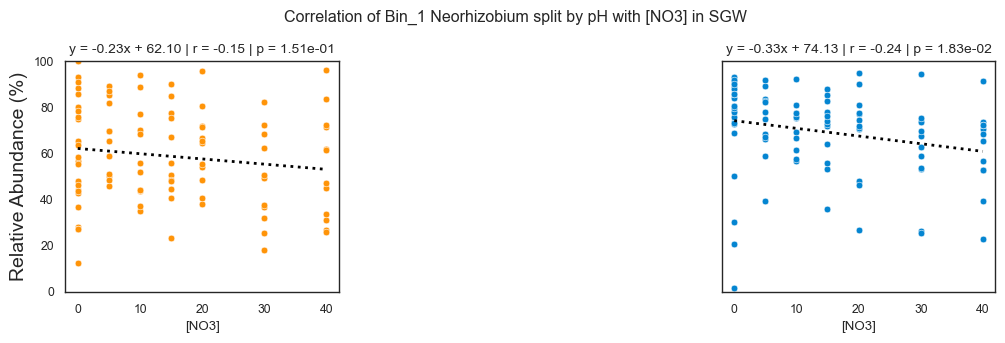

In [91]:
calc_plot_linear_regression_by_bin_multi(bin_id='Bin_1',media='SGW')

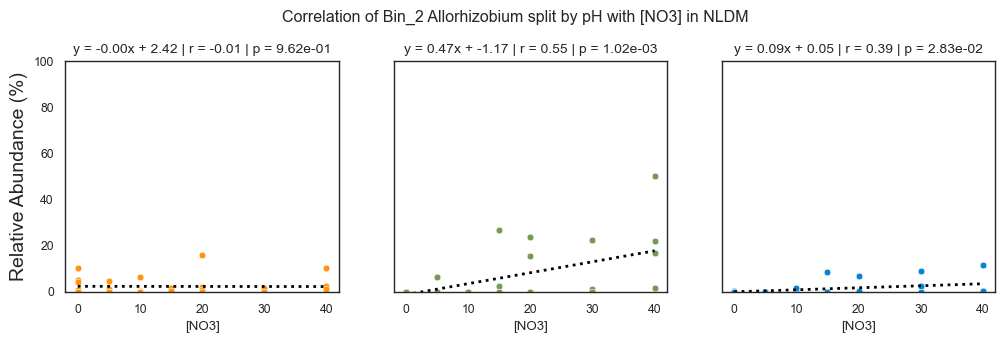

In [92]:
calc_plot_linear_regression_by_bin_multi(bin_id='Bin_2',media='NLDM')
#plt.savefig('./figs/B2_pH_NO3_corr_plot.png',dpi=300,bbox_inches='tight')

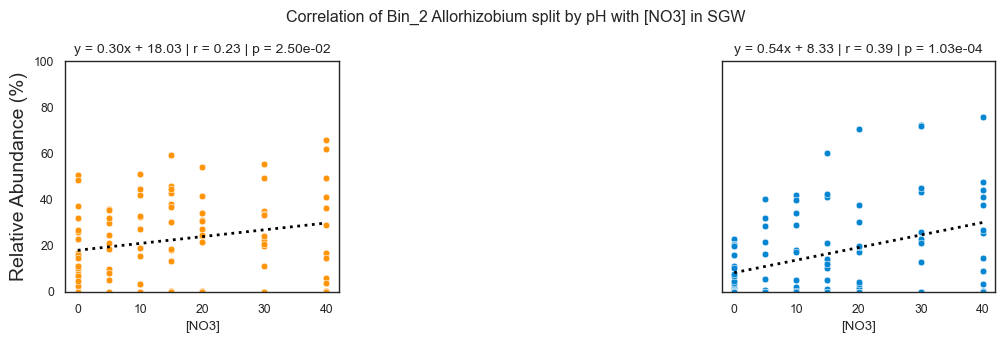

In [93]:
calc_plot_linear_regression_by_bin_multi(bin_id='Bin_2',media='SGW')

In [94]:
#for b in bin_order:
#    calc_plot_linear_regression_by_bin_multi(bin_id=b)

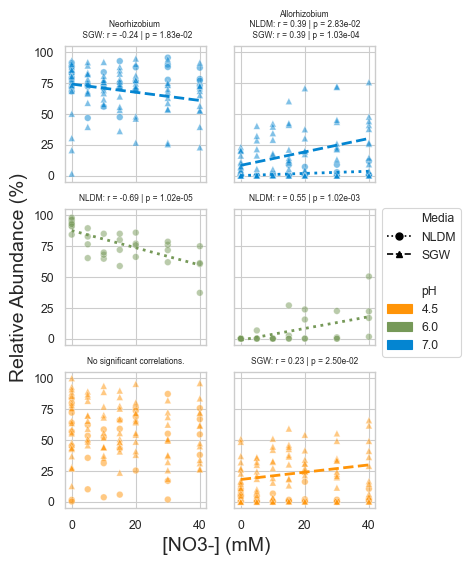

Neorhizobium:
NLDM pH 4.5: y = 0.19x + 44.74 | r = 0.10 | p = 5.94e-01
SGW pH 4.5: y = -0.23x + 62.10 | r = -0.15 | p = 1.51e-01
NLDM pH 6: y = -0.70x + 87.55 | r = -0.69 | p = 1.02e-05
NLDM pH 7: y = 0.13x + 74.77 | r = 0.16 | p = 3.93e-01
SGW pH 7: y = -0.33x + 74.13 | r = -0.24 | p = 1.83e-02

Allorhizobium:
NLDM pH 4.5: y = -0.00x + 2.42 | r = -0.01 | p = 9.62e-01
SGW pH 4.5: y = 0.30x + 18.03 | r = 0.23 | p = 2.50e-02
NLDM pH 6: y = 0.47x + -1.17 | r = 0.55 | p = 1.02e-03
NLDM pH 7: y = 0.09x + 0.05 | r = 0.39 | p = 2.83e-02
SGW pH 7: y = 0.54x + 8.33 | r = 0.39 | p = 1.03e-04


In [95]:
#Make a combined plot here for Neorhizobium and Allorhizobium for Figure 1

def calc_plot_linear_regression_for_B1_B2():

    #bin_abunds_df_rel_info is a melted df with each line having relative abundance for a single sample linked with metadata
    df1 = bin_abunds_df_rel_info[bin_abunds_df_rel_info['bins']=='Bin_1'].copy(deep=True) #Subset the df for the bin of interest
    df1_NLDM = df1[df1['Media']=='NLDM'] #Split the data by medium to calculate correlations separately; create the NLDM df
    df1_SGW = df1[df1['Media']=='SGW'] #Create the SGW df

    #Create dfs for each pH with both media for plotting all the data together
    df1_4 = df1[df1['pH']==4.5]
    df1_6 = df1[df1['pH']==6]
    df1_7 = df1[df1['pH']==7]

    #Run the linear regressions for the NLDM data to read in later
    df1_4_NLDM = df1_NLDM[df1_NLDM['pH']==4.5]
    df1_6_NLDM = df1_NLDM[df1_NLDM['pH']==6]
    df1_7_NLDM = df1_NLDM[df1_NLDM['pH']==7]

    x_series1_4_NLDM = df1_4_NLDM['[NO3]'] #[NO3] range list
    y_series1_4_NLDM = df1_4_NLDM['value'] #relative abundance data

    x_series1_6_NLDM = df1_6_NLDM['[NO3]'] #[NO3] range list
    y_series1_6_NLDM = df1_6_NLDM['value'] #relative abundance data

    x_series1_7_NLDM = df1_7_NLDM['[NO3]'] #[NO3] range list
    y_series1_7_NLDM = df1_7_NLDM['value'] #relative abundance data

    #Do the linear regression to create results objects for each pH
    results1_4_NLDM = linregress(x=x_series1_4_NLDM,y=y_series1_4_NLDM)
    pval1_4_NLDM = results1_4_NLDM.pvalue
    rval1_4_NLDM = results1_4_NLDM.rvalue
    r2val1_4_NLDM = rval1_4_NLDM*rval1_4_NLDM
    slope1_4_NLDM = results1_4_NLDM.slope
    intercept1_4_NLDM = results1_4_NLDM.intercept

    results1_6_NLDM = linregress(x=x_series1_6_NLDM,y=y_series1_6_NLDM)
    pval1_6_NLDM = results1_6_NLDM.pvalue
    rval1_6_NLDM = results1_6_NLDM.rvalue
    r2val1_6_NLDM = rval1_6_NLDM*rval1_6_NLDM
    slope1_6_NLDM = results1_6_NLDM.slope
    intercept1_6_NLDM = results1_6_NLDM.intercept


    results1_7_NLDM = linregress(x=x_series1_7_NLDM,y=y_series1_7_NLDM)
    pval1_7_NLDM = results1_7_NLDM.pvalue
    rval1_7_NLDM = results1_7_NLDM.rvalue
    r2val1_7_NLDM = rval1_7_NLDM*rval1_7_NLDM
    slope1_7_NLDM = results1_7_NLDM.slope
    intercept1_7_NLDM = results1_7_NLDM.intercept


    #Repeat for SGW but only for pH 4.5 and 7
    df1_4_SGW = df1_SGW[df1_SGW['pH']==4.5]
    df1_7_SGW = df1_SGW[df1_SGW['pH']==7]

    x_series1_4_SGW = df1_4_SGW['[NO3]'] #[NO3] range list
    y_series1_4_SGW = df1_4_SGW['value'] #relative abundance data

    x_series1_7_SGW = df1_7_SGW['[NO3]'] #[NO3] range list
    y_series1_7_SGW = df1_7_SGW['value'] #relative abundance data

    #Do the linear regression to create results objects for each pH
    results1_4_SGW = linregress(x=x_series1_4_SGW,y=y_series1_4_SGW)
    pval1_4_SGW = results1_4_SGW.pvalue
    rval1_4_SGW = results1_4_SGW.rvalue
    r2val1_4_SGW = rval1_4_SGW*rval1_4_SGW
    slope1_4_SGW = results1_4_SGW.slope
    intercept1_4_SGW = results1_4_SGW.intercept

    results1_7_SGW = linregress(x=x_series1_7_SGW,y=y_series1_7_SGW)
    pval1_7_SGW = results1_7_SGW.pvalue
    rval1_7_SGW = results1_7_SGW.rvalue
    r2val1_7_SGW = rval1_7_SGW*rval1_7_SGW
    slope1_7_SGW = results1_7_SGW.slope
    intercept1_7_SGW = results1_7_SGW.intercept

    #bin_abunds_df_rel_info is a melted df with each line having relative abundance for a single sample linked with metadata
    df2 = bin_abunds_df_rel_info[bin_abunds_df_rel_info['bins']=='Bin_2'].copy(deep=True) #Subset the df for the bin of interest
    df2_NLDM = df2[df2['Media']=='NLDM'] #Split the data by medium to calculate correlations separately; create the NLDM df
    df2_SGW = df2[df2['Media']=='SGW'] #Create the SGW df

    #Create dfs for each pH with both media for plotting all the data together
    df2_4 = df2[df2['pH']==4.5]
    df2_6 = df2[df2['pH']==6]
    df2_7 = df2[df2['pH']==7]

    #Run the linear regressions for the NLDM data to read in later
    df2_4_NLDM = df2_NLDM[df2_NLDM['pH']==4.5]
    df2_6_NLDM = df2_NLDM[df2_NLDM['pH']==6]
    df2_7_NLDM = df2_NLDM[df2_NLDM['pH']==7]

    x_series2_4_NLDM = df2_4_NLDM['[NO3]'] #[NO3] range list
    y_series2_4_NLDM = df2_4_NLDM['value'] #relative abundance data

    x_series2_6_NLDM = df2_6_NLDM['[NO3]'] #[NO3] range list
    y_series2_6_NLDM = df2_6_NLDM['value'] #relative abundance data

    x_series2_7_NLDM = df2_7_NLDM['[NO3]'] #[NO3] range list
    y_series2_7_NLDM = df2_7_NLDM['value'] #relative abundance data

    #Do the linear regression to create results objects for each pH
    results2_4_NLDM = linregress(x=x_series2_4_NLDM,y=y_series2_4_NLDM)
    pval2_4_NLDM = results2_4_NLDM.pvalue
    rval2_4_NLDM = results2_4_NLDM.rvalue
    r2val2_4_NLDM = rval2_4_NLDM*rval2_4_NLDM
    slope2_4_NLDM = results2_4_NLDM.slope
    intercept2_4_NLDM = results2_4_NLDM.intercept

    results2_6_NLDM = linregress(x=x_series2_6_NLDM,y=y_series2_6_NLDM)
    pval2_6_NLDM = results2_6_NLDM.pvalue
    rval2_6_NLDM = results2_6_NLDM.rvalue
    r2val2_6_NLDM = rval2_6_NLDM*rval2_6_NLDM
    slope2_6_NLDM = results2_6_NLDM.slope
    intercept2_6_NLDM = results2_6_NLDM.intercept


    results2_7_NLDM = linregress(x=x_series2_7_NLDM,y=y_series2_7_NLDM)
    pval2_7_NLDM = results2_7_NLDM.pvalue
    rval2_7_NLDM = results2_7_NLDM.rvalue
    r2val2_7_NLDM = rval2_7_NLDM*rval2_7_NLDM
    slope2_7_NLDM = results2_7_NLDM.slope
    intercept2_7_NLDM = results2_7_NLDM.intercept


    #Repeat for SGW but only for pH 4.5 and 7
    df2_4_SGW = df2_SGW[df2_SGW['pH']==4.5]
    df2_7_SGW = df2_SGW[df2_SGW['pH']==7]

    x_series2_4_SGW = df2_4_SGW['[NO3]'] #[NO3] range list
    y_series2_4_SGW = df2_4_SGW['value'] #relative abundance data

    x_series2_7_SGW = df2_7_SGW['[NO3]'] #[NO3] range list
    y_series2_7_SGW = df2_7_SGW['value'] #relative abundance data

    #Do the linear regression to create results objects for each pH
    results2_4_SGW = linregress(x=x_series2_4_SGW,y=y_series2_4_SGW)
    pval2_4_SGW = results2_4_SGW.pvalue
    rval2_4_SGW = results2_4_SGW.rvalue
    r2val2_4_SGW = rval2_4_SGW*rval2_4_SGW
    slope2_4_SGW = results2_4_SGW.slope
    intercept2_4_SGW = results2_4_SGW.intercept

    results2_7_SGW = linregress(x=x_series2_7_SGW,y=y_series2_7_SGW)
    pval2_7_SGW = results2_7_SGW.pvalue
    rval2_7_SGW = results2_7_SGW.rvalue
    r2val2_7_SGW = rval2_7_SGW*rval2_7_SGW
    slope2_7_SGW = results2_7_SGW.slope
    intercept2_7_SGW = results2_7_SGW.intercept

    media_markers = {'NLDM':'o','SGW':'^'}

    #Set up figure
    sns.set_style('whitegrid')
    fig,ax = plt.subplots(ncols=2,nrows=3,figsize=(4,6),sharex=True,sharey=True)

    #pH 4.5 panel
    sns.scatterplot(df1_4,x='[NO3]',y='value',color='xkcd:tangerine',style='Media',markers=media_markers,alpha=0.5,ax=ax[2,0],legend=False)
    ax[2,0].set_ylim((-5,105))
    ax[2,0].set_ylabel('')
    #ax[2,0].set_ylabel('Relative Abundance (%)',fontsize=8)
    ax[2,0].set_xlabel('                              [NO3-] (mM)',fontsize=14)

    #Add p-value conditional options. 
    #If p > 0.05, don't draw line and don't print equation
    if pval1_4_NLDM <= 0.05:
        ax[2,0].plot(x_series1_4_NLDM.unique(), slope1_4_NLDM*x_series1_4_NLDM.unique() + intercept1_4_NLDM,color='xkcd:tangerine',ls=':',lw=2)
    if pval1_4_SGW <= 0.05:
        ax[2,0].plot(x_series1_4_SGW.unique(), slope1_4_SGW*x_series1_4_SGW.unique() + intercept1_4_SGW,color='xkcd:tangerine',ls='--',lw=2)
    if pval1_4_NLDM <= 0.05 and pval1_4_SGW <= 0.05:
        ax[2,0].set_title(f'NLDM: r = {rval1_4_NLDM:.2f} | p = {pval1_4_NLDM:.2e} \n \
                        SGW: r = {rval1_4_SGW:.2f} | p = {pval1_4_SGW:.2e}',fontsize=6)
    elif pval1_4_NLDM <= 0.05 and pval1_4_SGW > 0.05:
        ax[2,0].set_title(f'NLDM: r = {rval1_4_NLDM:.2f} | p = {pval1_4_NLDM:.2e}',fontsize=6)
    elif pval1_4_NLDM > 0.05 and pval1_4_SGW <= 0.05:
        ax[2,0].set_title(f'SGW: r = {rval1_4_SGW:.2f} | p = {pval1_4_SGW:.2e}',fontsize=6)
    elif pval1_4_NLDM > 0.05 and pval1_4_SGW > 0.05:
        ax[2,0].set_title('No significant correlations.',fontsize=6)

    #pH 6 panel
    sns.scatterplot(df1_6,x='[NO3]',y='value',color='xkcd:moss',style='Media',markers=media_markers,alpha=0.5,ax=ax[1,0],legend=False)
    ax[1,0].set_ylabel('Relative Abundance (%)',fontsize=14)
    #ax[0,1].set_xlabel(r'[NO$_3$$^-$]',fontsize=12)

    if pval1_6_NLDM <= 0.05:
        ax[1,0].plot(x_series1_6_NLDM.unique(), slope1_6_NLDM*x_series1_6_NLDM.unique() + intercept1_6_NLDM,color='xkcd:moss',ls=':',lw=2)
    if pval1_6_NLDM <= 0.05:
        ax[1,0].set_title(f'NLDM: r = {rval1_6_NLDM:.2f} | p = {pval1_6_NLDM:.2e}',fontsize=6)
    elif pval1_6_NLDM > 0.05:
        ax[1,0].set_title('No significant correlations.',fontsize=6)

    #pH 7 panel
    sns.scatterplot(df1_7,x='[NO3]',y='value',color='xkcd:cerulean',style='Media',markers=media_markers,alpha=0.5,ax=ax[0,0],legend=False)
    ax[0,0].set_ylabel('')
    #ax[0,2].set_xlabel(r'[NO$_3$$^-$]',fontsize=12)

    if pval1_7_NLDM <= 0.05:
        ax[0,0].plot(x_series1_7_NLDM.unique(), slope1_7_NLDM*x_series1_7_NLDM.unique() + intercept1_7_NLDM,color='xkcd:cerulean',ls=':',lw=2)
    if pval1_7_SGW <= 0.05:
        ax[0,0].plot(x_series1_7_SGW.unique(), slope1_7_SGW*x_series1_7_SGW.unique() + intercept1_7_SGW,color='xkcd:cerulean',ls='--',lw=2)
    
    if pval1_7_NLDM <= 0.05 and pval1_7_SGW <= 0.05:
        ax[0,0].set_title(f'Neorhizobium \n NLDM: r = {rval1_7_NLDM:.2f} | p = {pval1_7_NLDM:.2e} \n \
                          SGW: r = {rval1_7_SGW:.2f} | p = {pval1_7_SGW:.2e}',fontsize=6)
    elif pval1_7_NLDM <= 0.05 and pval1_7_SGW > 0.05:
        ax[0,0].set_title(f'Neorhizobium \n NLDM: r = {rval1_7_NLDM:.2f} | p = {pval1_7_NLDM:.2e}',fontsize=6)
    elif pval1_7_NLDM > 0.05 and pval1_7_SGW <= 0.05:
        ax[0,0].set_title(f'Neorhizobium \n SGW: r = {rval1_7_SGW:.2f} | p = {pval1_7_SGW:.2e}',fontsize=6)
    elif pval1_7_NLDM > 0.05 and pval1_7_SGW > 0.05:
        ax[0,0].set_title('No significant correlations.',fontsize=6)


    #pH 4.5 panel
    sns.scatterplot(df2_4,x='[NO3]',y='value',color='xkcd:tangerine',style='Media',markers=media_markers,alpha=0.5,ax=ax[2,1],legend=False)
    ax[2,1].set_ylim((-5,105))
    #ax[2,1].set_ylabel('Allorhizobium \n Relative Abundance (%)',fontsize=8)
    ax[2,1].set_xlabel('')

    #Add p-value conditional options. 
    #If p > 0.05, don't draw line and don't print equation
    if pval2_4_NLDM <= 0.05:
        ax[2,1].plot(x_series2_4_NLDM.unique(), slope2_4_NLDM*x_series2_4_NLDM.unique() + intercept2_4_NLDM,color='xkcd:tangerine',ls=':',lw=2)
    if pval2_4_SGW <= 0.05:
        ax[2,1].plot(x_series2_4_SGW.unique(), slope2_4_SGW*x_series2_4_SGW.unique() + intercept2_4_SGW,color='xkcd:tangerine',ls='--',lw=2)
    if pval2_4_NLDM <= 0.05 and pval2_4_SGW <= 0.05:
        ax[2,1].set_title(f'NLDM: r = {rval2_4_NLDM:.2f} | p = {pval2_4_NLDM:.2e} \n \
                          SGW: r = {rval2_4_SGW:.2f} | p = {pval2_4_SGW:.2e}',fontsize=6)
    elif pval2_4_NLDM <= 0.05 and pval2_4_SGW > 0.05:
        ax[2,1].set_title(f'NLDM: r = {rval2_4_NLDM:.2f} | p = {pval2_4_NLDM:.2e}',fontsize=6)
    elif pval2_4_NLDM > 0.05 and pval2_4_SGW <= 0.05:
        ax[2,1].set_title(f'SGW: r = {rval2_4_SGW:.2f} | p = {pval2_4_SGW:.2e}',fontsize=6)
    elif pval2_4_NLDM > 0.05 and pval2_4_SGW > 0.05:
        ax[2,1].set_title('No significant correlations.',fontsize=6)

    #pH 6 panel
    sns.scatterplot(df2_6,x='[NO3]',y='value',color='xkcd:moss',style='Media',markers=media_markers,alpha=0.5,ax=ax[1,1],legend=False)

    if pval2_6_NLDM <= 0.05:
        ax[1,1].plot(x_series2_6_NLDM.unique(), slope2_6_NLDM*x_series2_6_NLDM.unique() + intercept2_6_NLDM,color='xkcd:moss',ls=':',lw=2)
    if pval2_6_NLDM <= 0.05:
        ax[1,1].set_title(f'NLDM: r = {rval2_6_NLDM:.2f} | p = {pval2_6_NLDM:.2e}',fontsize=6)
    elif pval2_6_NLDM > 0.05:
        ax[1,1].set_title('No significant correlations.',fontsize=6)

    #pH 7 panel
    sns.scatterplot(df2_7,x='[NO3]',y='value',color='xkcd:cerulean',style='Media',markers=media_markers,alpha=0.5,ax=ax[0,1],legend=False)

    if pval2_7_NLDM <= 0.05:
        ax[0,1].plot(x_series2_7_NLDM.unique(), slope2_7_NLDM*x_series2_7_NLDM.unique() + intercept2_7_NLDM,color='xkcd:cerulean',ls=':',lw=2)
    if pval2_7_SGW <= 0.05:
        ax[0,1].plot(x_series2_7_SGW.unique(), slope2_7_SGW*x_series2_7_SGW.unique() + intercept2_7_SGW,color='xkcd:cerulean',ls='--',lw=2)
    
    if pval2_7_NLDM <= 0.05 and pval2_7_SGW <= 0.05:
        ax[0,1].set_title(f'Allorhizobium \n NLDM: r = {rval2_7_NLDM:.2f} | p = {pval2_7_NLDM:.2e} \n SGW: r = {rval2_7_SGW:.2f} | p = {pval2_7_SGW:.2e}',fontsize=6)
    elif pval2_7_NLDM <= 0.05 and pval2_7_SGW > 0.05:
        ax[0,1].set_title(f'Allorhizobium \n NLDM: r = {rval2_7_NLDM:.2f} | p = {pval2_7_NLDM:.2e}',fontsize=6)
    elif pval2_7_NLDM > 0.05 and pval2_7_SGW <= 0.05:
        ax[0,1].set_title(f'Allorhizobium \n SGW: r = {rval2_7_SGW:.2f} | p = {pval2_7_SGW:.2e}',fontsize=6)
    elif pval2_7_NLDM > 0.05 and pval2_7_SGW > 0.05:
        ax[0,1].set_title('Allorhizobium \n No significant correlations.',fontsize=6)

    #Custom legend set up
    linreg_legend_handles = [Line2D([0], [0], color='black', label='Media', marker='', markerfacecolor=None, markersize=5,linestyle=''),
        Line2D([0], [0], color='black', label='NLDM', marker='o', markerfacecolor='black', markersize=5,linestyle=':'),
        Line2D([0], [0], color='black', label='SGW', marker='^', markerfacecolor='black', markersize=5,linestyle='--'),
        Line2D([0], [0], color=None, label='', marker='', markerfacecolor=None, markersize=5,linestyle=''),
        Line2D([0], [0], color='black', label='pH', marker='', markerfacecolor=None, markersize=5,linestyle=''),
        mpatches.Patch(color='xkcd:tangerine', label='4.5'),
        mpatches.Patch(color='xkcd:moss', label='6.0'),
        mpatches.Patch(color='xkcd:cerulean', label='7.0')]

    plt.legend(bbox_to_anchor=(1.65,2.25),
               handles=linreg_legend_handles)

    #plt.savefig('./figs/pH_NO3_corr_plot_vert.png',dpi=300,bbox_inches='tight')
    plt.show()

    #Print out all of the results so we don't rely only on the figure for the data
    print('Neorhizobium:')
    print(f'NLDM pH 4.5: y = {slope1_4_NLDM:.2f}x + {intercept1_4_NLDM:.2f} | r = {rval1_4_NLDM:.2f} | p = {pval1_4_NLDM:.2e}')
    print(f'SGW pH 4.5: y = {slope1_4_SGW:.2f}x + {intercept1_4_SGW:.2f} | r = {rval1_4_SGW:.2f} | p = {pval1_4_SGW:.2e}')
    print(f'NLDM pH 6: y = {slope1_6_NLDM:.2f}x + {intercept1_6_NLDM:.2f} | r = {rval1_6_NLDM:.2f} | p = {pval1_6_NLDM:.2e}')
    print(f'NLDM pH 7: y = {slope1_7_NLDM:.2f}x + {intercept1_7_NLDM:.2f} | r = {rval1_7_NLDM:.2f} | p = {pval1_7_NLDM:.2e}')
    print(f'SGW pH 7: y = {slope1_7_SGW:.2f}x + {intercept1_7_SGW:.2f} | r = {rval1_7_SGW:.2f} | p = {pval1_7_SGW:.2e}')
    print('')
    print('Allorhizobium:')
    print(f'NLDM pH 4.5: y = {slope2_4_NLDM:.2f}x + {intercept2_4_NLDM:.2f} | r = {rval2_4_NLDM:.2f} | p = {pval2_4_NLDM:.2e}')
    print(f'SGW pH 4.5: y = {slope2_4_SGW:.2f}x + {intercept2_4_SGW:.2f} | r = {rval2_4_SGW:.2f} | p = {pval2_4_SGW:.2e}')
    print(f'NLDM pH 6: y = {slope2_6_NLDM:.2f}x + {intercept2_6_NLDM:.2f} | r = {rval2_6_NLDM:.2f} | p = {pval2_6_NLDM:.2e}')
    print(f'NLDM pH 7: y = {slope2_7_NLDM:.2f}x + {intercept2_7_NLDM:.2f} | r = {rval2_7_NLDM:.2f} | p = {pval2_7_NLDM:.2e}')
    print(f'SGW pH 7: y = {slope2_7_SGW:.2f}x + {intercept2_7_SGW:.2f} | r = {rval2_7_SGW:.2f} | p = {pval2_7_SGW:.2e}')

calc_plot_linear_regression_for_B1_B2()

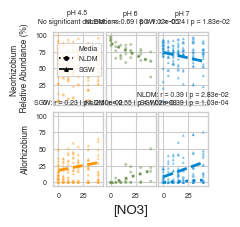

Neorhizobium:
NLDM pH 4.5: y = 0.19x + 44.74 | r = 0.10 | p = 5.94e-01
SGW pH 4.5: y = -0.23x + 62.10 | r = -0.15 | p = 1.51e-01
NLDM pH 6: y = -0.70x + 87.55 | r = -0.69 | p = 1.02e-05
NLDM pH 7: y = 0.13x + 74.77 | r = 0.16 | p = 3.93e-01
SGW pH 7: y = -0.33x + 74.13 | r = -0.24 | p = 1.83e-02

Allorhizobium:
NLDM pH 4.5: y = -0.00x + 2.42 | r = -0.01 | p = 9.62e-01
SGW pH 4.5: y = 0.30x + 18.03 | r = 0.23 | p = 2.50e-02
NLDM pH 6: y = 0.47x + -1.17 | r = 0.55 | p = 1.02e-03
NLDM pH 7: y = 0.09x + 0.05 | r = 0.39 | p = 2.83e-02
SGW pH 7: y = 0.54x + 8.33 | r = 0.39 | p = 1.03e-04


In [96]:
#Make the same plot as above but with a different orientation for Figure 1

mpl.rcParams['font.family'] = 'Helvetica' #sns.set_style resets the font to Arial, so this line needs to be copied any time the style is changed
mpl.rcParams['pdf.fonttype'] = 42

def calc_plot_linear_regression_for_B1_B2():

    #bin_abunds_df_rel_info is a melted df with each line having relative abundance for a single sample linked with metadata
    df1 = bin_abunds_df_rel_info[bin_abunds_df_rel_info['bins']=='Bin_1'].copy(deep=True) #Subset the df for the bin of interest
    df1_NLDM = df1[df1['Media']=='NLDM'] #Split the data by medium to calculate correlations separately; create the NLDM df
    df1_SGW = df1[df1['Media']=='SGW'] #Create the SGW df

    #Create dfs for each pH with both media for plotting all the data together
    df1_4 = df1[df1['pH']==4.5]
    df1_6 = df1[df1['pH']==6]
    df1_7 = df1[df1['pH']==7]

    #Run the linear regressions for the NLDM data to read in later
    df1_4_NLDM = df1_NLDM[df1_NLDM['pH']==4.5]
    df1_6_NLDM = df1_NLDM[df1_NLDM['pH']==6]
    df1_7_NLDM = df1_NLDM[df1_NLDM['pH']==7]

    x_series1_4_NLDM = df1_4_NLDM['[NO3]'] #[NO3] range list
    y_series1_4_NLDM = df1_4_NLDM['value'] #relative abundance data

    x_series1_6_NLDM = df1_6_NLDM['[NO3]'] #[NO3] range list
    y_series1_6_NLDM = df1_6_NLDM['value'] #relative abundance data

    x_series1_7_NLDM = df1_7_NLDM['[NO3]'] #[NO3] range list
    y_series1_7_NLDM = df1_7_NLDM['value'] #relative abundance data

    #Do the linear regression to create results objects for each pH
    results1_4_NLDM = linregress(x=x_series1_4_NLDM,y=y_series1_4_NLDM)
    pval1_4_NLDM = results1_4_NLDM.pvalue
    rval1_4_NLDM = results1_4_NLDM.rvalue
    r2val1_4_NLDM = rval1_4_NLDM*rval1_4_NLDM
    slope1_4_NLDM = results1_4_NLDM.slope
    intercept1_4_NLDM = results1_4_NLDM.intercept

    results1_6_NLDM = linregress(x=x_series1_6_NLDM,y=y_series1_6_NLDM)
    pval1_6_NLDM = results1_6_NLDM.pvalue
    rval1_6_NLDM = results1_6_NLDM.rvalue
    r2val1_6_NLDM = rval1_6_NLDM*rval1_6_NLDM
    slope1_6_NLDM = results1_6_NLDM.slope
    intercept1_6_NLDM = results1_6_NLDM.intercept


    results1_7_NLDM = linregress(x=x_series1_7_NLDM,y=y_series1_7_NLDM)
    pval1_7_NLDM = results1_7_NLDM.pvalue
    rval1_7_NLDM = results1_7_NLDM.rvalue
    r2val1_7_NLDM = rval1_7_NLDM*rval1_7_NLDM
    slope1_7_NLDM = results1_7_NLDM.slope
    intercept1_7_NLDM = results1_7_NLDM.intercept


    #Repeat for SGW but only for pH 4.5 and 7
    df1_4_SGW = df1_SGW[df1_SGW['pH']==4.5]
    df1_7_SGW = df1_SGW[df1_SGW['pH']==7]

    x_series1_4_SGW = df1_4_SGW['[NO3]'] #[NO3] range list
    y_series1_4_SGW = df1_4_SGW['value'] #relative abundance data

    x_series1_7_SGW = df1_7_SGW['[NO3]'] #[NO3] range list
    y_series1_7_SGW = df1_7_SGW['value'] #relative abundance data

    #Do the linear regression to create results objects for each pH
    results1_4_SGW = linregress(x=x_series1_4_SGW,y=y_series1_4_SGW)
    pval1_4_SGW = results1_4_SGW.pvalue
    rval1_4_SGW = results1_4_SGW.rvalue
    r2val1_4_SGW = rval1_4_SGW*rval1_4_SGW
    slope1_4_SGW = results1_4_SGW.slope
    intercept1_4_SGW = results1_4_SGW.intercept

    results1_7_SGW = linregress(x=x_series1_7_SGW,y=y_series1_7_SGW)
    pval1_7_SGW = results1_7_SGW.pvalue
    rval1_7_SGW = results1_7_SGW.rvalue
    r2val1_7_SGW = rval1_7_SGW*rval1_7_SGW
    slope1_7_SGW = results1_7_SGW.slope
    intercept1_7_SGW = results1_7_SGW.intercept

    #bin_abunds_df_rel_info is a melted df with each line having relative abundance for a single sample linked with metadata
    df2 = bin_abunds_df_rel_info[bin_abunds_df_rel_info['bins']=='Bin_2'].copy(deep=True) #Subset the df for the bin of interest
    df2_NLDM = df2[df2['Media']=='NLDM'] #Split the data by medium to calculate correlations separately; create the NLDM df
    df2_SGW = df2[df2['Media']=='SGW'] #Create the SGW df

    #Create dfs for each pH with both media for plotting all the data together
    df2_4 = df2[df2['pH']==4.5]
    df2_6 = df2[df2['pH']==6]
    df2_7 = df2[df2['pH']==7]

    #Run the linear regressions for the NLDM data to read in later
    df2_4_NLDM = df2_NLDM[df2_NLDM['pH']==4.5]
    df2_6_NLDM = df2_NLDM[df2_NLDM['pH']==6]
    df2_7_NLDM = df2_NLDM[df2_NLDM['pH']==7]

    x_series2_4_NLDM = df2_4_NLDM['[NO3]'] #[NO3] range list
    y_series2_4_NLDM = df2_4_NLDM['value'] #relative abundance data

    x_series2_6_NLDM = df2_6_NLDM['[NO3]'] #[NO3] range list
    y_series2_6_NLDM = df2_6_NLDM['value'] #relative abundance data

    x_series2_7_NLDM = df2_7_NLDM['[NO3]'] #[NO3] range list
    y_series2_7_NLDM = df2_7_NLDM['value'] #relative abundance data

    #Do the linear regression to create results objects for each pH
    results2_4_NLDM = linregress(x=x_series2_4_NLDM,y=y_series2_4_NLDM)
    pval2_4_NLDM = results2_4_NLDM.pvalue
    rval2_4_NLDM = results2_4_NLDM.rvalue
    r2val2_4_NLDM = rval2_4_NLDM*rval2_4_NLDM
    slope2_4_NLDM = results2_4_NLDM.slope
    intercept2_4_NLDM = results2_4_NLDM.intercept

    results2_6_NLDM = linregress(x=x_series2_6_NLDM,y=y_series2_6_NLDM)
    pval2_6_NLDM = results2_6_NLDM.pvalue
    rval2_6_NLDM = results2_6_NLDM.rvalue
    r2val2_6_NLDM = rval2_6_NLDM*rval2_6_NLDM
    slope2_6_NLDM = results2_6_NLDM.slope
    intercept2_6_NLDM = results2_6_NLDM.intercept


    results2_7_NLDM = linregress(x=x_series2_7_NLDM,y=y_series2_7_NLDM)
    pval2_7_NLDM = results2_7_NLDM.pvalue
    rval2_7_NLDM = results2_7_NLDM.rvalue
    r2val2_7_NLDM = rval2_7_NLDM*rval2_7_NLDM
    slope2_7_NLDM = results2_7_NLDM.slope
    intercept2_7_NLDM = results2_7_NLDM.intercept


    #Repeat for SGW but only for pH 4.5 and 7
    df2_4_SGW = df2_SGW[df2_SGW['pH']==4.5]
    df2_7_SGW = df2_SGW[df2_SGW['pH']==7]

    x_series2_4_SGW = df2_4_SGW['[NO3]'] #[NO3] range list
    y_series2_4_SGW = df2_4_SGW['value'] #relative abundance data

    x_series2_7_SGW = df2_7_SGW['[NO3]'] #[NO3] range list
    y_series2_7_SGW = df2_7_SGW['value'] #relative abundance data

    #Do the linear regression to create results objects for each pH
    results2_4_SGW = linregress(x=x_series2_4_SGW,y=y_series2_4_SGW)
    pval2_4_SGW = results2_4_SGW.pvalue
    rval2_4_SGW = results2_4_SGW.rvalue
    r2val2_4_SGW = rval2_4_SGW*rval2_4_SGW
    slope2_4_SGW = results2_4_SGW.slope
    intercept2_4_SGW = results2_4_SGW.intercept

    results2_7_SGW = linregress(x=x_series2_7_SGW,y=y_series2_7_SGW)
    pval2_7_SGW = results2_7_SGW.pvalue
    rval2_7_SGW = results2_7_SGW.rvalue
    r2val2_7_SGW = rval2_7_SGW*rval2_7_SGW
    slope2_7_SGW = results2_7_SGW.slope
    intercept2_7_SGW = results2_7_SGW.intercept

    media_markers = {'NLDM':'o','SGW':'^'}

    #Set up figure
    #sns.set_style('whitegrid')
    fig,ax = plt.subplots(ncols=3,nrows=2,figsize=(2,2),sharex=True,sharey=True)

    #pH 4.5 panel
    sns.scatterplot(df1_4,x='[NO3]',y='value',color='xkcd:tangerine',style='Media',markers=media_markers,s=5,alpha=0.5,ax=ax[0,0],legend=False)
    ax[0,0].set_ylim((-5,105))
    ax[0,0].set_ylabel('')
    ax[0,0].set_ylabel('Neorhizobium \n Relative Abundance (%)',fontsize=6)
    #ax[0,0].set_xlabel('                              [NO3-] (mM)',fontsize=14)

    #Add p-value conditional options. 
    #If p > 0.05, don't draw line and don't print equation
    if pval1_4_NLDM <= 0.05:
        ax[0,0].plot(x_series1_4_NLDM.unique(), slope1_4_NLDM*x_series1_4_NLDM.unique() + intercept1_4_NLDM,color='xkcd:tangerine',ls=':',lw=2)
    if pval1_4_SGW <= 0.05:
        ax[0,0].plot(x_series1_4_SGW.unique(), slope1_4_SGW*x_series1_4_SGW.unique() + intercept1_4_SGW,color='xkcd:tangerine',ls='--',lw=2)
    if pval1_4_NLDM <= 0.05 and pval1_4_SGW <= 0.05:
        ax[0,0].set_title(f'pH 4.5 \n NLDM: r = {rval1_4_NLDM:.2f} | p = {pval1_4_NLDM:.2e} \n \
                        SGW: r = {rval1_4_SGW:.2f} | p = {pval1_4_SGW:.2e}',fontsize=5)
    elif pval1_4_NLDM <= 0.05 and pval1_4_SGW > 0.05:
        ax[0,0].set_title(f'pH 4.5 \n NLDM: r = {rval1_4_NLDM:.2f} | p = {pval1_4_NLDM:.2e}',fontsize=5)
    elif pval1_4_NLDM > 0.05 and pval1_4_SGW <= 0.05:
        ax[0,0].set_title(f'pH 4.5 \n SGW: r = {rval1_4_SGW:.2f} | p = {pval1_4_SGW:.2e}',fontsize=5)
    elif pval1_4_NLDM > 0.05 and pval1_4_SGW > 0.05:
        ax[0,0].set_title('pH 4.5 \n No significant correlations.',fontsize=5)

    #pH 6 panel
    sns.scatterplot(df1_6,x='[NO3]',y='value',color='xkcd:moss',style='Media',markers=media_markers,s=5,alpha=0.5,ax=ax[0,1],legend=False)
    ax[0,1].set_ylabel('Relative Abundance (%)',fontsize=14)
    #ax[0,1].set_xlabel(r'[NO$_3$$^-$]',fontsize=12)

    if pval1_6_NLDM <= 0.05:
        ax[0,1].plot(x_series1_6_NLDM.unique(), slope1_6_NLDM*x_series1_6_NLDM.unique() + intercept1_6_NLDM,color='xkcd:moss',ls=':',lw=2)
    if pval1_6_NLDM <= 0.05:
        ax[0,1].set_title(f'pH 6 \n NLDM: r = {rval1_6_NLDM:.2f} | p = {pval1_6_NLDM:.2e}',fontsize=5)
    elif pval1_6_NLDM > 0.05:
        ax[0,1].set_title('pH 6 \n No significant correlations.',fontsize=5)

    #pH 7 panel
    sns.scatterplot(df1_7,x='[NO3]',y='value',color='xkcd:cerulean',style='Media',markers=media_markers,s=5,alpha=0.5,ax=ax[0,2],legend=False)
    ax[0,2].set_ylabel('')
    #ax[0,2].set_xlabel(r'[NO$_3$$^-$]',fontsize=12)

    if pval1_7_NLDM <= 0.05:
        ax[0,2].plot(x_series1_7_NLDM.unique(), slope1_7_NLDM*x_series1_7_NLDM.unique() + intercept1_7_NLDM,color='xkcd:cerulean',ls=':',lw=2)
    if pval1_7_SGW <= 0.05:
        ax[0,2].plot(x_series1_7_SGW.unique(), slope1_7_SGW*x_series1_7_SGW.unique() + intercept1_7_SGW,color='xkcd:cerulean',ls='--',lw=2)
    
    if pval1_7_NLDM <= 0.05 and pval1_7_SGW <= 0.05:
        ax[0,2].set_title(f'pH 7 \n NLDM: r = {rval1_7_NLDM:.2f} | p = {pval1_7_NLDM:.2e} \n \
                          SGW: r = {rval1_7_SGW:.2f} | p = {pval1_7_SGW:.2e}',fontsize=5)
    elif pval1_7_NLDM <= 0.05 and pval1_7_SGW > 0.05:
        ax[0,2].set_title(f'pH 7 \n NLDM: r = {rval1_7_NLDM:.2f} | p = {pval1_7_NLDM:.2e}',fontsize=5)
    elif pval1_7_NLDM > 0.05 and pval1_7_SGW <= 0.05:
        ax[0,2].set_title(f'pH 7 \n SGW: r = {rval1_7_SGW:.2f} | p = {pval1_7_SGW:.2e}',fontsize=5)
    elif pval1_7_NLDM > 0.05 and pval1_7_SGW > 0.05:
        ax[0,2].set_title('pH 7 \n No significant correlations.',fontsize=5)


    #pH 4.5 panel
    sns.scatterplot(df2_4,x='[NO3]',y='value',color='xkcd:tangerine',style='Media',markers=media_markers,s=5,alpha=0.5,ax=ax[1,0],legend=False)
    ax[1,0].set_ylim((-5,105))
    ax[1,0].set_ylabel('Allorhizobium',fontsize=6)
    ax[1,0].set_xlabel('')

    #Add p-value conditional options. 
    #If p > 0.05, don't draw line and don't print equation
    if pval2_4_NLDM <= 0.05:
        ax[1,0].plot(x_series2_4_NLDM.unique(), slope2_4_NLDM*x_series2_4_NLDM.unique() + intercept2_4_NLDM,color='xkcd:tangerine',ls=':',lw=2)
    if pval2_4_SGW <= 0.05:
        ax[1,0].plot(x_series2_4_SGW.unique(), slope2_4_SGW*x_series2_4_SGW.unique() + intercept2_4_SGW,color='xkcd:tangerine',ls='--',lw=2)
    if pval2_4_NLDM <= 0.05 and pval2_4_SGW <= 0.05:
        ax[1,0].set_title(f'NLDM: r = {rval2_4_NLDM:.2f} | p = {pval2_4_NLDM:.2e} \n \
                          SGW: r = {rval2_4_SGW:.2f} | p = {pval2_4_SGW:.2e}',fontsize=5)
    elif pval2_4_NLDM <= 0.05 and pval2_4_SGW > 0.05:
        ax[1,0].set_title(f'NLDM: r = {rval2_4_NLDM:.2f} | p = {pval2_4_NLDM:.2e}',fontsize=5)
    elif pval2_4_NLDM > 0.05 and pval2_4_SGW <= 0.05:
        ax[1,0].set_title(f'SGW: r = {rval2_4_SGW:.2f} | p = {pval2_4_SGW:.2e}',fontsize=5)
    elif pval2_4_NLDM > 0.05 and pval2_4_SGW > 0.05:
        ax[1,0].set_title('No significant correlations.',fontsize=5)

    #pH 6 panel
    sns.scatterplot(df2_6,x='[NO3]',y='value',color='xkcd:moss',style='Media',markers=media_markers,s=5,alpha=0.5,ax=ax[1,1],legend=False)

    if pval2_6_NLDM <= 0.05:
        ax[1,1].plot(x_series2_6_NLDM.unique(), slope2_6_NLDM*x_series2_6_NLDM.unique() + intercept2_6_NLDM,color='xkcd:moss',ls=':',lw=2)
    if pval2_6_NLDM <= 0.05:
        ax[1,1].set_title(f'NLDM: r = {rval2_6_NLDM:.2f} | p = {pval2_6_NLDM:.2e}',fontsize=5)
    elif pval2_6_NLDM > 0.05:
        ax[1,1].set_title('No significant correlations.',fontsize=5)

    #pH 7 panel
    sns.scatterplot(df2_7,x='[NO3]',y='value',color='xkcd:cerulean',style='Media',markers=media_markers,s=5,alpha=0.5,ax=ax[1,2],legend=False)
    ax[1,2].set_xlabel('')

    if pval2_7_NLDM <= 0.05:
        ax[1,2].plot(x_series2_7_NLDM.unique(), slope2_7_NLDM*x_series2_7_NLDM.unique() + intercept2_7_NLDM,color='xkcd:cerulean',ls=':',lw=2)
    if pval2_7_SGW <= 0.05:
        ax[1,2].plot(x_series2_7_SGW.unique(), slope2_7_SGW*x_series2_7_SGW.unique() + intercept2_7_SGW,color='xkcd:cerulean',ls='--',lw=2)
    
    if pval2_7_NLDM <= 0.05 and pval2_7_SGW <= 0.05:
        ax[1,2].set_title(f'NLDM: r = {rval2_7_NLDM:.2f} | p = {pval2_7_NLDM:.2e} \n SGW: r = {rval2_7_SGW:.2f} | p = {pval2_7_SGW:.2e}',fontsize=5)
    elif pval2_7_NLDM <= 0.05 and pval2_7_SGW > 0.05:
        ax[1,2].set_title(f'NLDM: r = {rval2_7_NLDM:.2f} | p = {pval2_7_NLDM:.2e}',fontsize=5)
    elif pval2_7_NLDM > 0.05 and pval2_7_SGW <= 0.05:
        ax[1,2].set_title(f'SGW: r = {rval2_7_SGW:.2f} | p = {pval2_7_SGW:.2e}',fontsize=5)
    elif pval2_7_NLDM > 0.05 and pval2_7_SGW > 0.05:
        ax[1,2].set_title('No significant correlations.',fontsize=5)

    #Custom legend set up
    linreg_legend_handles = [Line2D([0], [0], color='black', label='Media', marker='', markerfacecolor=None, markersize=2.5,linestyle=''),
        Line2D([0], [0], color='black', label='NLDM', marker='o', markerfacecolor='black', markersize=2.5,linestyle=':'),
        Line2D([0], [0], color='black', label='SGW', marker='^', markerfacecolor='black', markersize=2.5,linestyle='--')]

    ax[0,0].tick_params(axis='both',labelsize=5,pad=0.01)
    ax[1,0].tick_params(axis='both',labelsize=5,pad=0.01)
    ax[1,1].tick_params(axis='x',labelsize=5,pad=0.01)
    ax[1,2].tick_params(axis='x',labelsize=5,pad=0.01)

    for x in range(2):
        for y in range(3):
            ax[x,y].set_xlim(-5,45)
            ax[x,y].set_ylim(-5,105)


    plt.legend(bbox_to_anchor=(-1.075,2),
               handles=linreg_legend_handles,
               fontsize=5)

    plt.subplots_adjust(hspace=0.1,wspace=0.05)

    #plt.savefig('../figs/pH_NO3_corr_plot_horizontal_20261002.pdf',dpi=300,bbox_inches='tight')
    plt.show()

    #Print out all of the results so we don't rely only on the figure for the data
    print('Neorhizobium:')
    print(f'NLDM pH 4.5: y = {slope1_4_NLDM:.2f}x + {intercept1_4_NLDM:.2f} | r = {rval1_4_NLDM:.2f} | p = {pval1_4_NLDM:.2e}')
    print(f'SGW pH 4.5: y = {slope1_4_SGW:.2f}x + {intercept1_4_SGW:.2f} | r = {rval1_4_SGW:.2f} | p = {pval1_4_SGW:.2e}')
    print(f'NLDM pH 6: y = {slope1_6_NLDM:.2f}x + {intercept1_6_NLDM:.2f} | r = {rval1_6_NLDM:.2f} | p = {pval1_6_NLDM:.2e}')
    print(f'NLDM pH 7: y = {slope1_7_NLDM:.2f}x + {intercept1_7_NLDM:.2f} | r = {rval1_7_NLDM:.2f} | p = {pval1_7_NLDM:.2e}')
    print(f'SGW pH 7: y = {slope1_7_SGW:.2f}x + {intercept1_7_SGW:.2f} | r = {rval1_7_SGW:.2f} | p = {pval1_7_SGW:.2e}')
    print('')
    print('Allorhizobium:')
    print(f'NLDM pH 4.5: y = {slope2_4_NLDM:.2f}x + {intercept2_4_NLDM:.2f} | r = {rval2_4_NLDM:.2f} | p = {pval2_4_NLDM:.2e}')
    print(f'SGW pH 4.5: y = {slope2_4_SGW:.2f}x + {intercept2_4_SGW:.2f} | r = {rval2_4_SGW:.2f} | p = {pval2_4_SGW:.2e}')
    print(f'NLDM pH 6: y = {slope2_6_NLDM:.2f}x + {intercept2_6_NLDM:.2f} | r = {rval2_6_NLDM:.2f} | p = {pval2_6_NLDM:.2e}')
    print(f'NLDM pH 7: y = {slope2_7_NLDM:.2f}x + {intercept2_7_NLDM:.2f} | r = {rval2_7_NLDM:.2f} | p = {pval2_7_NLDM:.2e}')
    print(f'SGW pH 7: y = {slope2_7_SGW:.2f}x + {intercept2_7_SGW:.2f} | r = {rval2_7_SGW:.2f} | p = {pval2_7_SGW:.2e}')

calc_plot_linear_regression_for_B1_B2()

In [97]:
#Let's do something else fun with the data! Maybe an ordination to see how the samples vary by composition?
bin_abunds_pca_df = pd.read_csv('./data/mean_coverage_Q2Q3.txt',sep='\t',index_col='bins')
#bin_abunds_pca_df = bin_abunds_pca_df.div(bin_abunds_pca_df.sum()).mul(100) #Relativize the data? No.
bin_abunds_pca_df = np.log10(bin_abunds_pca_df + 1) #log-normalization of the data

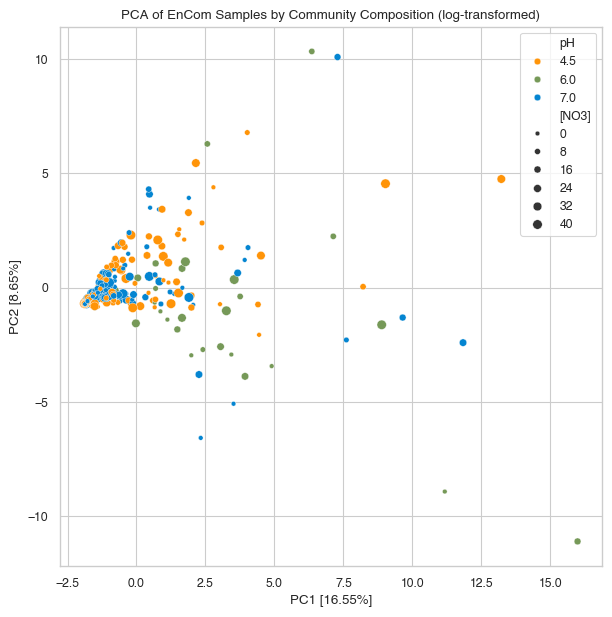

In [98]:
#Let's just run a PCA to see if the samples really look different this way
def run_pca(df):
    data_df = df.T
    samples = data_df.index #we're going to use these later for better plotting
    scaling=StandardScaler() #set up scaling
    scaling.fit(data_df) 
    Scaled_data=scaling.transform(data_df) #fit transform the data
    principal=PCA(n_components=2) #set up PCA parameters
    principal.fit(Scaled_data) #Fit the data into the PCA
    x=principal.transform(Scaled_data) #Transform the data into 2 components of the PCA
    PC1_val = principal.explained_variance_ratio_[0]
    PC2_val = principal.explained_variance_ratio_[1]
    df_x = pd.DataFrame(x,columns=['PC1','PC2']) #set up df with pca results
    df_x.index = samples

    df_x_w_info = df_x.reset_index().rename({'index':'samples'},axis=1).merge(sample_info_df,how='left',on='samples')

    plt.figure(figsize=(7,7))
    sns.scatterplot(df_x_w_info,x='PC1',y='PC2',hue='pH',size='[NO3]',palette=pH_palette)
    plt.xlabel(f'PC1 [{PC1_val*100:.2f}%]')
    plt.ylabel(f'PC2 [{PC2_val*100:.2f}%]')
    plt.title('PCA of EnCom Samples by Community Composition (log-transformed)')
    plt.show()

    #return df_x_w_info

run_pca(bin_abunds_pca_df)

#What a mess.

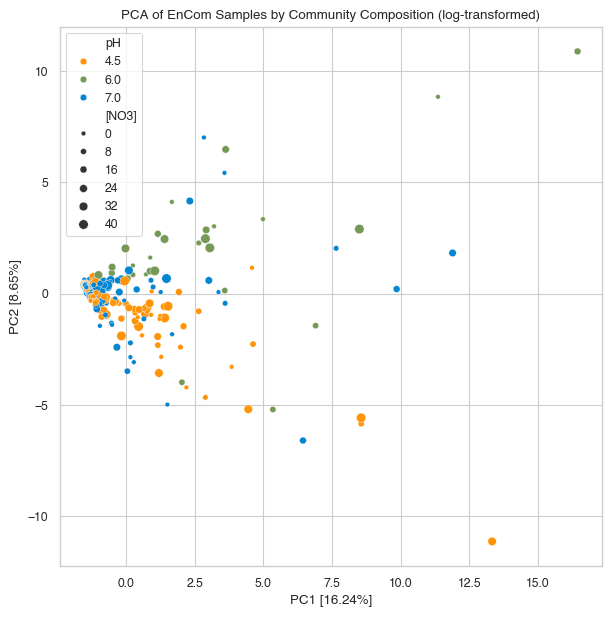

In [99]:
#Maybe the dominance of Neo and Allo is ameliorating the separation?
run_pca(bin_abunds_pca_df.drop(['Bin_1','Bin_2']))
#probably at least a little, but still mostly the same

### Alpha diversity analysis of EnCom communities based on relative abundance of bins

In [100]:
#Let's do some alpha diversity calculations out of curiosity
#These metrics are implemented using scikit-bio: sobs (richness), chao1 (richness), shannon (diversity), simpson (diversity), simpson_e (evenness), simpson_d (dominance)
#Each of these is called like sobs([list of counts])


#Store alpha div stats for each sample in lists
sobs_list = []
chao1_list = []
shannon_list = []
simpson_list = []
simpson_e_list = []
simpson_d_list = []

#calculate for each sample
for sample in sample_order:
    x = bin_abunds_df_rel[sample] #count array for a sample
    r1 = sobs(x)
    sobs_list.append(r1)
    r2 = chao1(x)
    chao1_list.append(r2)
    d1 = shannon(x)
    shannon_list.append(d1)
    d2 = simpson(x)
    simpson_list.append(d2)
    e1 = simpson_e(x)
    simpson_e_list.append(e1)
    e2= simpson_d(x)
    simpson_d_list.append(e2)

#Make a df with the results
alpha_stats_df = pd.DataFrame({'samples':sample_order,'sobs':sobs_list,'chao1':chao1_list,'shannon':shannon_list,'simpson':simpson_list,'simpson_evenness':simpson_e_list,'simpson_dominance':simpson_d_list})

In [101]:
#Let's do some statistical comparisons to see if any of these stats vary by conditions
alpha_stats_info_df = alpha_stats_df.merge(sample_info_df,on='samples',how='left')#.groupby('C source')[['sobs','chao1','shannon','simpson','simpson_evenness','simpson_dominance']].apply(np.mean,axis=0)

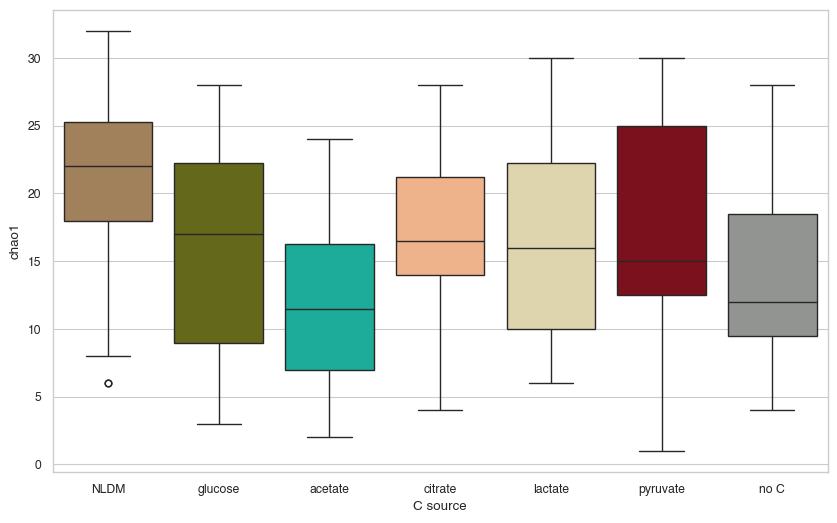

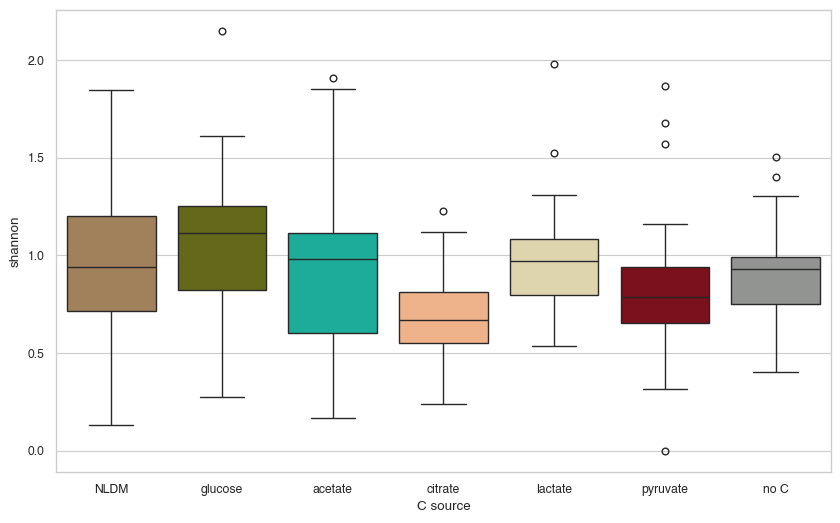

In [102]:
#Richness by C source
plt.figure(figsize=(10,6))
sns.boxplot(alpha_stats_info_df,x='C source',hue='C source',y='chao1',palette=c_palette)
plt.show()

#Diversity by C source
plt.figure(figsize=(10,6))
sns.boxplot(alpha_stats_info_df,x='C source',hue='C source',y='shannon',palette=c_palette)
plt.show()

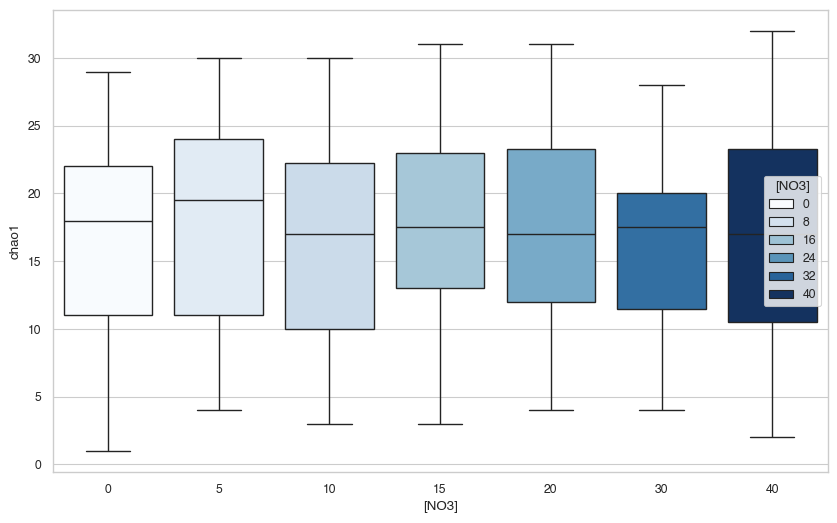

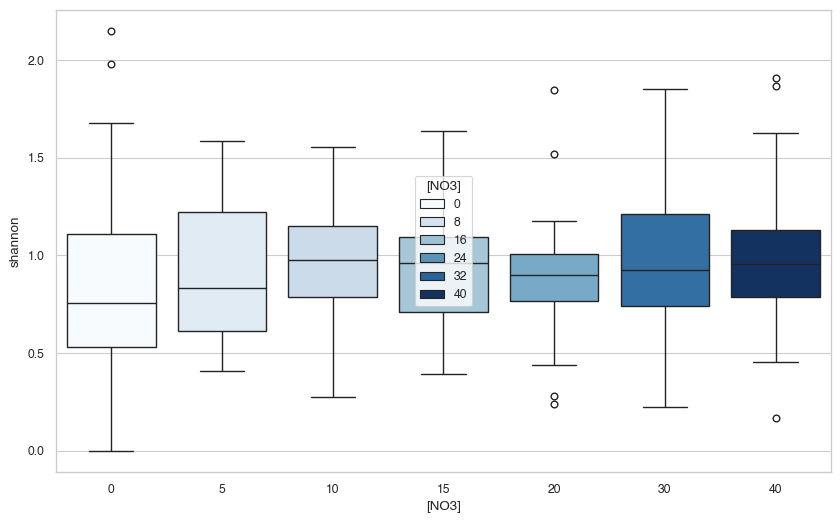

In [103]:
#Richness and diversity by [NO3]
plt.figure(figsize=(10,6))
sns.boxplot(alpha_stats_info_df,x='[NO3]',hue='[NO3]',y='chao1',palette=no3_palette)
plt.show()

plt.figure(figsize=(10,6))
sns.boxplot(alpha_stats_info_df,x='[NO3]',hue='[NO3]',y='shannon',palette=no3_palette)
plt.show()

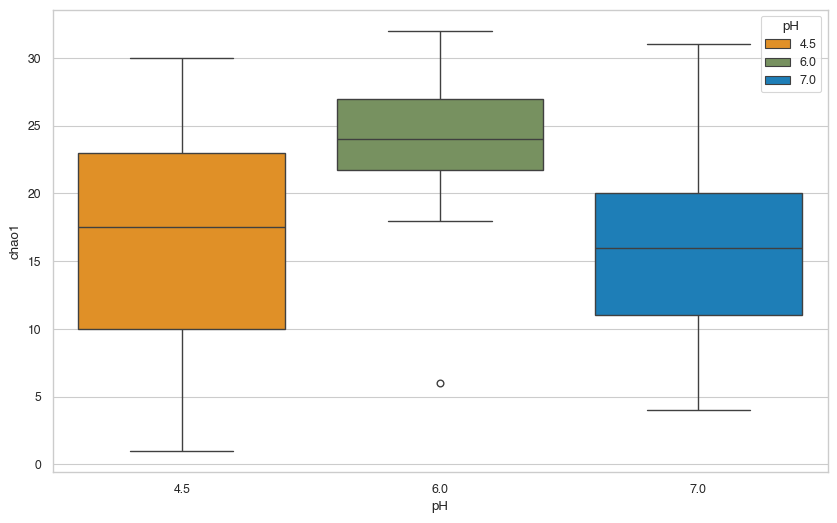

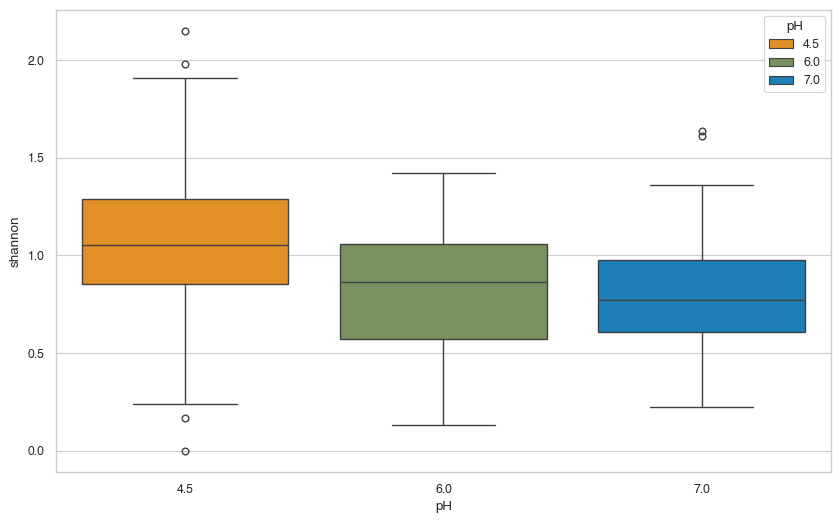

In [104]:
#Richness and diversity by pH
plt.figure(figsize=(10,6))
sns.boxplot(alpha_stats_info_df,x='pH',hue='pH',y='chao1',palette=pH_palette)
plt.show()

plt.figure(figsize=(10,6))
sns.boxplot(alpha_stats_info_df,x='pH',hue='pH',y='shannon',palette=pH_palette)
plt.show()

In [105]:
#Check whether stats are significantly different by pH
for pH_1 in pH_palette.keys():
    for pH_2 in pH_palette.keys():
        if pH_1 != pH_2:
            a_stats_pH_1 = alpha_stats_info_df[alpha_stats_info_df['pH']==pH_1]
            a_stats_pH_2 = alpha_stats_info_df[alpha_stats_info_df['pH']==pH_2]
            chao1_stat,chao1_p = ttest_ind(a_stats_pH_1['chao1'],a_stats_pH_2['chao1'],nan_policy='omit')
            shannon_stat,shannon_p = ttest_ind(a_stats_pH_1['shannon'],a_stats_pH_2['shannon'],nan_policy='omit')
            if chao1_p < 0.05:
                print(f'chao1: \t\t pH {pH_1} mean = {a_stats_pH_1['chao1'].mean():.2f} \t pH {pH_2} mean = {a_stats_pH_2['chao1'].mean():.2f} \t p = {chao1_p:.2e}')

            if shannon_p < 0.05:
                print(f'shannon: \t pH {pH_1} mean = {a_stats_pH_1['shannon'].mean():.2f} \t pH {pH_2} mean = {a_stats_pH_2['shannon'].mean():.2f} \t p = {shannon_p:.2e}')

chao1: 		 pH 4.5 mean = 16.52 	 pH 6 mean = 23.94 	 p = 9.90e-07
shannon: 	 pH 4.5 mean = 1.07 	 pH 6 mean = 0.80 	 p = 4.54e-04
shannon: 	 pH 4.5 mean = 1.07 	 pH 7 mean = 0.79 	 p = 8.11e-11
chao1: 		 pH 6 mean = 23.94 	 pH 4.5 mean = 16.52 	 p = 9.90e-07
shannon: 	 pH 6 mean = 0.80 	 pH 4.5 mean = 1.07 	 p = 4.54e-04
chao1: 		 pH 6 mean = 23.94 	 pH 7 mean = 15.97 	 p = 6.40e-10
shannon: 	 pH 7 mean = 0.79 	 pH 4.5 mean = 1.07 	 p = 8.11e-11
chao1: 		 pH 7 mean = 15.97 	 pH 6 mean = 23.94 	 p = 6.40e-10


In [106]:
#Check differences by [NO3]
no3_concs = [0,5,10,15,20,30,40]
no3_stats = []
for no3_1 in no3_concs:
    for no3_2 in no3_concs:
        if no3_1 != no3_2:
            a_stats_no3_1 = alpha_stats_info_df[alpha_stats_info_df['[NO3]']==no3_1]
            a_stats_no3_2 = alpha_stats_info_df[alpha_stats_info_df['[NO3]']==no3_2]
            chao1_stat,chao1_p = ttest_ind(a_stats_no3_1['chao1'],a_stats_no3_2['chao1'],nan_policy='omit')
            shannon_stat,shannon_p = ttest_ind(a_stats_no3_1['shannon'],a_stats_no3_2['shannon'],nan_policy='omit')
            if chao1_p < 0.05:
                print(f'chao1: {no3_1} mean = {a_stats_no3_1['chao1'].mean():.2f} & {no3_2} mean = {a_stats_no3_2['chao1'].mean():.2f} | p = {chao1_p:.2e}')
                no3_stats.append(0)
            if shannon_p < 0.05:
                print(f'shannon: {no3_1} mean = {a_stats_no3_1['shannon'].mean():.2f} & {no3_2} mean = {a_stats_no3_2['shannon'].mean():.2f} | p = {chao1_p:.2e}')
                no3_stats.append(0)
       
if len(no3_stats) == 0:
    print('No statistical pairwise differences by t-test for [NO3]. Sad.')

No statistical pairwise differences by t-test for [NO3]. Sad.


In [107]:
#Check differences between each C source
for c1 in c_palette.keys():
    for c2 in c_palette.keys():
        if c1 != c2:
            a_stats_c1 = alpha_stats_info_df[alpha_stats_info_df['C source']==c1]
            a_stats_c2 = alpha_stats_info_df[alpha_stats_info_df['C source']==c2]
            chao1_stat,chao1_p = ttest_ind(a_stats_c1['chao1'],a_stats_c2['chao1'],nan_policy='omit')
            shannon_stat,shannon_p = ttest_ind(a_stats_c1['shannon'],a_stats_c2['shannon'],nan_policy='omit')
            if chao1_p < 0.05:
                print(f'chao1: \t\t {c1} mean = {a_stats_c1['chao1'].mean():.2f} \t {c2} mean = {a_stats_c2['chao1'].mean():.2f} \t p = {chao1_p:.2e}')
            if shannon_p < 0.05:
                print(f'shannon: \t {c1} mean = {a_stats_c1['shannon'].mean():.2f} \t {c2} mean = {a_stats_c2['shannon'].mean():.2f} \t p = {shannon_p:.2e}')
            if chao1_p > 0.05 and shannon_p > 0.05:
                next

chao1: 		 acetate mean = 11.47 	 glucose mean = 16.03 	 p = 1.49e-02
chao1: 		 acetate mean = 11.47 	 citrate mean = 16.75 	 p = 1.56e-03
shannon: 	 acetate mean = 0.91 	 citrate mean = 0.70 	 p = 2.06e-02
chao1: 		 acetate mean = 11.47 	 pyruvate mean = 17.19 	 p = 1.63e-03
chao1: 		 acetate mean = 11.47 	 lactate mean = 16.41 	 p = 4.09e-03
chao1: 		 acetate mean = 11.47 	 NLDM mean = 20.90 	 p = 9.41e-12
chao1: 		 glucose mean = 16.03 	 acetate mean = 11.47 	 p = 1.49e-02
shannon: 	 glucose mean = 1.06 	 citrate mean = 0.70 	 p = 2.32e-05
shannon: 	 glucose mean = 1.06 	 pyruvate mean = 0.83 	 p = 1.58e-02
chao1: 		 glucose mean = 16.03 	 NLDM mean = 20.90 	 p = 4.98e-04
chao1: 		 citrate mean = 16.75 	 acetate mean = 11.47 	 p = 1.56e-03
shannon: 	 citrate mean = 0.70 	 acetate mean = 0.91 	 p = 2.06e-02
shannon: 	 citrate mean = 0.70 	 glucose mean = 1.06 	 p = 2.32e-05
shannon: 	 citrate mean = 0.70 	 lactate mean = 0.99 	 p = 3.25e-05
chao1: 		 citrate mean = 16.75 	 no C mean =

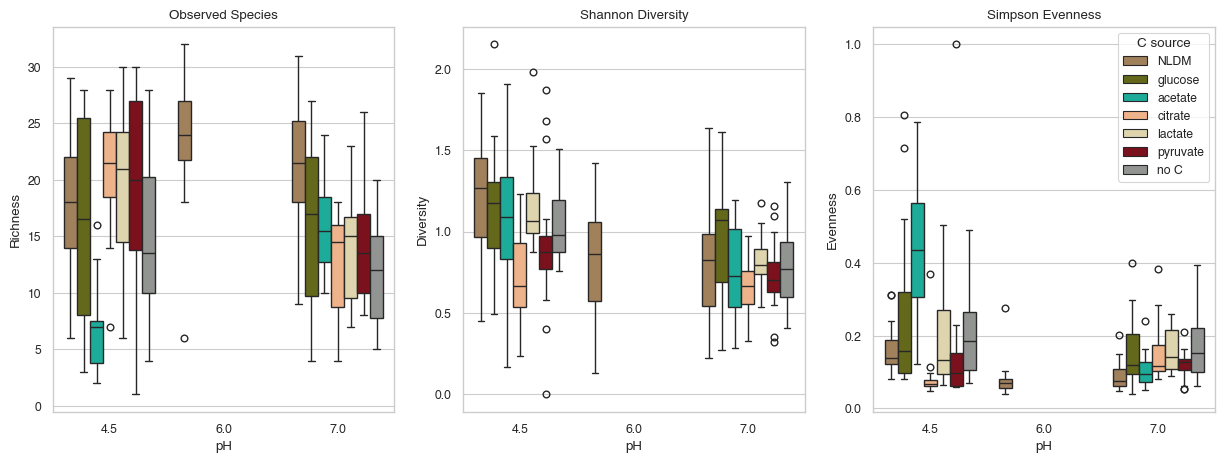

In [108]:
#Plot with only one metric each for richness, diversity, and evenness

fig,ax = plt.subplots(nrows=1,ncols=3,figsize=(15,5))

#sobs
sns.boxplot(alpha_stats_info_df,y='sobs',hue='C source',x='pH',palette=c_palette,ax=ax[0],legend=False)
ax[0].set_title('Observed Species')
ax[0].set_ylabel('Richness')

#shannon
sns.boxplot(alpha_stats_info_df,y='shannon',hue='C source',x='pH',palette=c_palette,ax=ax[1],legend=False)
ax[1].set_title('Shannon Diversity')
ax[1].set_ylabel('Diversity')

#evenness
sns.boxplot(alpha_stats_info_df,y='simpson_evenness',hue='C source',x='pH',palette=c_palette,ax=ax[2],legend=True)
ax[2].set_title('Simpson Evenness')
ax[2].set_ylabel('Evenness')

plt.show()

#A bit messy, but that's biology